# MetaboNet Glucose Prediction Challenge — Exploratory Data Analysis

Deep profile of `data/metabonet_public.parquet` — **154,842,077 rows x 37 columns**,
the training corpus for forecasting CGM glucose 30 / 60 / 90 / 120 minutes ahead.

**How this notebook is organised**

| # | Section | Question it answers |
|---|---|---|
| 0 | Setup | Palette, helpers, column taxonomy |
| 1 | Provenance & load | What is physically in the file, what does it cost to hold |
| 2 | Schema & data types | What is each column, mechanically |
| 3 | Missingness | Where are the NAs, and are they random or structural |
| 4 | Data dictionary | What does each column *mean*, with units |
| 5 | Univariate — numeric | Distribution, skew, zero-inflation, transforms |
| 6 | Univariate — categorical | Cardinality, long tails, label hygiene |
| 7 | Temporal structure | The 5-minute lattice, coverage, gaps, seasonality |
| 8 | Subject-level structure | The real unit of analysis; per-row stats lie |
| 9 | CGM target deep dive | Clinical bands, diurnal profile, dynamics, persistence floor |
| 10 | Relationships | Correlation, cross-correlation, treatment response |
| 11 | Train / test split | Leakage geometry and distribution shift |
| 12 | Data quality register | Every defect found, with severity |
| 13 | Leaderboard subset | Reconstructing the actually-scored slice |
| 14 | Findings | What all of this means for modelling |

> **Runtime.** The full frame is ~61 GB resident and takes ~30 s to load from NVMe.
> Every cell below runs against the whole corpus unless it explicitly says it
> subsamples. End-to-end this notebook is roughly 15-25 minutes on a 96-core box.
> `CFG` in section 0 has the knobs to make it cheaper.

---
## 0 · Setup

Three things get established here and used everywhere after:

1. **A validated colour palette.** Categorical hues are assigned in a fixed order and
   never cycled; magnitude uses a single-hue ramp; signed quantities use a
   blue↔red diverging ramp with a *neutral grey* midpoint so "zero" reads as nothing.
   The dataset has 14 source cohorts — more than the 8 safe categorical slots — so
   cohort is encoded by **position (bars, small multiples)**, never by 14 hues.
2. **A column taxonomy** (`NUM`, `CAT`, `DT`, `FLAG`) derived from dtypes, so later
   sections never hard-code column lists that drift.
3. **Plot helpers** that apply the chrome rules once: hairline solid gridlines,
   recessive axes, no top/right spine, thin marks, selective direct labels.

In [1]:
import warnings, time, math, json, os, gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.ticker import FuncFormatter, MultipleLocator

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

print("pandas", pd.__version__, "| numpy", np.__version__, "| matplotlib", mpl.__version__)

pandas 3.0.3 | numpy 2.4.6 | matplotlib 3.11.0


In [2]:
# ---------------------------------------------------------------- configuration
CFG = dict(
    parquet   = Path("./data/metabonet_public.parquet"),
    holdout   = Path("./data/annual_competition_secret_holdout_set_public.parquet"),
    grid_min  = 5,          # the corpus lattice resolution, verified in section 7
    horizons  = (30, 60, 90, 120),   # competition forecast horizons, minutes
    # sampling knobs -- raise for more fidelity, lower for speed
    n_rows_sample     = 5_000_000,   # generic row subsample for pairwise work
    n_subj_sample     = 120,         # subjects pulled whole for sequence analysis
    n_scatter         = 40_000,      # points drawn in any scatter
    seed              = 0,
)
RNG = np.random.default_rng(CFG["seed"])

In [3]:
# ---------------------------------------------------------------- palette
# Categorical slots, fixed order. Never cycle past slot 8: fold to "Other" or facet.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
          "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
# All-pairs safe subset (scatter / bubble / anything where every pair is adjacent)
SERIES3 = SERIES[:3]

INK        = "#0b0b0b"   # primary text
INK2       = "#52514e"   # secondary text
MUTED      = "#898781"   # axis + tick labels
GRID       = "#e1e0d9"   # hairline gridline
AXIS       = "#c3c2b7"   # baseline
SURFACE    = "#fcfcfb"   # chart surface
FADE       = "#d8d7d0"   # de-emphasised mark

STATUS = dict(good="#0ca30c", warning="#fab219", serious="#ec835a", critical="#d03b3b")

# Sequential: ONE hue, light -> dark. Used for magnitude only.
SEQ_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#9ec5f4", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"])
SEQ_ORANGE = LinearSegmentedColormap.from_list(   # second sequential context only
    "seq_orange", ["#fce0d3", "#f7b391", "#f08a5c", "#eb6834", "#c14f24", "#8f3a1a"])
# Diverging: two opposing hues + NEUTRAL GREY midpoint (never a hue at zero).
DIV_BR = LinearSegmentedColormap.from_list(
    "div_br", ["#104281", "#2a78d6", "#9ec5f4", "#f0efec", "#f3a3a2", "#e34948", "#a02524"])

# Clinical glucose bands (mg/dL) -- these are conventions, not palette choices.
CGM_BANDS = [
    ("Level 2 hypo",  0,   54,  STATUS["critical"]),
    ("Level 1 hypo",  54,  70,  STATUS["serious"]),
    ("In range",      70,  180, STATUS["good"]),
    ("Level 1 hyper", 180, 250, STATUS["warning"]),
    ("Level 2 hyper", 250, 1000, STATUS["critical"]),
]

In [4]:
# ---------------------------------------------------------------- matplotlib chrome
mpl.rcParams.update({
    "figure.facecolor": SURFACE,   "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,  "figure.dpi": 110,
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Segoe UI", "Helvetica", "Arial"],
    "font.size": 9.5,
    "axes.titlesize": 11, "axes.titleweight": "600", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "axes.titlepad": 9,
    "axes.labelsize": 9.5, "axes.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.7, "grid.linestyle": "-",  # solid hairline, never dashed
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "legend.fontsize": 8.5, "legend.labelcolor": INK2,
    "lines.linewidth": 2.0, "lines.markersize": 4,
    "figure.constrained_layout.use": True,
})

def K(v, pos=None):
    """Compact tick formatter: 1_500_000 -> 1.5M."""
    v = float(v)
    for div, suf in ((1e9, "B"), (1e6, "M"), (1e3, "k")):
        if abs(v) >= div:
            return f"{v/div:,.3g}{suf}"
    return f"{v:,.0f}"

KFMT = FuncFormatter(K)

def finish(ax, title=None, sub=None, xlab=None, ylab=None, xgrid=False, ygrid=True):
    """Apply the chrome rules to one axes."""
    if title:
        ax.set_title(title, loc="left")
    if sub:
        ax.text(0, 1.015, sub, transform=ax.transAxes, fontsize=8.5,
                color=MUTED, va="bottom", ha="left")
    ax.set_xlabel(xlab or "");  ax.set_ylabel(ylab or "")
    ax.xaxis.grid(xgrid); ax.yaxis.grid(ygrid)
    return ax

def barh_labels(ax, bars, labels, pad=0.006, color=INK2, fs=8.2):
    """Selective direct labels placed OUTSIDE the bar end so nothing is ever clipped."""
    span = ax.get_xlim()[1] - ax.get_xlim()[0]
    for b, t in zip(bars, labels):
        ax.text(b.get_width() + pad*span, b.get_y() + b.get_height()/2, t,
                va="center", ha="left", fontsize=fs, color=color)

def show(fig=None):
    plt.show()

### 0.1 · Loading the corpus

61 GB resident. Everything downstream reads this one `df`; nothing copies it.

In [5]:
t0 = time.time()
df = pd.read_parquet(CFG["parquet"])
load_s = time.time() - t0

N_ROWS, N_COLS = df.shape
MEM_GB = df.memory_usage(deep=True).sum() / 1e9
DISK_GB = CFG["parquet"].stat().st_size / 1e9

print(f"rows        {N_ROWS:>14,}")
print(f"columns     {N_COLS:>14,}")
print(f"on disk     {DISK_GB:>14.2f} GB   (parquet, compressed)")
print(f"resident    {MEM_GB:>14.2f} GB   ({MEM_GB/DISK_GB:.1f}x inflation)")
print(f"load time   {load_s:>14.1f} s    ({DISK_GB/load_s:.2f} GB/s)")
print(f"bytes/row   {MEM_GB*1e9/N_ROWS:>14.1f}")

rows           154,842,077
columns                 37
on disk               1.36 GB   (parquet, compressed)
resident             60.64 GB   (44.7x inflation)
load time             29.6 s    (0.05 GB/s)
bytes/row            391.6


In [6]:
# ---------------------------------------------------------------- column taxonomy
def _kind(s):
    if pd.api.types.is_datetime64_any_dtype(s):                      return "datetime"
    if pd.api.types.is_bool_dtype(s):                                return "flag"
    if pd.api.types.is_numeric_dtype(s):                             return "numeric"
    return "categorical"

KIND = {c: _kind(df[c]) for c in df.columns}
# is_pregnant arrives as object(None/True/False) -- semantically a flag, not a category.
KIND["is_pregnant"] = "flag"

NUM  = [c for c in df.columns if KIND[c] == "numeric"]
CAT  = [c for c in df.columns if KIND[c] == "categorical"]
DT   = [c for c in df.columns if KIND[c] == "datetime"]
FLAG = [c for c in df.columns if KIND[c] == "flag"]

SUBJ_KEY = ["source_file", "id"]     # the true subject key -- proven in section 8
TARGET   = "CGM"

for name, cols in [("numeric", NUM), ("categorical", CAT), ("datetime", DT), ("flag", FLAG)]:
    print(f"{name:>12} ({len(cols):2d}) : {', '.join(cols)}")

     numeric (17) : CGM, age, air_temp, basal, bolus, calories_burned, carbs, galvanic_skin_response, heartrate, height, insulin, skin_temp, steps, weight, workout_duration, workout_intensity, age_of_diagnosis
 categorical (14) : cgm_device, misc_notes, id, insulin_delivery_algorithm, insulin_delivery_device, insulin_delivery_modality, insulin_type_basal, insulin_type_bolus, meal_label, source_file, workout_label, treatment_group, gender, ethnicity
    datetime ( 3) : date, randomization_date, extension_date
        flag ( 3) : is_pregnant, is_test, subject_split_across_traintest


---
## 1 · Provenance & physical layout

Before touching values: what is actually *in* the file. Parquet metadata is free to
read — it tells us the row-group geometry (which governs how well the file streams),
the per-column compressed footprint (which columns are actually paying rent), and the
writer that produced it.

In [7]:
import pyarrow.parquet as pq

pf = pq.ParquetFile(CFG["parquet"])
meta = pf.metadata

print(f"format version   {meta.format_version}")
print(f"created by       {meta.created_by}")
print(f"row groups       {meta.num_row_groups:,}")
print(f"rows             {meta.num_rows:,}")
print(f"avg rows/group   {meta.num_rows/meta.num_row_groups:,.0f}")
print(f"serialized size  {meta.serialized_size/1e6:.2f} MB (footer)")

format version   2.6
created by       parquet-cpp-arrow version 22.0.0
row groups       149
rows             154,842,077
avg rows/group   1,039,209
serialized size  0.60 MB (footer)


In [8]:
# Per-column compressed / uncompressed footprint, summed across all row groups.
rows = {}
for rg in range(meta.num_row_groups):
    g = meta.row_group(rg)
    for i in range(g.num_columns):
        cc = g.column(i)
        name = cc.path_in_schema
        r = rows.setdefault(name, dict(comp=0, uncomp=0, encodings=set(), codec=cc.compression))
        r["comp"]   += cc.total_compressed_size
        r["uncomp"] += cc.total_uncompressed_size
        r["encodings"].update(str(e) for e in (cc.encodings or ()))

phys = (pd.DataFrame([
            dict(column=k,
                 compressed_MB = v["comp"]/1e6,
                 uncompressed_MB = v["uncomp"]/1e6,
                 ratio = v["uncomp"]/max(v["comp"], 1),
                 codec = v["codec"],
                 resident_MB = df[k].memory_usage(deep=True)/1e6 if k in df.columns else np.nan)
            for k, v in rows.items()])
        .sort_values("compressed_MB", ascending=False)
        .reset_index(drop=True))
phys["share_%"] = (phys.compressed_MB / phys.compressed_MB.sum() * 100).round(2)
phys.head(40)

,column,compressed_MB,uncompressed_MB,ratio,codec,resident_MB,share_%
0,date,947.8,"1,167",1.231,ZSTD,"1,239",69.88
1,CGM,156.6,169.5,1.082,ZSTD,"1,239",11.55
2,insulin,123.1,181.9,1.478,ZSTD,"1,239",9.07
3,basal,97.48,131.7,1.351,ZSTD,"1,239",7.19
4,bolus,19.22,50.05,2.605,ZSTD,"1,239",1.42
5,carbs,4.694,15.86,3.379,ZSTD,"1,239",0.35
6,heartrate,2.733,3.083,1.128,ZSTD,"1,239",0.2
7,calories_burned,1.629,2.591,1.591,ZSTD,"1,239",0.12
8,galvanic_skin_response,0.8667,0.9314,1.075,ZSTD,"1,239",0.06
9,steps,0.7476,1.133,1.516,ZSTD,"1,239",0.06


**Read this table for two things.** First, *where the bytes are*: a handful of columns
dominate the file, and the rest are nearly free because they are ~100 % null and
run-length collapses to nothing. Second, the **compression ratio** column is a
proxy for entropy — a ratio in the hundreds means the column is almost constant,
which is a missingness or degeneracy signal *before* we look at a single value.

The gap between `compressed_MB` and `resident_MB` is the price of materialising the
frame in pandas: nulls in a `float64` column cost a full 8 bytes each in RAM but
essentially nothing on disk.

findfont: Failed to find font weight 600, now using 700.


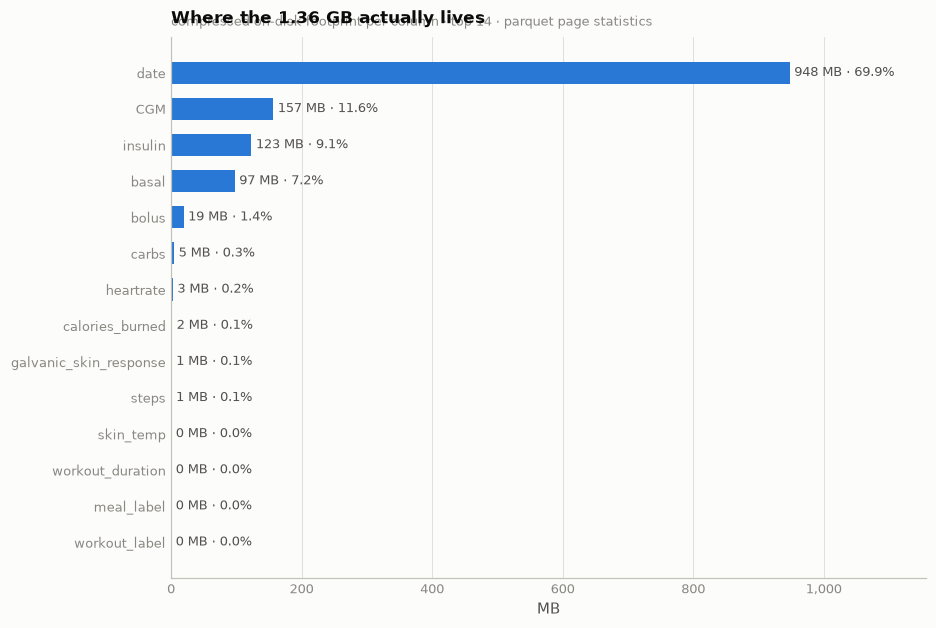

In [9]:
top = phys.head(14).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.4, 5.6))
bars = ax.barh(top.column, top.compressed_MB, height=0.62, color=SERIES[0], linewidth=0)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:,.0f}"))
ax.set_xlim(0, top.compressed_MB.max() * 1.22)
barh_labels(ax, bars, [f"{v:,.0f} MB · {s:.1f}%" for v, s in zip(top.compressed_MB, top["share_%"])])
finish(ax, "Where the 1.36 GB actually lives",
       "compressed on-disk footprint per column · top 14 · parquet page statistics",
       xlab="MB", xgrid=True, ygrid=False)
show()

---
## 2 · Schema & data types

A dtype alone is not a description. The table below pairs each column's *physical*
dtype with its *semantic* type, inferred from cardinality and value shape:

- **constant** — one distinct value (carries no information)
- **binary / flag** — two distinct values
- **low-cardinality categorical** — ≤ 50 distinct
- **high-cardinality categorical / free text** — > 50 distinct strings
- **discrete numeric** — few distinct numbers relative to row count (counts, codes)
- **continuous numeric**
- **identifier**, **timestamp**

Getting this wrong is expensive: `age_of_diagnosis` is numeric but subject-constant,
`workout_intensity` is numeric but has 219 non-null values in 154 million rows, and
`id` is a string that *looks* like a key but isn't unique on its own.

In [10]:
# nunique per column, computed one column at a time to avoid a 37-wide temporary.
t0 = time.time()
prof = []
for c in df.columns:
    s = df[c]
    nn = int(s.notna().sum())
    nu = int(s.nunique(dropna=True))
    prof.append(dict(column=c, dtype=str(s.dtype), kind=KIND[c],
                     non_null=nn, nulls=N_ROWS - nn,
                     null_pct=round((N_ROWS - nn) / N_ROWS * 100, 3),
                     nunique=nu,
                     unique_pct=round(nu / max(nn, 1) * 100, 4),
                     mem_MB=round(s.memory_usage(deep=True) / 1e6, 1)))
prof = pd.DataFrame(prof)
print(f"profiled in {time.time()-t0:.1f}s")

# NOTE: always index a row Series with r["col"], never r.col, for names like
# `nunique` / `count` / `shape` that collide with pandas' own methods -- attribute
# access silently returns the METHOD and comparisons then raise TypeError.
def semantic(r):
    n_uniq, n_nn = r["nunique"], r["non_null"]
    if n_nn == 0:                                        return "empty"
    if r["kind"] == "datetime":                          return "timestamp"
    if n_uniq == 1:                                      return "constant"
    if n_uniq == 2:                                      return "binary"
    if r["kind"] == "flag":                              return "flag"
    if r["kind"] == "categorical":
        if r["unique_pct"] > 40:                         return "identifier / free text"
        if n_uniq <= 50:                                 return "categorical (low card.)"
        return "categorical (high card.)"
    if n_uniq <= 25:                                     return "discrete numeric"
    if n_uniq / max(n_nn, 1) < 1e-4:                     return "quantised numeric"
    return "continuous numeric"

prof["semantic"] = prof.apply(semantic, axis=1)
prof = prof.sort_values(["kind", "null_pct"]).reset_index(drop=True)
prof

profiled in 162.2s


,column,dtype,kind,non_null,nulls,null_pct,nunique,unique_pct,mem_MB,semantic
0,id,str,categorical,154842077,0,0,1291,0.0008,"1,737",categorical (high card.)
1,source_file,str,categorical,154842077,0,0,14,0,"2,005",categorical (low card.)
2,insulin_delivery_modality,str,categorical,153496840,1345237,0.869,3,0,"1,700",categorical (low card.)
3,insulin_delivery_algorithm,str,categorical,151192712,3649365,2.357,10,0,"3,173",categorical (low card.)
4,insulin_delivery_device,str,categorical,146954385,7887692,5.094,26,0,"2,956",categorical (low card.)
5,cgm_device,str,categorical,146438567,8403510,5.427,9,0,"2,579",categorical (low card.)
6,ethnicity,str,categorical,144725281,10116796,6.534,30,0,"2,199",categorical (low card.)
7,insulin_type_basal,str,categorical,142723508,12118569,7.826,20,0,"3,519",categorical (low card.)
8,insulin_type_bolus,str,categorical,141896128,12945949,8.361,17,0,"3,510",categorical (low card.)
9,gender,str,categorical,131171081,23670996,15.29,4,0,"1,914",categorical (low card.)


In [11]:
print(prof.semantic.value_counts().to_string())
print()
print("columns that are >99% null (effectively unusable at corpus level):")
print("  " + ", ".join(prof.loc[prof.null_pct > 99, "column"]))
print()
print("columns with zero nulls (guaranteed present on every row):")
print("  " + ", ".join(prof.loc[prof.null_pct == 0, "column"]))

semantic
continuous numeric          11
categorical (low card.)     10
quantised numeric            5
binary                       4
categorical (high card.)     3
timestamp                    3
discrete numeric             1

columns that are >99% null (effectively unusable at corpus level):
  workout_label, meal_label, misc_notes, heartrate, steps, galvanic_skin_response, skin_temp, workout_duration, air_temp, workout_intensity

columns with zero nulls (guaranteed present on every row):
  id, source_file, date, is_test, subject_split_across_traintest


### 2.1 · Memory attribution

Which columns are worth keeping in a working frame. Note that a 99.9 %-null
`float64` column still costs 1.24 GB resident — the NaNs are stored, not skipped.
This is the single easiest 20 GB to reclaim before any modelling.

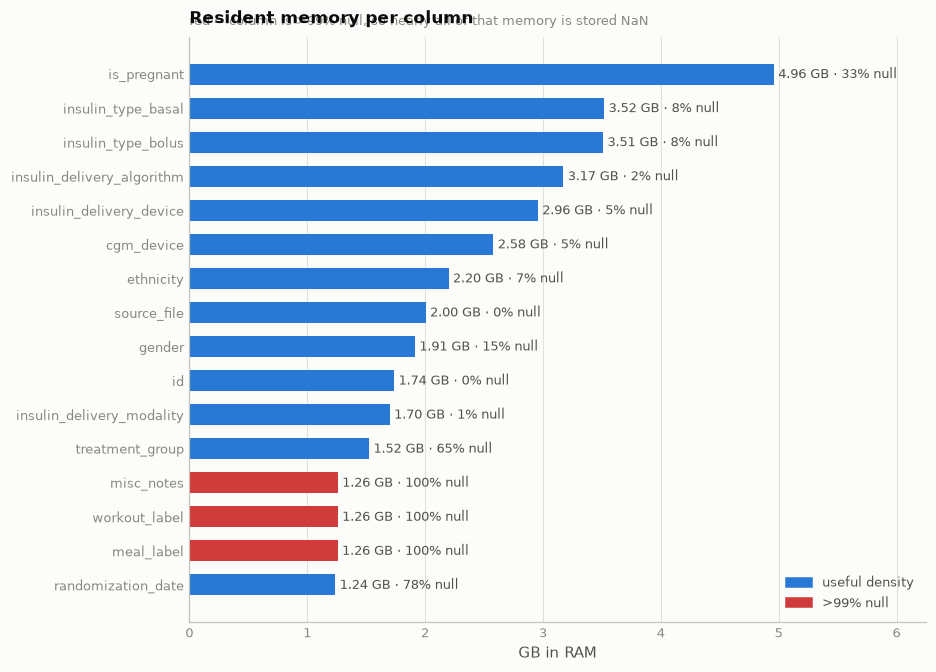


memory held by >99%-null columns: 12.4 GB of 60.6 GB (21% of the frame)


In [12]:
m = prof.sort_values("mem_MB", ascending=False).head(16).iloc[::-1]
colors = [STATUS["critical"] if p > 99 else SERIES[0] for p in m.null_pct]

fig, ax = plt.subplots(figsize=(8.4, 6.0))
bars = ax.barh(m.column, m.mem_MB / 1000, height=0.62, color=colors, linewidth=0)
ax.set_xlim(0, m.mem_MB.max()/1000 * 1.26)
barh_labels(ax, bars, [f"{v/1000:,.2f} GB · {p:.0f}% null" for v, p in zip(m.mem_MB, m.null_pct)])
finish(ax, "Resident memory per column",
       "red = column is >99% null, so nearly all of that memory is stored NaN",
       xlab="GB in RAM", xgrid=True, ygrid=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=SERIES[0], label="useful density"),
                   Patch(color=STATUS["critical"], label=">99% null")],
          loc="lower right", ncols=1)
show()

waste = prof.loc[prof.null_pct > 99, "mem_MB"].sum() / 1000
print(f"\nmemory held by >99%-null columns: {waste:,.1f} GB of {MEM_GB:,.1f} GB "
      f"({waste/MEM_GB*100:.0f}% of the frame)")

---
## 3 · Missingness

The single most important structural fact about this corpus. Roughly a third of the
columns are >99 % null, and the naive reading — "those columns are broken" — is
wrong. They are **cohort-scoped**: heart rate exists only in the wearable studies,
`air_temp` only in one, `treatment_group` only in the randomised trials. Null rate is
therefore not noise to be imputed away; it is a near-perfect encoding of *which study
a row came from*, which makes it both a leakage risk and a usable feature.

This section establishes: (3.1) how much is missing, (3.2) the three missingness
regimes, (3.3) that missingness is a function of cohort, (3.4) which columns go
missing *together*, (3.5) how missingness moves through time, and (3.6) whether the
target itself is missing at random.

### 3.1 · How many NAs, per column

In [13]:
nas = (prof[["column", "kind", "dtype", "non_null", "nulls", "null_pct", "nunique"]]
       .sort_values("null_pct", ascending=False)
       .reset_index(drop=True))
nas["complete_rows"] = nas.non_null.map(lambda v: f"{v:,}")
nas

,column,kind,dtype,non_null,nulls,null_pct,nunique,complete_rows
0,workout_intensity,numeric,float64,219,154841858,100,9,219
1,misc_notes,categorical,str,51393,154790684,99.97,2,"51,393"
2,air_temp,numeric,float64,86626,154755451,99.94,617,"86,626"
3,meal_label,categorical,str,91137,154750940,99.94,2385,"91,137"
4,workout_duration,numeric,float64,97333,154744744,99.94,437,"97,333"
5,workout_label,categorical,str,114010,154728067,99.93,80,"114,010"
6,galvanic_skin_response,numeric,float64,147444,154694633,99.91,75617,"147,444"
7,skin_temp,numeric,float64,147590,154694487,99.91,13526,"147,590"
8,steps,numeric,float64,963227,153878850,99.38,2048,"963,227"
9,heartrate,numeric,float64,1038623,153803454,99.33,152528,"1,038,623"


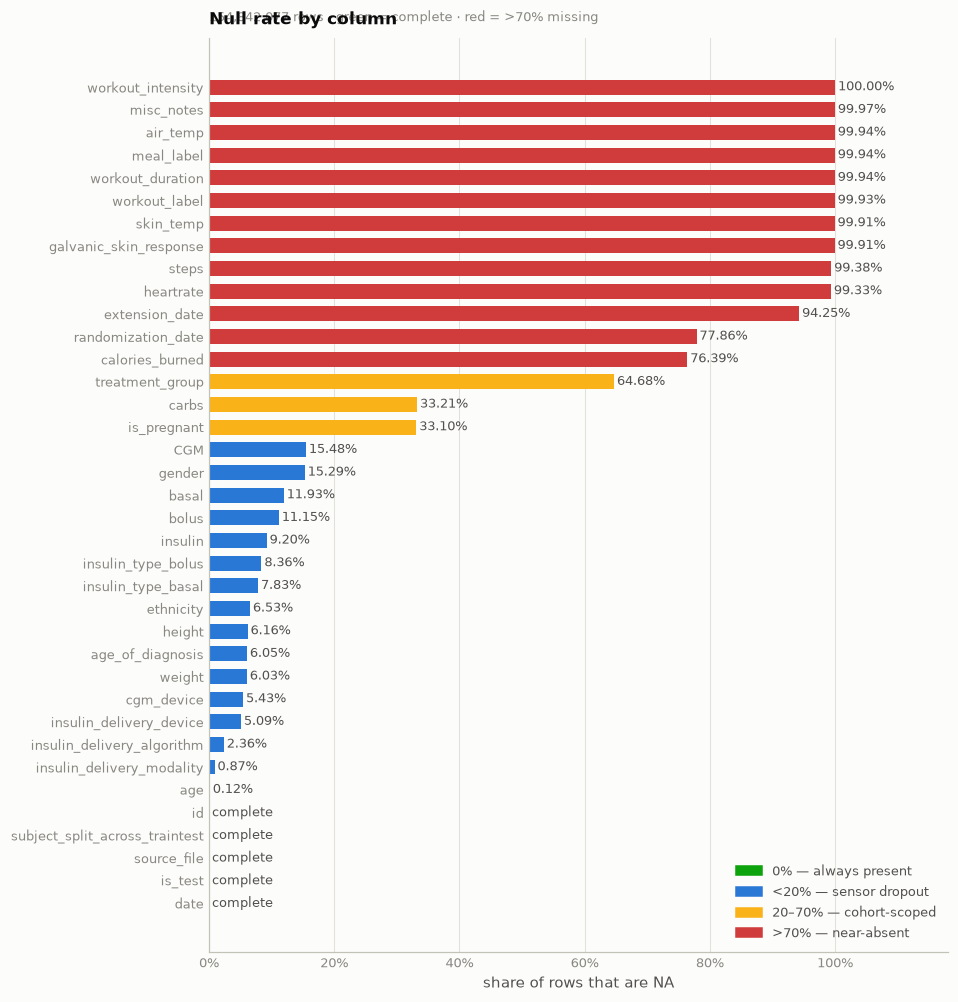

In [14]:
p = nas.sort_values("null_pct")
def band_color(v):
    if v == 0:    return STATUS["good"]
    if v < 20:    return SERIES[0]
    if v < 70:    return STATUS["warning"]
    return STATUS["critical"]

fig, ax = plt.subplots(figsize=(8.6, 9.0))
bars = ax.barh(p.column, p.null_pct, height=0.66,
               color=[band_color(v) for v in p.null_pct], linewidth=0)
ax.set_xlim(0, 118)
ax.xaxis.set_major_locator(MultipleLocator(20))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
barh_labels(ax, bars, [f"{v:.2f}%" if v else "complete" for v in p.null_pct], pad=0.004)
finish(ax, "Null rate by column",
       "154,842,077 rows · green = complete · red = >70% missing",
       xlab="share of rows that are NA", xgrid=True, ygrid=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=STATUS["good"],     label="0% — always present"),
                   Patch(color=SERIES[0],          label="<20% — sensor dropout"),
                   Patch(color=STATUS["warning"],  label="20–70% — cohort-scoped"),
                   Patch(color=STATUS["critical"], label=">70% — near-absent")],
          loc="lower right")
show()

### 3.2 · The three missingness regimes

The bar chart splits cleanly into three populations, and they call for three
different responses.

In [15]:
def regime(p):
    if p == 0:      return "A · complete"
    if p < 20:      return "B · dropout (<20%)"
    if p < 99:      return "C · cohort-scoped (20–99%)"
    return "D · near-absent (>99%)"

nas["regime"] = nas.null_pct.map(regime)
summary = (nas.groupby("regime")
             .agg(n_columns=("column", "size"),
                  member_cols=("column", lambda s: ", ".join(sorted(s))),
                  mean_null_pct=("null_pct", "mean"))
             .sort_index())
for r, row in summary.iterrows():
    print(f"\n{r}   ({row['n_columns']} columns, mean null {row['mean_null_pct']:.1f}%)")
    print("   " + row["member_cols"].replace(", ", "\n   "))


A · complete   (5 columns, mean null 0.0%)
   date
   id
   is_test
   source_file
   subject_split_across_traintest

B · dropout (<20%)   (16 columns, mean null 7.4%)
   CGM
   age
   age_of_diagnosis
   basal
   bolus
   cgm_device
   ethnicity
   gender
   height
   insulin
   insulin_delivery_algorithm
   insulin_delivery_device
   insulin_delivery_modality
   insulin_type_basal
   insulin_type_bolus
   weight

C · cohort-scoped (20–99%)   (6 columns, mean null 63.2%)
   calories_burned
   carbs
   extension_date
   is_pregnant
   randomization_date
   treatment_group

D · near-absent (>99%)   (10 columns, mean null 99.8%)
   air_temp
   galvanic_skin_response
   heartrate
   meal_label
   misc_notes
   skin_temp
   steps
   workout_duration
   workout_intensity
   workout_label


| Regime | Interpretation | What to do |
|---|---|---|
| **A · complete** | Row-level bookkeeping: `date`, `id`, `source_file`, `is_test`, `subject_split_across_traintest`. | Safe to key and join on. |
| **B · dropout** | Real device/sensor dropout on columns that *should* be there — `CGM` 15.5 %, `insulin` 9.2 %, `basal` 11.9 %, `bolus` 11.1 %, plus subject-constant demographics missing for whole cohorts. | Model the gap. Do **not** mean-impute; for tree models leave NaN and let the learner pick a default direction. |
| **C · cohort-scoped** | `carbs` 33 %, `is_pregnant` 33 %, `treatment_group` 65 %, `randomization_date` 78 %, `extension_date` 94 %. Present iff the source study collected it. | Add an explicit `was_missing` indicator. Never impute across cohorts. |
| **D · near-absent** | Wearable and free-text channels: `heartrate`, `steps`, `calories_burned`, `skin_temp`, `galvanic_skin_response`, `air_temp`, `workout_*`, `meal_label`, `misc_notes`. | Unusable as global features. Usable *within* the cohorts that have them — see 3.3. |

The next cell proves the claim that regime C and D are about **cohort**, not chance.

### 3.3 · Missingness is a function of source cohort

In [16]:
t0 = time.time()
sz  = df.groupby("source_file", observed=True).size()
nnc = df.groupby("source_file", observed=True)[list(df.columns)].count()
null_by_src = (1 - nnc.div(sz, axis=0)) * 100          # % null, cohort x column
null_by_src = null_by_src.loc[sz.sort_values(ascending=False).index]
print(f"computed in {time.time()-t0:.1f}s")

# order columns by overall null rate so the block structure is visible
order = nas.sort_values("null_pct").column.tolist()
M = null_by_src[order]
M.round(1)

computed in 145.7s


,date,is_test,source_file,subject_split_across_traintest,id,age,insulin_delivery_modality,insulin_delivery_algorithm,insulin_delivery_device,cgm_device,weight,age_of_diagnosis,height,ethnicity,insulin_type_basal,insulin_type_bolus,insulin,bolus,basal,gender,CGM,is_pregnant,carbs,treatment_group,calories_burned,randomization_date,extension_date,heartrate,steps,galvanic_skin_response,skin_temp,workout_label,workout_duration,meal_label,air_temp,misc_notes,workout_intensity
source_file,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Loop,0,0,0,0,0,0,0,0,7.8,7.4,8.2,8,7.9,8.3,9.7,9.7,9.4,10.5,9.5,7.4,10.7,48.4,16.2,100,62.8,100,100,100,100,100,100,100,100,100,100,100,100
ReplaceBG,0,0,0,0,0,0,2.3,2.3,2.3,2.3,0,2.3,0,2.7,6.1,6.1,7,6.4,7,0,34.3,2.3,12.7,2.3,100,100,100,100,100,100,100,100,100,100,100,100,100
IOBP2,0,0,0,0,0,0,0,0,0,0,0.8,0,3.2,0.6,0,0,12,12,12,100,19.4,0,100,0,100,0.2,8,100,100,100,100,100,100,99.1,100,100,100
Flair,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.1,1,100,21.3,0,100,0,100,0,100,100,100,100,100,100,100,100,100,100,100
DCLP5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.7,3,0.7,0,9.7,0,100,0,100,0,100,100,100,100,100,100,100,100,100,100,100
DCLP3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.1,0,0,6.7,0,100,0,100,0,100,100,100,100,100,100,100,100,100,100,100
PEDAP,0,0,0,0,0,0,0,0,0,0,0,0,3.7,0,0,0,0.1,0.1,46.5,0,9.4,0,0.2,0,100,0,100,100,100,100,100,100,100,100,100,100,100
CTR3,0,0,0,0,0,0,0,100,0,0,0,0,0,0,0,0,73.2,100,100,0,40.7,100,99.4,100,100,100,100,100,100,100,100,100,100,100,100,100,100
BrisT1D,0,0,0,0,0,0,80.6,42.8,0,0,100,0,100,0,100,100,12.4,100,100,0,25.2,100,98.5,100,18.3,100,100,38.5,57.1,100,100,98.3,100,100,100,100,100


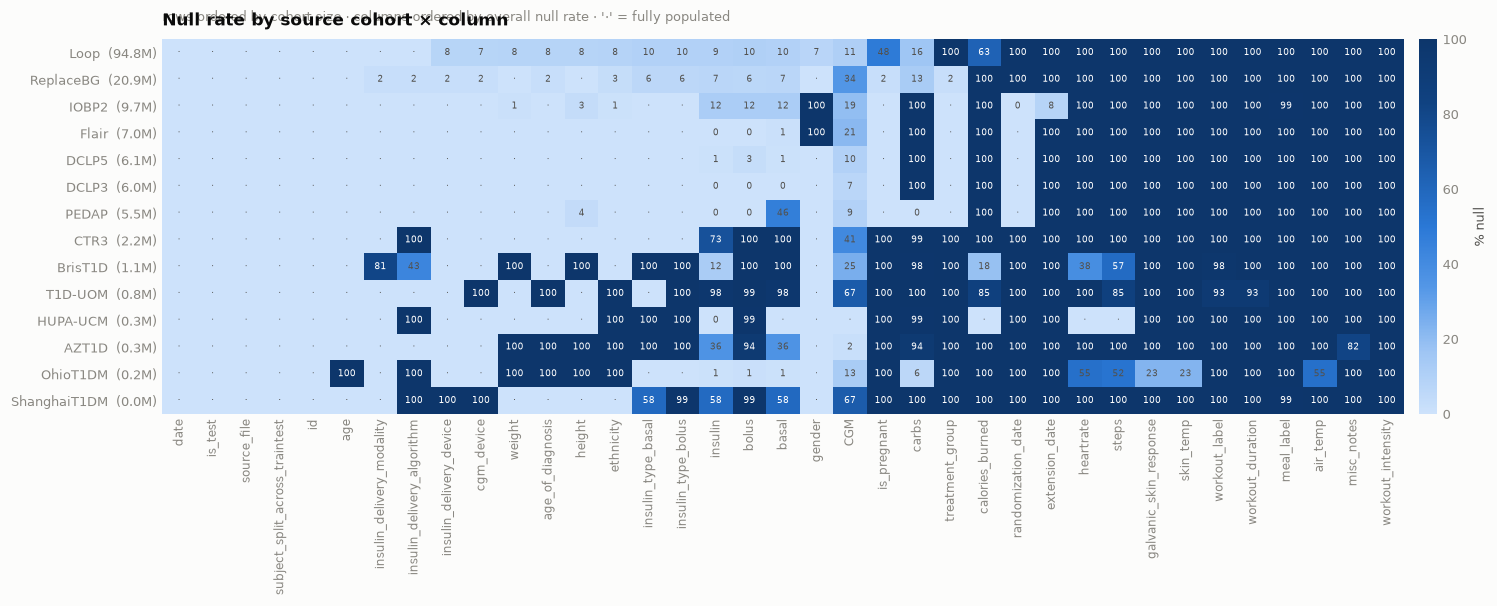

In [17]:
fig, ax = plt.subplots(figsize=(13.5, 5.4))
im = ax.imshow(M.values, aspect="auto", cmap=SEQ_BLUE, vmin=0, vmax=100)

ax.set_xticks(range(len(M.columns)), M.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(M.index)),
              [f"{s}  ({sz[s]/1e6:,.1f}M)" for s in M.index], fontsize=8.5)
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)

# value labels -- the chart is never color-alone
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M.values[i, j]
        if np.isnan(v):
            continue
        txt = "·" if v == 0 else ("100" if v >= 99.5 else f"{v:.0f}")
        ax.text(j, i, txt, ha="center", va="center", fontsize=6.2,
                color="#ffffff" if v > 55 else INK2)

cb = fig.colorbar(im, ax=ax, pad=0.012, fraction=0.018)
cb.set_label("% null", color=INK2, fontsize=8.5)
cb.outline.set_visible(False)
ax.set_title("Null rate by source cohort × column", loc="left")
ax.text(0, 1.04, "rows ordered by cohort size · columns ordered by overall null rate · "
                 "'·' = fully populated", transform=ax.transAxes,
        fontsize=8.5, color=MUTED, va="bottom")
show()

Read the block structure, not the individual cells. The right-hand columns are not
"90 % broken" — they are **100 % present in one or two cohorts and 100 % absent
everywhere else**. Concretely:

- `heartrate`, `steps`, `calories_burned` live almost entirely in the small wearable
  studies. Corpus-wide they look like noise; inside their own cohort they are dense.
- `treatment_group`, `randomization_date`, `extension_date` exist only for the
  randomised trials (`DCLP3`, `DCLP5`, `Flair`, `IOBP2`, `PEDAP`, `CTR3`) — they are
  trial bookkeeping, and a model that learns from them is learning *study identity*.
- `carbs`' 33 % null is almost entirely `Flair` + a slice of `Loop`; the README notes
  `Flair` has no carb data at all and is dropped from the scored subset for exactly
  that reason.

**Consequence for modelling.** The null pattern of a single row is close to a unique
fingerprint of its source study. If cohort correlates with outcome — and with 14
studies spanning paediatric, pregnancy, MDI and closed-loop populations it certainly
does — then any feature derived from missingness is a shortcut that will not
generalise to the held-out set. Validate by cohort, not just by subject.

In [18]:
# How separable is cohort from its null pattern alone? Exact-match test.
sig_cols = [c for c in df.columns if 0 < nas.set_index("column").null_pct[c] < 100]
pat = (null_by_src[sig_cols] > 50).astype(int)
sig = pat.apply(lambda r: "".join(map(str, r)), axis=1)
dup = sig.duplicated(keep=False)
print(f"cohorts with a UNIQUE >50%-null signature : {(~dup).sum()} of {len(sig)}")
if dup.any():
    print("\ncollisions:")
    for s, grp in sig[dup].groupby(sig[dup]):
        print("   ", " ≡ ".join(grp.index))

cohorts with a UNIQUE >50%-null signature : 12 of 14

collisions:
    DCLP5 ≡ DCLP3


### 3.4 · Which columns go missing together

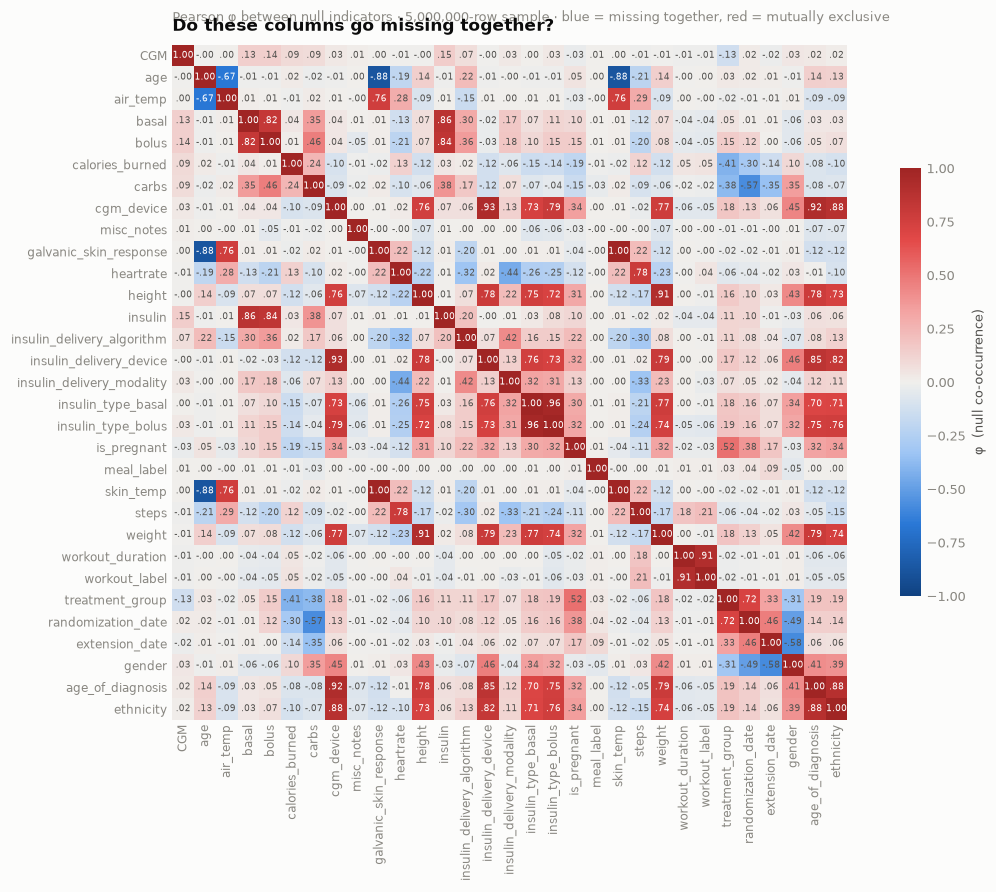

In [19]:
# Correlation of null INDICATORS. Sampled -- a 154M x 20 boolean corr is not worth
# the wall clock, and 5M rows pins these correlations to ~4 decimal places.
samp_idx = RNG.choice(N_ROWS, size=min(CFG["n_rows_sample"], N_ROWS), replace=False)
samp_idx.sort()
miss = df.iloc[samp_idx][sig_cols].isna()
miss = miss.loc[:, miss.std() > 0]                    # drop degenerate-in-sample
mc = miss.astype("float32").corr()

fig, ax = plt.subplots(figsize=(9.2, 8.0))
im = ax.imshow(mc.values, cmap=DIV_BR, vmin=-1, vmax=1)
ax.set_xticks(range(len(mc)), mc.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(mc)), mc.index, fontsize=8)
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
for i in range(len(mc)):
    for j in range(len(mc)):
        v = mc.values[i, j]
        ax.text(j, i, f"{v:.2f}".replace("0.", "."), ha="center", va="center",
                fontsize=6.0, color="#ffffff" if abs(v) > 0.62 else INK2)
cb = fig.colorbar(im, ax=ax, pad=0.012, fraction=0.026)
cb.set_label("φ  (null co-occurrence)", color=INK2, fontsize=8.5)
cb.outline.set_visible(False)
ax.set_title("Do these columns go missing together?", loc="left")
ax.text(0, 1.03, f"Pearson φ between null indicators · {len(miss):,}-row sample · "
                 "blue = missing together, red = mutually exclusive",
        transform=ax.transAxes, fontsize=8.5, color=MUTED, va="bottom")
show()

In [20]:
pairs = mc.where(np.triu(np.ones(mc.shape), 1).astype(bool)).stack()
pairs = pairs.reindex(pairs.abs().sort_values(ascending=False).index)
print("strongest null co-occurrence pairs\n" + "-"*58)
for (a, b), v in pairs.head(18).items():
    rel = "always together" if v > .97 else ("together" if v > 0 else "mutually exclusive")
    print(f"  {v:+.3f}  {a:<28s} ~ {b:<28s}  {rel}")

strongest null co-occurrence pairs
----------------------------------------------------------
  +0.999  galvanic_skin_response       ~ skin_temp                     always together
  +0.965  insulin_type_basal           ~ insulin_type_bolus            together
  +0.930  cgm_device                   ~ insulin_delivery_device       together
  +0.920  cgm_device                   ~ age_of_diagnosis              together
  +0.911  workout_duration             ~ workout_label                 together
  +0.908  height                       ~ weight                        together
  +0.883  age_of_diagnosis             ~ ethnicity                     together
  +0.883  cgm_device                   ~ ethnicity                     together
  -0.877  age                          ~ skin_temp                     mutually exclusive
  -0.876  age                          ~ galvanic_skin_response        mutually exclusive
  +0.864  basal                        ~ insulin                       together

In [21]:
# The actual missingness PATTERNS -- how many distinct null fingerprints exist, and
# how concentrated are they.
patt = miss.apply(lambda r: "".join("1" if v else "0" for v in r), axis=1)
vc = patt.value_counts()
print(f"distinct null patterns in the {len(miss):,}-row sample : {len(vc):,}")
print(f"top 10 patterns cover                                : {vc.head(10).sum()/len(miss)*100:.1f}% of rows")
print(f"rows with NO nulls at all in these columns            : "
      f"{vc.get('0'*miss.shape[1], 0)/len(miss)*100:.2f}%\n")

legend = pd.DataFrame({"pos": range(miss.shape[1]), "column": miss.columns})
top = vc.head(12).rename("rows").to_frame()
top["share_%"] = (top.rows / len(miss) * 100).round(2)
top["missing"] = [", ".join(miss.columns[[i for i, ch in enumerate(p) if ch == "1"]]) or "— none —"
                  for p in top.index]
top.reset_index(drop=True)[["rows", "share_%", "missing"]]

distinct null patterns in the 5,000,000-row sample : 711
top 10 patterns cover                                : 68.0% of rows
rows with NO nulls at all in these columns            : 0.00%



,rows,share_%,missing
0,654533,13.09,"air_temp, calories_burned, misc_notes, galvanic_skin_res..."
1,547526,10.95,"air_temp, calories_burned, misc_notes, galvanic_skin_res..."
2,463849,9.28,"air_temp, misc_notes, galvanic_skin_response, heartrate,..."
3,372620,7.45,"air_temp, calories_burned, misc_notes, galvanic_skin_res..."
4,359065,7.18,"air_temp, calories_burned, carbs, misc_notes, galvanic_s..."
5,326339,6.53,"air_temp, misc_notes, galvanic_skin_response, heartrate,..."
6,225449,4.51,"air_temp, calories_burned, carbs, misc_notes, galvanic_s..."
7,191198,3.82,"air_temp, calories_burned, carbs, misc_notes, galvanic_s..."
8,168857,3.38,"CGM, air_temp, calories_burned, misc_notes, galvanic_ski..."
9,89548,1.79,"air_temp, calories_burned, cgm_device, misc_notes, galva..."


### 3.5 · Missingness through time

findfont: Failed to find font weight 600, now using 700.


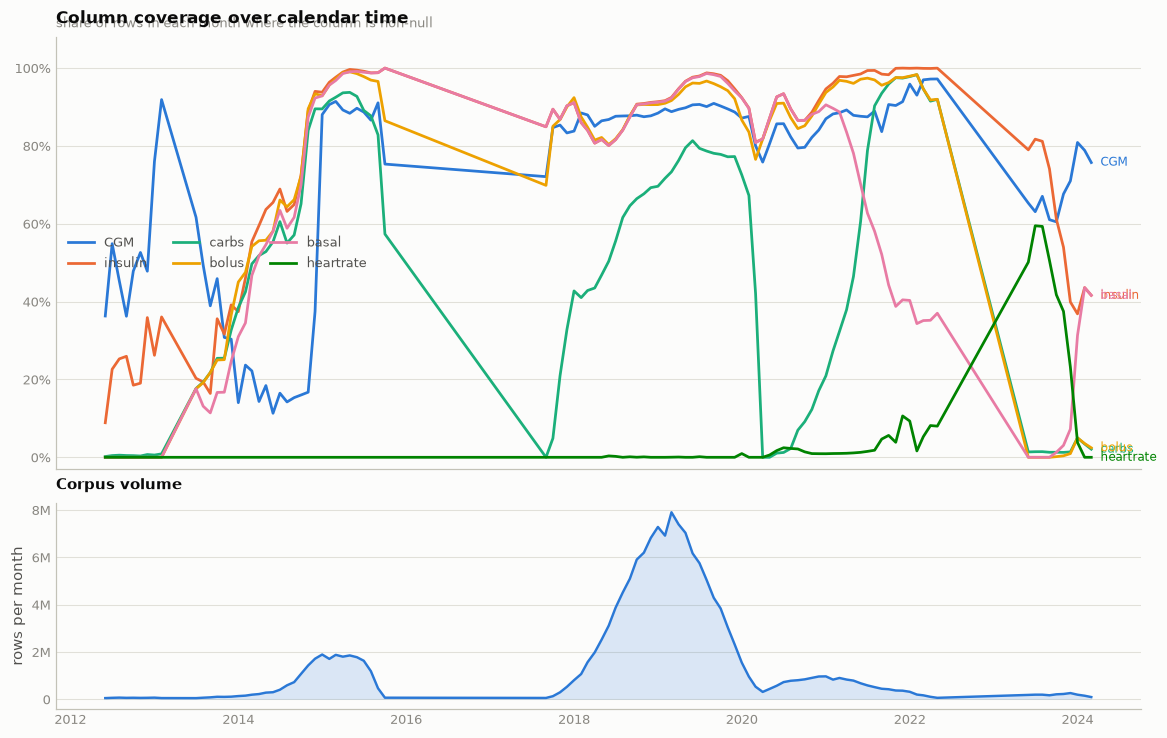

date range: 2011-11-17 21:00:00  →  2027-07-14 15:30:00


In [22]:
month = df["date"].values.astype("datetime64[M]")          # fast, no .dt overhead
watch = ["CGM", "insulin", "carbs", "bolus", "basal", "heartrate"]
cov = pd.DataFrame({"month": month})
for c in watch:
    cov[c] = df[c].notna().to_numpy()
cov["_n"] = 1
gm = cov.groupby("month").agg({**{c: "mean" for c in watch}, "_n": "size"})
gm = gm[gm["_n"] >= 50_000]                                # drop ragged edges
gm.index = pd.to_datetime(gm.index)

fig, axes = plt.subplots(2, 1, figsize=(10.5, 6.6), sharex=True,
                         height_ratios=[2.1, 1])
ax = axes[0]
for i, c in enumerate(watch):
    ax.plot(gm.index, gm[c]*100, color=SERIES[i], lw=1.8, label=c)
    ax.annotate(c, (gm.index[-1], gm[c].iloc[-1]*100), xytext=(6, 0),
                textcoords="offset points", fontsize=8, color=SERIES[i], va="center")
ax.set_ylim(-3, 108)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.legend(loc="center left", ncols=3)
finish(ax, "Column coverage over calendar time",
       "share of rows in each month where the column is non-null")

ax = axes[1]
ax.fill_between(gm.index, gm["_n"], color=SERIES[0], alpha=0.16, linewidth=0)
ax.plot(gm.index, gm["_n"], color=SERIES[0], lw=1.6)
ax.yaxis.set_major_formatter(KFMT)
finish(ax, None, None, ylab="rows per month")
ax.set_title("Corpus volume", loc="left", fontsize=9.5)
show()

print(f"date range: {df['date'].min()}  →  {df['date'].max()}")

Coverage is **not** stationary. The corpus is a union of studies that ran in different
years, so a column's availability steps up and down as cohorts enter and leave. Two
practical readings:

- A time-based split would train on a different *feature availability regime* than it
  tests on. This is a second, independent argument for splitting by subject.
- The final months have thin volume; anything computed on the tail is high-variance.

### 3.6 · Is the target missing at random?

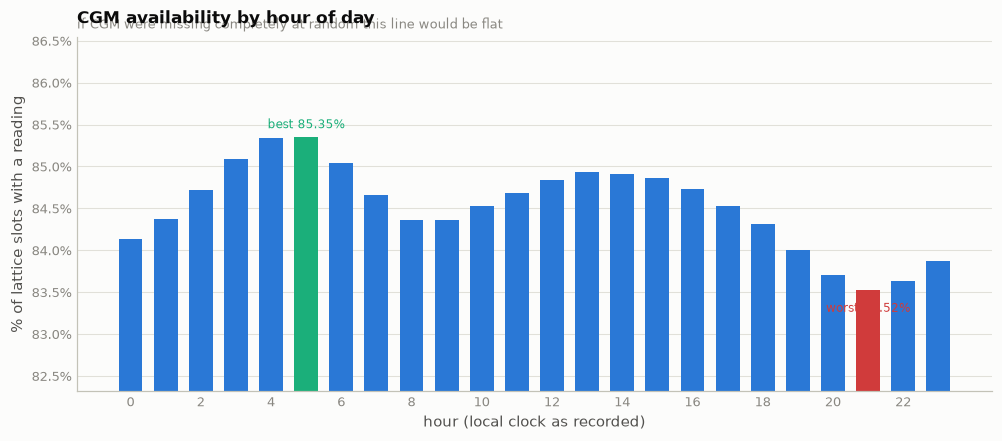

spread across the day: 1.83 percentage points
overall CGM null rate: 15.48%


In [23]:
hour = df["date"].dt.hour.to_numpy()
cgm_present = df["CGM"].notna().to_numpy()

by_hour = pd.Series(cgm_present).groupby(hour).mean() * 100
worst, best = by_hour.idxmin(), by_hour.idxmax()

fig, ax = plt.subplots(figsize=(9.0, 3.9))
cols = [STATUS["critical"] if h == worst else (SERIES[0] if h != best else SERIES[2])
        for h in by_hour.index]
bars = ax.bar(by_hour.index, by_hour.values, width=0.68, color=cols, linewidth=0)
ax.set_ylim(by_hour.min() - 1.2, by_hour.max() + 1.2)
ax.set_xticks(range(0, 24, 2))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.1f}%"))
ax.annotate(f"worst {by_hour[worst]:.2f}%", (worst, by_hour[worst]), xytext=(0, -14),
            textcoords="offset points", ha="center", fontsize=8, color=STATUS["critical"])
ax.annotate(f"best {by_hour[best]:.2f}%", (best, by_hour[best]), xytext=(0, 6),
            textcoords="offset points", ha="center", fontsize=8, color=SERIES[2])
finish(ax, "CGM availability by hour of day",
       "if CGM were missing completely at random this line would be flat",
       xlab="hour (local clock as recorded)", ylab="% of lattice slots with a reading")
show()

print(f"spread across the day: {by_hour.max() - by_hour.min():.2f} percentage points")
print(f"overall CGM null rate: {(~cgm_present).mean()*100:.2f}%")

gap onsets observed            : 1,146,574
mean CGM just before a gap     :   155.52 mg/dL
mean CGM overall               :   148.18 mg/dL
share of pre-gap readings <70  :   4.77%
share of ALL readings <70      :   2.76%
share of pre-gap readings >250 :   9.14%
share of ALL readings >250     :   5.65%


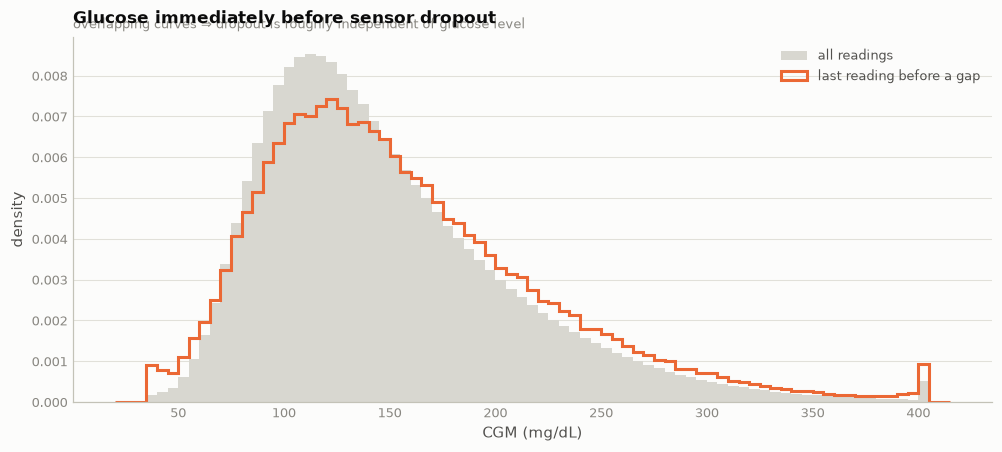

In [24]:
# Does CGM go missing when glucose is extreme? Compare the value immediately BEFORE
# a gap against the marginal distribution. (Rows are a dense 5-min lattice -- proven
# in section 7 -- so "previous row" is "5 minutes earlier" within a subject.)
same_subj = (df["id"].to_numpy()[1:] == df["id"].to_numpy()[:-1]) & \
            (df["source_file"].to_numpy()[1:] == df["source_file"].to_numpy()[:-1])
cgm = df["CGM"].to_numpy()
gap_starts = same_subj & ~cgm_present[1:] & cgm_present[:-1]
before_gap = cgm[:-1][gap_starts]

print(f"gap onsets observed            : {gap_starts.sum():,}")
print(f"mean CGM just before a gap     : {np.nanmean(before_gap):8.2f} mg/dL")
print(f"mean CGM overall               : {np.nanmean(cgm):8.2f} mg/dL")
print(f"share of pre-gap readings <70  : {(before_gap < 70).mean()*100:6.2f}%")
print(f"share of ALL readings <70      : {np.nanmean(cgm < 70)*100:6.2f}%")
print(f"share of pre-gap readings >250 : {(before_gap > 250).mean()*100:6.2f}%")
print(f"share of ALL readings >250     : {np.nanmean(cgm > 250)*100:6.2f}%")

fig, ax = plt.subplots(figsize=(9.0, 4.0))
bins = np.arange(20, 420, 5)
ax.hist(cgm[cgm_present], bins=bins, density=True, color=FADE, linewidth=0,
        label="all readings")
ax.hist(before_gap, bins=bins, density=True, histtype="step", color=SERIES[1],
        lw=2.0, label="last reading before a gap")
ax.legend(loc="upper right")
finish(ax, "Glucose immediately before sensor dropout",
       "overlapping curves ⇒ dropout is roughly independent of glucose level",
       xlab="CGM (mg/dL)", ylab="density")
show()

---
## 4 · Data dictionary

Column meanings, units, and the gotcha attached to each. **Units are the headline
here**: this corpus was assembled from studies on different measurement systems and
the harmonisation is incomplete. `height` is in *feet*, `weight` in *pounds*,
`skin_temp` and `air_temp` in *Fahrenheit*, while `CGM` is in mg/dL and carbs in
grams. Nothing in the schema says so — it has to be inferred from the value ranges,
which is done empirically in section 5.

| Column | Unit / domain | Grain | Notes |
|---|---|---|---|
| `CGM` | mg/dL | 5-min | **The target.** 15.5 % null. Clipped by device firmware at 40 and 400 — see 9.2. |
| `date` | timestamp (ns) | 5-min | Dense lattice, zero nulls, exactly 5 min between consecutive rows within a subject. |
| `id` | string | subject | **Not unique across cohorts.** Real key is `(source_file, id)`. |
| `source_file` | string, 14 values | subject | Origin study. Drives nearly all missingness. |
| `is_test` | bool | row | Official split flag. 22.1 M test rows. |
| `subject_split_across_traintest` | bool | subject | True for 169 subjects split *temporally* — the leakage trap. |
| `basal` | units of insulin delivered in the 5-min slot | 5-min | Not a rate. 25 % exact zeros. |
| `bolus` | units | 5-min | 93 % exact zeros — spiky event channel. 4 negative values (corrections). |
| `insulin` | units, total | 5-min | **Exactly `basal + bolus`** to float precision on all 134 M rows where all three exist — fully redundant. See 12.3. |
| `carbs` | grams | 5-min | 98 % exact zeros. Absent entirely for `Flair`. |
| `age` | years | subject | 1–82. |
| `age_of_diagnosis` | years | subject | T1D onset age. 0 for 401 k rows (congenital / infant onset). |
| `gender` | string | subject | 4 levels, `Non-binary` and `Non Binary` are the same level spelled twice. |
| `ethnicity` | string, 30 values | subject | Free-text multi-select, comma-joined. Not a clean categorical. |
| `height` | **feet** | subject | Median 5.45. |
| `weight` | **pounds** | subject | Median 150. |
| `is_pregnant` | bool / None | subject | 33 % null; True for one pregnancy cohort. |
| `cgm_device` | string | subject-era | Dexcom/Medtronic/Libre families. |
| `insulin_delivery_device` | string | subject-era | Pump model. |
| `insulin_delivery_modality` | AID / SAP / MDI | subject-era | 84.5 % of rows are closed-loop (AID). |
| `insulin_delivery_algorithm` | string | subject-era | Control-IQ, Loop, 670G, … |
| `insulin_type_basal` / `insulin_type_bolus` | string | subject-era | **Unnormalised** — `Humalog`, `humalog`, `Humalog (Lispro)` coexist. |
| `treatment_group` | string, 8 values | subject | Trial arm. 65 % null (only randomised studies). |
| `randomization_date` / `extension_date` | timestamp | subject | Trial bookkeeping. 78 % / 94 % null. |
| `heartrate` | bpm | 5-min | 99.3 % null — wearable cohorts only. |
| `steps` | count per slot | 5-min | 99.4 % null. |
| `calories_burned` | kcal per slot | 5-min | 76 % null; max 21,726 is impossible — see 12. |
| `skin_temp` / `air_temp` | **°F** | 5-min | 99.9 % null; one cohort. |
| `galvanic_skin_response` | µS | 5-min | 99.9 % null. |
| `workout_duration` | minutes | event | 97 k non-null rows; max 8,218 min = 5.7 days. |
| `workout_intensity` | 2–10 ordinal | event | **219 non-null values in the entire corpus.** |
| `workout_label` / `meal_label` | free text | event | 80 / 2,385 distinct strings. |
| `misc_notes` | free text | event | 51 k non-null. |

The cell below regenerates the mechanical half of this table straight from the data,
so it stays honest if the file is ever refreshed.

In [25]:
def column_card(c, n_show=6):
    s = df[c]
    nn = int(s.notna().sum())
    head = f"┌─ {c}  ·  {s.dtype}  ·  {KIND[c]}"
    print(head + " " + "─"*max(0, 96-len(head)))
    print(f"│  non-null {nn:>13,} ({nn/N_ROWS*100:6.2f}%)   "
          f"distinct {s.nunique(dropna=True):>10,}")
    if KIND[c] == "numeric":
        q = s.quantile([0, .01, .25, .5, .75, .99, 1])
        print(f"│  min {q.iloc[0]:>12,.4g}   p01 {q.iloc[1]:>10,.4g}   p25 {q.iloc[2]:>10,.4g}   "
              f"med {q.iloc[3]:>10,.4g}")
        print(f"│  p75 {q.iloc[4]:>12,.4g}   p99 {q.iloc[5]:>10,.4g}   max {q.iloc[6]:>10,.4g}   "
              f"zeros {(s == 0).sum()/max(nn,1)*100:8.2f}%")
    elif KIND[c] == "datetime":
        print(f"│  from {s.min()}   to {s.max()}")
    else:
        vc = s.value_counts(dropna=False).head(n_show)
        for k, v in vc.items():
            k = "‹NA›" if (k is None or (isinstance(k, float) and np.isnan(k))) else str(k)
            print(f"│    {k[:52]:<52s} {v:>13,} ({v/N_ROWS*100:5.2f}%)")
    print("└" + "─"*97)

for c in ["CGM", "insulin", "carbs", "source_file", "insulin_delivery_modality", "gender"]:
    column_card(c); print()

┌─ CGM  ·  float64  ·  numeric ──────────────────────────────────────────────────────────────────
│  non-null   130,872,839 ( 84.52%)   distinct     24,773
│  min        1.802   p01         58   p25        105   med        135
│  p75          179   p99        338   max      500.9   zeros     0.00%
└─────────────────────────────────────────────────────────────────────────────────────────────────

┌─ insulin  ·  float64  ·  numeric ──────────────────────────────────────────────────────────────
│  non-null   140,602,689 ( 90.80%)   distinct    336,627
│  min            0   p01          0   p25    0.01464   med    0.06667
│  p75       0.1219   p99        2.2   max         94   zeros    23.35%
└─────────────────────────────────────────────────────────────────────────────────────────────────

┌─ carbs  ·  float64  ·  numeric ────────────────────────────────────────────────────────────────
│  non-null   103,416,778 ( 66.79%)   distinct      2,846
│  min            0   p01          0   p25    

In [26]:
# Uncomment to print a card for every column.
# for c in df.columns:
#     column_card(c); print()

---
## 5 · Univariate analysis — numeric columns

17 numeric columns, and they are emphatically **not** one population. Three shapes
recur:

1. **Subject-constant demographics** (`age`, `height`, `weight`, `age_of_diagnosis`) —
   repeated identically down every row of a subject. Their row-weighted distribution
   is the *subject* distribution weighted by how long each subject was recorded,
   which is a different thing entirely. Section 8 redoes these properly.
2. **Zero-inflated event channels** (`bolus`, `carbs`, `basal`, `steps`,
   `calories_burned`) — a point mass at zero plus a heavy right tail. Skew in the
   tens or hundreds is a property of the encoding, not an anomaly to fix.
3. **Genuinely continuous physiology** (`CGM`, `heartrate`, `skin_temp`) — roughly
   unimodal, mildly skewed.

Skew and kurtosis mean different things in each case, so the summary table below
labels the shape before quoting the number.

### 5.1 · Extended descriptive statistics

In [27]:
QS = [.001, .01, .05, .25, .5, .75, .95, .99, .999]
desc = df[NUM].describe(percentiles=QS).T
desc = desc.rename(columns={"50%": "median"})
desc["IQR"]   = desc["75%"] - desc["25%"]
desc["range"] = desc["max"] - desc["min"]
desc["CV"]    = desc["std"] / desc["mean"].replace(0, np.nan)
desc[["count", "mean", "std", "CV", "min", "1%", "25%", "median", "75%", "99%", "max", "IQR"]]

,count,mean,std,CV,min,1%,25%,median,75%,99%,max,IQR
CGM,1.309e+08,148.2,59.72,0.403,1.802,58,105,135,179,338,500.9,74
age,1.547e+08,29.23,17.97,0.6149,1,2,13,29,42,71,82,29
air_temp,8.663e+04,84.57,4.516,0.0534,50.23,74.3,81.5,84.2,87.26,95,119.5,5.76
basal,1.364e+08,0.08272,0.1212,1.465,0,0,0.0075,0.06042,0.1083,0.4533,68,0.1008
bolus,1.376e+08,0.07077,0.6024,8.513,-3,0,0,0,0,2.05,50,0
calories_burned,3.656e+07,0.6627,23.84,35.97,0,0,0,0,0,7.55,2.173e+04,0
carbs,1.034e+08,0.4923,4.817,9.784,0,0,0,0,0,20,855,0
galvanic_skin_response,1.474e+05,1.013,3.923,3.872,0,4.3e-05,8.9e-05,0.01178,0.221,19.04,75.07,0.221
heartrate,1.039e+06,78.11,16.56,0.212,32.41,50.1,65.99,76,87.3,124.9,199.3,21.31
height,1.453e+08,5.271,0.7462,0.1416,2.083,2.999,5.083,5.446,5.75,6.332,6.5,0.6667


In [28]:
t0 = time.time()
rows = []
for c in NUM:
    s = df[c]
    v = s.dropna()
    n = len(v)
    if n == 0:
        continue
    q1, med, q3 = v.quantile([.25, .5, .75])
    mad = float(np.nanmedian(np.abs(v.to_numpy() - med)))
    rows.append(dict(
        column=c, n=n,
        skew=float(v.skew()), kurtosis=float(v.kurt()),
        pct_zero=float((v == 0).mean()*100),
        n_negative=int((v < 0).sum()),
        nunique=int(v.nunique()),
        # robust skew: insensitive to the tail, so it separates "spiky tail"
        # from "genuinely asymmetric body"
        bowley=float(((q3 + q1 - 2*med) / (q3 - q1)) if q3 > q1 else np.nan),
        mad=mad,
        pct_outlier_iqr=float((((v < q1 - 1.5*(q3-q1)) | (v > q3 + 1.5*(q3-q1))).mean())*100),
    ))
numstats = pd.DataFrame(rows).set_index("column")
print(f"computed in {time.time()-t0:.1f}s")

# r["skew"] not r.skew -- `skew` is a pandas method name (see the note in section 2).
def shape_label(r):
    if r["pct_zero"] > 60:                  return "zero-inflated"
    if abs(r["skew"]) > 10:                 return "extreme right tail"
    if abs(r["skew"]) > 2:                  return "strongly skewed"
    if abs(r["skew"]) > 0.5:                return "moderately skewed"
    return "near-symmetric"

numstats["dist_shape"] = numstats.apply(shape_label, axis=1)
numstats.sort_values("skew", ascending=False).round(3)

computed in 2760.8s


,n,skew,kurtosis,pct_zero,n_negative,nunique,bowley,mad,pct_outlier_iqr,dist_shape
column,,,,,,,,,,
calories_burned,36560106,222.5,1.044e+05,96.59,0,29527,NaN,0,3.407,zero-inflated
basal,136363434,138.8,6.875e+04,24.86,0,24837,-0.05,0.05,4.378,extreme right tail
workout_duration,97333,67.57,"8,076",0.437,0,437,1,0,12.27,extreme right tail
insulin,140602689,16.16,466.8,23.35,0,336627,0.03,0.054,6.796,extreme right tail
bolus,137579931,15.82,358.8,93.42,4,66876,NaN,0,6.585,zero-inflated
carbs,103416778,14.09,309.9,98.37,0,2846,NaN,0,1.632,zero-inflated
galvanic_skin_response,147444,8.187,96.8,0.726,0,75617,0.894,0.012,17.59,strongly skewed
steps,963227,6.569,72.19,56.54,0,2048,1,0,14.66,strongly skewed
age_of_diagnosis,145471491,1.585,2.686,0.276,0,97,0.333,5,4.956,moderately skewed


`bowley` is Bowley's quartile skewness, `(Q3 + Q1 − 2·median) / (Q3 − Q1)`, bounded in
[−1, 1]. Reading it *beside* moment skew is the whole point: `calories_burned` has
moment skew 222 but Bowley skew is undefined/degenerate because Q1 = median = Q3 = 0.
That combination says "the distribution is a spike at zero with a few enormous
values", which is a completely different problem from `CGM`'s honest, mild
right-skew of 1.14.

### 5.2 · Skew, ranked

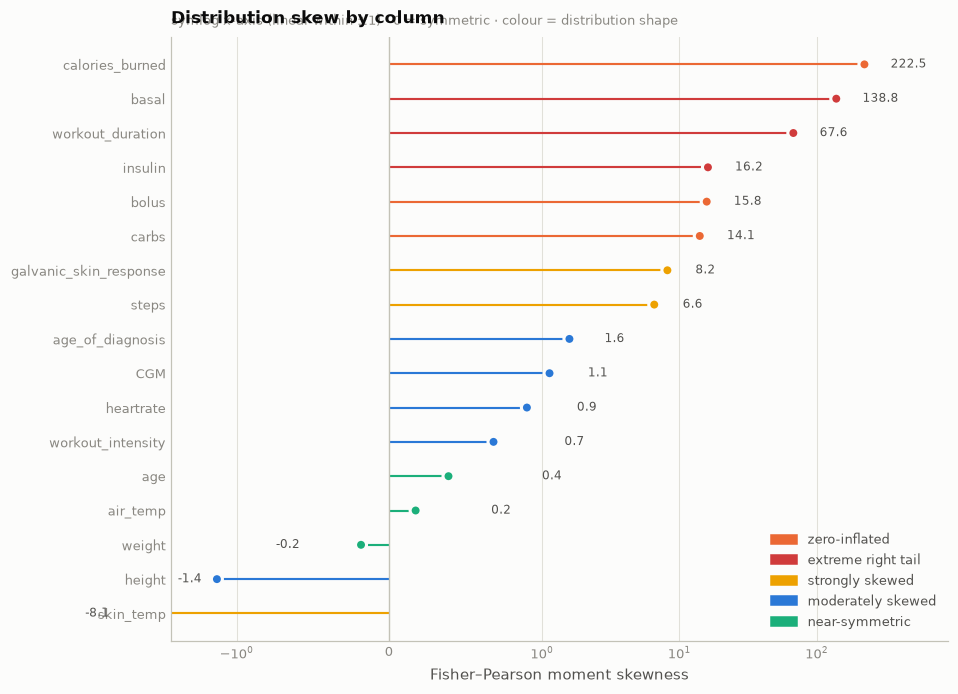

In [29]:
sk = numstats.sort_values("skew")
sk = sk[sk["n"] > 100]
skv = sk["skew"].to_numpy()
fig, ax = plt.subplots(figsize=(8.6, 6.2))

cmap = {"zero-inflated": SERIES[1], "extreme right tail": STATUS["critical"],
        "strongly skewed": SERIES[3], "moderately skewed": SERIES[0],
        "near-symmetric": SERIES[2]}
cols = [cmap[s] for s in sk["dist_shape"]]
y = np.arange(len(sk))
ax.hlines(y, 0, skv, color=cols, lw=1.4)                            # thin stems
ax.scatter(skv, y, s=52, color=cols, zorder=3,
           edgecolor=SURFACE, linewidth=2)                          # 2px surface ring
ax.axvline(0, color=AXIS, lw=0.9)
ax.set_yticks(y, sk.index, fontsize=8.6)
ax.set_xscale("symlog", linthresh=1)
ax.set_xlim(-3, 900)
for yy, v in zip(y, skv):
    ax.text(v * (1.55 if v > 0 else 1.0) + (0.4 if v >= 0 else -0.4), yy,
            f"{v:,.1f}", va="center", ha="left" if v >= 0 else "right",
            fontsize=8, color=INK2)
finish(ax, "Distribution skew by column",
       "symlog x-axis (linear within ±1) · 0 = symmetric · colour = distribution shape",
       xlab="Fisher–Pearson moment skewness", xgrid=True, ygrid=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=v, label=k) for k, v in cmap.items()],
          loc="lower right")
show()

### 5.3 · The shape of every numeric column

findfont: Failed to find font weight 600, now using 700.


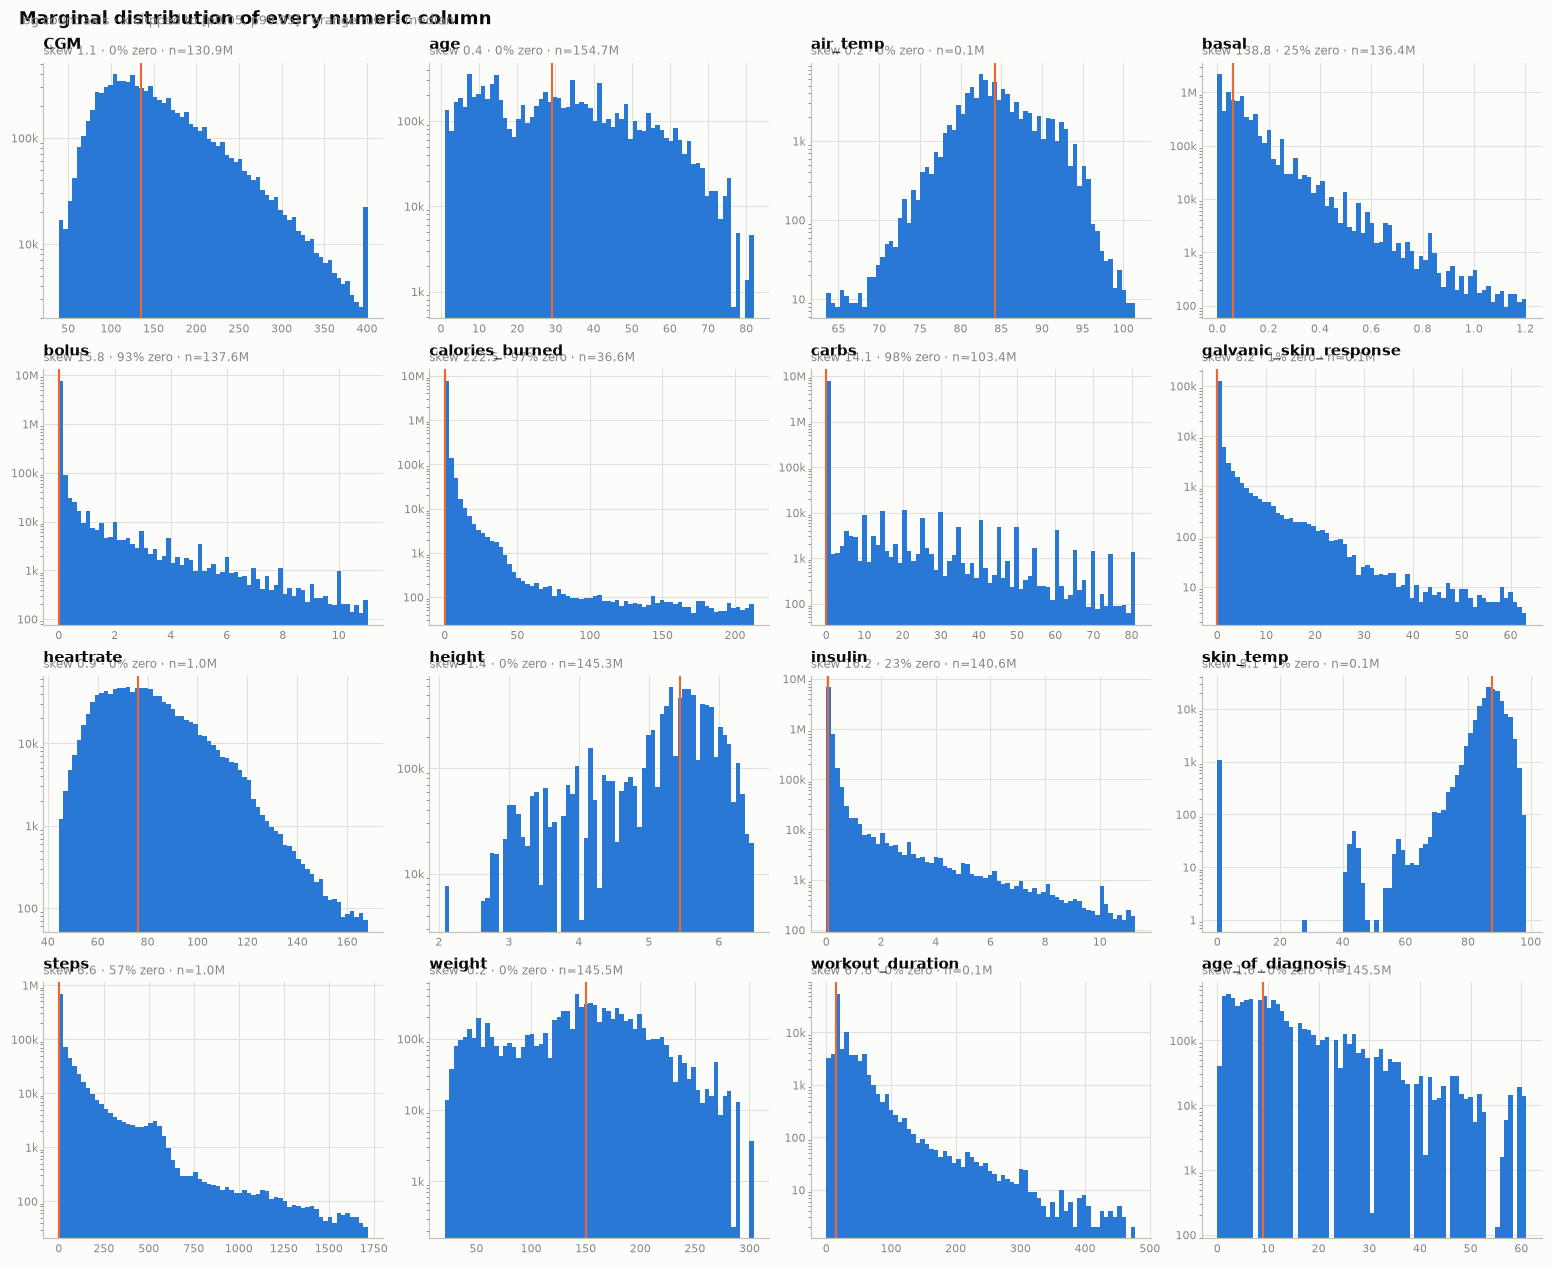

In [30]:
plot_cols = [c for c in NUM if numstats.loc[c, "n"] > 1000]
_ns = numstats  # row access below uses _ns.loc[c, "col"], never attribute access
ncol, nrow = 4, math.ceil(len(plot_cols)/4)
fig, axes = plt.subplots(nrow, ncol, figsize=(14, 2.85*nrow))
axes = np.atleast_1d(axes).ravel()

for ax, c in zip(axes, plot_cols):
    v = df[c].dropna()
    if len(v) > 8_000_000:
        v = v.sample(8_000_000, random_state=CFG["seed"])
    v = v.to_numpy()
    lo, hi = np.quantile(v, [0.0005, 0.9995])
    if hi <= lo:
        lo, hi = v.min(), max(v.max(), v.min() + 1)
    ax.hist(v, bins=np.linspace(lo, hi, 70), color=SERIES[0], linewidth=0)
    ax.set_yscale("log")                      # heavy tails are invisible on a linear count axis
    ax.yaxis.set_major_formatter(KFMT)
    ax.set_title(c, loc="left", fontsize=9.5)
    ax.text(0, 1.02, f"skew {_ns.loc[c,'skew']:,.1f} · {_ns.loc[c,'pct_zero']:.0f}% zero"
                     f" · n={_ns.loc[c,'n']/1e6:,.1f}M",
            transform=ax.transAxes, fontsize=7.6, color=MUTED, va="bottom")
    ax.tick_params(labelsize=7.5)
    ax.axvline(np.median(v), color=SERIES[1], lw=1.4)

for ax in axes[len(plot_cols):]:
    ax.set_visible(False)
fig.suptitle("Marginal distribution of every numeric column",
             x=0.008, ha="left", fontsize=12, color=INK, weight="600")
fig.text(0.008, 0.985, "log count axis · x clipped to [p0.05, p99.95] · "
                       "orange rule = median", fontsize=8.6, color=MUTED, ha="left")
show()

### 5.4 · Zero inflation: the event channels

In [31]:
event_cols = ["bolus", "carbs", "basal", "insulin", "steps", "calories_burned"]
zi = pd.DataFrame({
    "non_null":   [int(numstats.loc[c, "n"]) for c in event_cols],
    "pct_zero":   [numstats.loc[c, "pct_zero"] for c in event_cols],
}, index=event_cols)
zi["pct_positive"] = 100 - zi.pct_zero
zi["positive_rows"] = (zi.non_null * zi.pct_positive/100).astype(int)
zi["mean_when_positive"] = [float(df.loc[df[c] > 0, c].mean()) for c in event_cols]
zi["p99_when_positive"]  = [float(df.loc[df[c] > 0, c].quantile(.99)) for c in event_cols]
zi["events_per_day"]     = zi.positive_rows / (N_ROWS / (24*60/CFG["grid_min"]))
zi.round(3)

,non_null,pct_zero,pct_positive,positive_rows,mean_when_positive,p99_when_positive,events_per_day
bolus,137579931,93.42,6.585,9059475,1.075,10,16.85
carbs,103416778,98.37,1.632,1688055,30.16,104,3.14
basal,136363434,24.86,75.14,102462893,0.11,0.5,190.6
insulin,140602689,23.35,76.65,107777250,0.197,2.925,200.5
steps,963227,56.54,43.46,418595,110.1,836,0.779
calories_burned,36560106,96.59,3.407,1245428,19.45,328,2.316


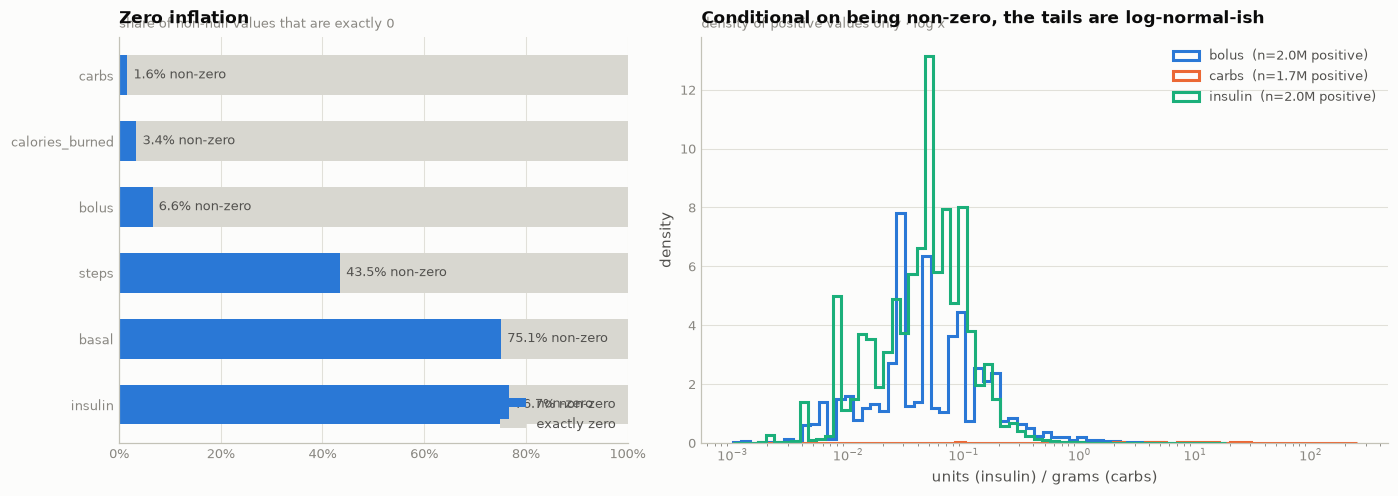

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.4), width_ratios=[1, 1.35])

ax = axes[0]
o = zi.sort_values("pct_zero")
b1 = ax.barh(o.index, o.pct_positive, height=0.6, color=SERIES[0], linewidth=0,
             label="non-zero")
b2 = ax.barh(o.index, o.pct_zero, left=o.pct_positive, height=0.6,
             color=FADE, linewidth=0, label="exactly zero")
for y, (pos, name) in enumerate(zip(o.pct_positive, o.index)):
    ax.text(pos + 1.2, y, f"{pos:.1f}% non-zero", va="center", fontsize=8.2, color=INK2)
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.legend(loc="lower right")
finish(ax, "Zero inflation", "share of non-null values that are exactly 0",
       xgrid=True, ygrid=False)

ax = axes[1]
for i, c in enumerate(["bolus", "carbs", "insulin"]):     # 3 slots = all-pairs CVD safe
    v = df.loc[df[c] > 0, c]
    v = v.sample(min(len(v), 2_000_000), random_state=CFG["seed"]).to_numpy()
    bins = np.logspace(np.log10(max(v.min(), 1e-3)), np.log10(np.quantile(v, .9999)), 60)
    ax.hist(v, bins=bins, density=True, histtype="step", lw=2.0,
            color=SERIES3[i], label=f"{c}  (n={len(v)/1e6:,.1f}M positive)")
ax.set_xscale("log")
ax.legend(loc="upper right")
finish(ax, "Conditional on being non-zero, the tails are log-normal-ish",
       "density of positive values only · log x", xlab="units (insulin) / grams (carbs)",
       ylab="density")
show()

The correct mental model for `bolus` and `carbs` is a **marked point process**: a rare
event (did a dose/meal happen in this 5-minute slot?) carrying a magnitude (how much?).
Feeding the raw column to a learner asks it to model both at once through a
distribution that is 93–98 % a single atom at zero.

The standard fix, and the one the baseline in `gpc/data.py` uses, is to **not use the
instantaneous column at all** — instead integrate it over trailing windows (30 m, 1 h,
2 h, 4 h, 6 h, 24 h) and apply exponential decay kernels for insulin-on-board and
carbs-on-board. That converts a spike train into a smooth, dense, physiologically
meaningful signal.

### 5.5 · Would a transform help?

In [33]:
def skew_after(v, kind):
    if kind == "raw":     x = v
    elif kind == "log1p": x = np.log1p(np.clip(v, 0, None))
    elif kind == "sqrt":  x = np.sqrt(np.clip(v, 0, None))
    elif kind == "cbrt":  x = np.cbrt(v)
    elif kind == "rank":                      # rank-gauss / inverse-normal
        from scipy.special import ndtri
        r = pd.Series(v).rank(pct=True).to_numpy()
        x = ndtri(np.clip(r, 1e-6, 1-1e-6))
    return float(pd.Series(x).skew())

cand = ["CGM", "insulin", "basal", "bolus", "carbs", "heartrate", "steps",
        "calories_burned", "age_of_diagnosis", "height", "weight", "workout_duration"]
tf = []
for c in cand:
    v = df[c].dropna()
    v = v.sample(min(len(v), 2_000_000), random_state=CFG["seed"]).to_numpy()
    row = dict(column=c)
    for k in ["raw", "log1p", "sqrt", "cbrt", "rank"]:
        try:    row[k] = skew_after(v, k)
        except Exception: row[k] = np.nan
    tf.append(row)
tf = pd.DataFrame(tf).set_index("column")
tf["best"] = tf[["raw", "log1p", "sqrt", "cbrt", "rank"]].abs().idxmin(axis=1)
tf.round(3)

,raw,log1p,sqrt,cbrt,rank,best
column,,,,,,
CGM,1.134,0.083,0.599,0.425,-0.002,rank
insulin,14.87,6.616,4.484,1.181,0.374,rank
basal,163.4,2.696,0.486,-0.397,0.396,rank
bolus,15.56,8.213,7.504,5.469,3.761,rank
carbs,15.7,8.248,9.25,8.399,7.859,rank
heartrate,0.902,0.274,0.565,0.463,0,rank
steps,6.569,0.755,2.148,1.224,0.977,log1p
calories_burned,186.7,6.896,24.08,9.008,5.365,rank
age_of_diagnosis,1.588,-0.201,0.582,0.179,0.055,rank


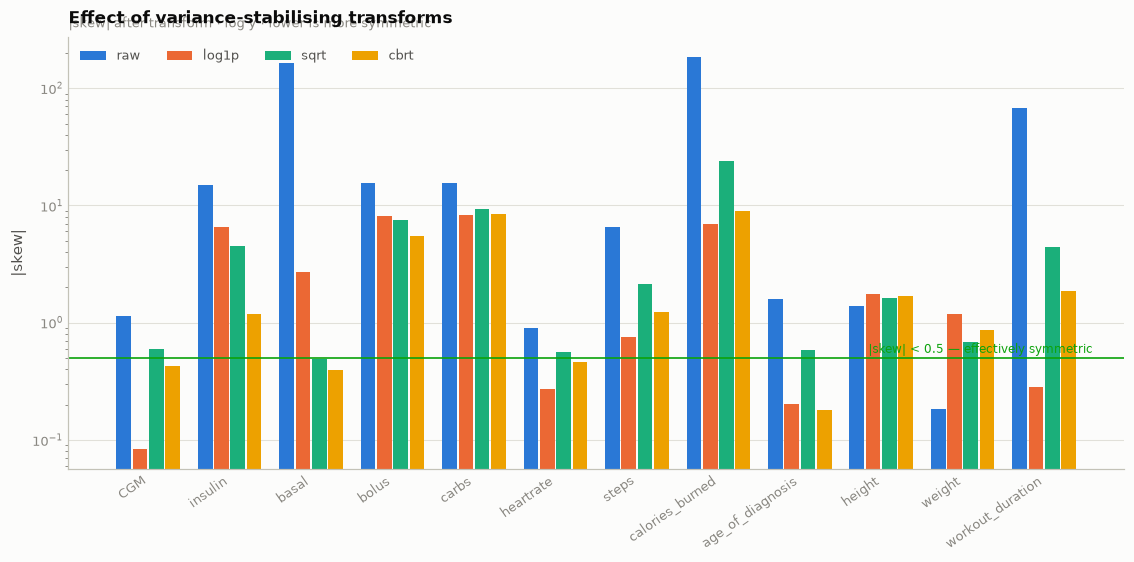


recommended transform per column (minimises |skew|):
  CGM                        1.13  →   -0.002   via rank
  insulin                   14.87  →    0.374   via rank
  basal                    163.43  →    0.396   via rank
  bolus                     15.56  →    3.761   via rank
  carbs                     15.70  →    7.859   via rank
  heartrate                  0.90  →    0.000   via rank
  steps                      6.57  →    0.755   via log1p
  calories_burned          186.72  →    5.365   via rank
  age_of_diagnosis           1.59  →    0.055   via rank
  height                    -1.39  →   -0.001   via rank
  weight                    -0.18  →    0.002   via rank
  workout_duration          67.57  →    0.150   via rank


In [34]:
fig, ax = plt.subplots(figsize=(10.2, 5.0))
kinds = ["raw", "log1p", "sqrt", "cbrt"]
x = np.arange(len(tf)); w = 0.20
for i, k in enumerate(kinds):
    ax.bar(x + (i - 1.5)*w, tf[k].abs(), width=w - 0.02, color=SERIES[i],
           linewidth=0, label=k)                       # 2px gap via width-0.02
ax.set_yscale("log")
ax.set_xticks(x, tf.index, rotation=35, ha="right", fontsize=8.4)
ax.axhline(0.5, color=STATUS["good"], lw=1.1)
ax.text(len(tf)-0.4, 0.52, "|skew| < 0.5 — effectively symmetric",
        fontsize=8, color=STATUS["good"], ha="right", va="bottom")
ax.legend(loc="upper left", ncols=4)
finish(ax, "Effect of variance-stabilising transforms",
       "|skew| after transform · log y · lower is more symmetric", ylab="|skew|")
show()

print("\nrecommended transform per column (minimises |skew|):")
for c, r in tf.iterrows():
    print(f"  {c:<20s} {r.raw:>10,.2f}  →  {r[r.best]:>7.3f}   via {r.best}")

Two caveats before anyone reaches for these.

- **Gradient-boosted trees do not need them.** XGBoost splits on order statistics, so
  any monotone transform of a feature leaves the tree identical. These transforms
  matter for linear models, neural nets, distance metrics, and for *plots*.
- **`rank` (inverse-normal) is a leak hazard.** The ranking must be fitted on train and
  applied to test; fitting it on the concatenation quietly leaks the test marginal.

### 5.6 · Tails and outliers

In [35]:
tails = []
for c in NUM:
    v = df[c].dropna()
    if len(v) < 1000:
        continue
    q1, q3 = v.quantile([.25, .75]); iqr = q3 - q1
    med = v.median()
    mad = numstats.loc[c, "mad"]
    hi_iqr = q3 + 3*iqr                                  # "far out" fence
    n_far  = int((v > hi_iqr).sum()) + int((v < q1 - 3*iqr).sum())
    # modified z-score, robust to the very outliers we are hunting
    mz = 0.6745 * (v.max() - med) / mad if mad > 0 else np.inf
    tails.append(dict(column=c, median=med, p999=v.quantile(.999), max=v.max(),
                      max_over_p999=v.max()/max(v.quantile(.999), 1e-9),
                      far_out_n=n_far, far_out_pct=n_far/len(v)*100,
                      max_modified_z=mz))
tails = pd.DataFrame(tails).set_index("column").sort_values("max_over_p999", ascending=False)
tails.round(2)

,median,p999,max,max_over_p999,far_out_n,far_out_pct,max_modified_z
column,,,,,,,
calories_burned,0,67,2.173e+04,324.3,1245429,3.41,inf
basal,0.06,0.9,68,75.21,1867785,1.37,908.9
workout_duration,15,386.7,"8,218",21.25,4375,4.49,inf
carbs,0,70,855,12.21,1688055,1.63,inf
insulin,0.07,9,94,10.44,5103259,3.63,"1,170"
bolus,0,8.9,50,5.62,9059475,6.58,inf
steps,0,"1,470","3,920",2.67,93775,9.74,inf
galvanic_skin_response,0.01,51.47,75.07,1.46,21580,14.64,"4,318"
heartrate,76,157,199.3,1.27,1451,0.14,7.77


In [36]:
susp = tails[(tails.max_over_p999 > 3) | (tails.max_modified_z > 50)]
print("columns whose maximum is far beyond the bulk of the distribution\n" + "="*78)
for c, r in susp.iterrows():
    print(f"  {c:<24s} p99.9 {r.p999:>12,.1f}   max {r['max']:>14,.1f}   "
          f"{r.max_over_p999:>7,.1f}x   modified-z {r.max_modified_z:>10,.0f}")

print("\nthe five largest values of each suspect column:")
for c in susp.index:
    top5 = df[c].dropna().nlargest(5).to_numpy()
    print(f"  {c:<24s} {np.array2string(top5, precision=1, separator='  ')}")

columns whose maximum is far beyond the bulk of the distribution
  calories_burned          p99.9         67.0   max       21,726.0     324.3x   modified-z        inf
  basal                    p99.9          0.9   max           68.0      75.2x   modified-z        909
  workout_duration         p99.9        386.7   max        8,218.0      21.3x   modified-z        inf
  carbs                    p99.9         70.0   max          855.0      12.2x   modified-z        inf
  insulin                  p99.9          9.0   max           94.0      10.4x   modified-z      1,170
  bolus                    p99.9          8.9   max           50.0       5.6x   modified-z        inf
  steps                    p99.9      1,469.8   max        3,920.0       2.7x   modified-z        inf
  galvanic_skin_response   p99.9         51.5   max           75.1       1.5x   modified-z      4,318

the five largest values of each suspect column:
  calories_burned          [21726.  21056.  17589.  17500.  15871.]
  

### 5.7 · Inferring the units nobody wrote down

In [37]:
checks = [
    ("height",    "feet",       (4.0, 6.5),   "metres would be 1.2–2.0; cm would be 120–200"),
    ("weight",    "pounds",     (90, 260),    "kg would be 40–120"),
    ("skin_temp", "°F",         (80, 98),     "°C would be 28–37"),
    ("air_temp",  "°F",         (60, 100),    "°C would be 15–38"),
    ("CGM",       "mg/dL",      (70, 300),    "mmol/L would be 4–17"),
    ("heartrate", "bpm",        (55, 110),    "—"),
]
print(f"{'column':<12} {'p05':>9} {'median':>9} {'p95':>9}   {'inferred':<8} plausibility check")
print("-"*104)
for c, unit, (lo, hi), alt in checks:
    v = df[c].dropna()
    if len(v) == 0:
        continue
    p5, med, p95 = v.quantile([.05, .5, .95])
    ok = "✓" if lo <= med <= hi else "✗"
    print(f"{c:<12} {p5:>9,.2f} {med:>9,.2f} {p95:>9,.2f}   {unit:<8} {ok}  {alt}")

print("\nThe corpus mixes imperial and metric-derived units across columns without "
      "\ndeclaring either. Convert explicitly before any BMI / dose-per-kg feature:")
h_m  = df["height"].dropna().sample(2_000_000, random_state=0) * 0.3048
w_kg = df["weight"].dropna().sample(2_000_000, random_state=0) * 0.45359237
print(f"  height  median {h_m.median():.2f} m      (plausible adult/paediatric mix)")
print(f"  weight  median {w_kg.median():.1f} kg")

column             p05    median       p95   inferred plausibility check
--------------------------------------------------------------------------------------------------------
height            3.50      5.45      6.17   feet     ✓  metres would be 1.2–2.0; cm would be 120–200
weight           43.00    150.00    229.28   pounds   ✓  kg would be 40–120
skin_temp        80.75     87.53     93.38   °F       ✓  °C would be 28–37
air_temp         77.90     84.20     92.66   °F       ✓  °C would be 15–38
CGM              75.00    135.00    265.00   mg/dL    ✓  mmol/L would be 4–17
heartrate        55.92     76.00    109.00   bpm      ✓  —

The corpus mixes imperial and metric-derived units across columns without 
declaring either. Convert explicitly before any BMI / dose-per-kg feature:
  height  median 1.66 m      (plausible adult/paediatric mix)
  weight  median 68.0 kg


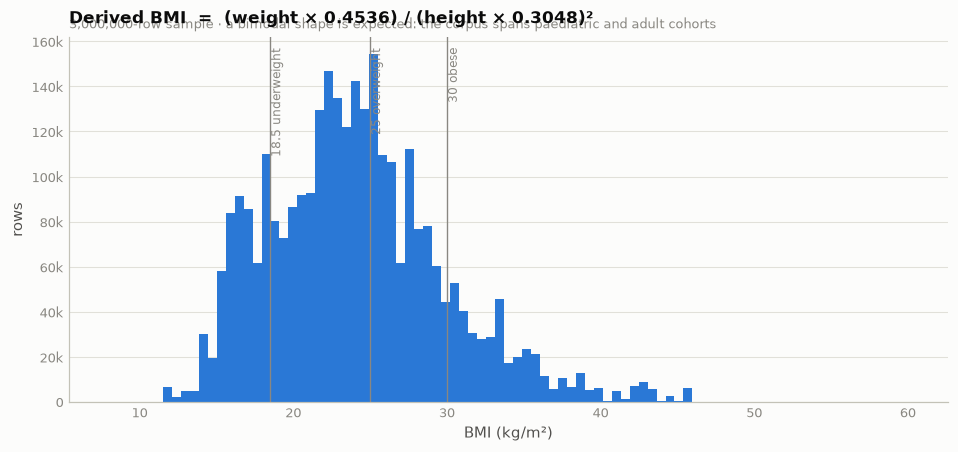

BMI median 23.7 · p01 14.1 · p99 42.3 · implausible (<10 or >60): 0.000%


In [38]:
# BMI needs height and weight on the SAME rows -- do it on the subject table later,
# but a quick row-level sanity pass costs nothing.
hw = df[["height", "weight"]].dropna()
hw = hw.sample(min(len(hw), 3_000_000), random_state=CFG["seed"])
bmi = (hw.weight * 0.45359237) / (hw.height * 0.3048)**2

fig, ax = plt.subplots(figsize=(8.6, 4.0))
ax.hist(bmi, bins=np.linspace(8, 60, 90), color=SERIES[0], linewidth=0)
for x, lbl, col in [(18.5, "18.5 underweight", MUTED), (25, "25 overweight", MUTED),
                    (30, "30 obese", MUTED)]:
    ax.axvline(x, color=col, lw=0.9)
    ax.text(x, ax.get_ylim()[1]*0.97, f" {lbl}", fontsize=7.6, color=col,
            rotation=90, va="top", ha="left")
ax.yaxis.set_major_formatter(KFMT)
finish(ax, "Derived BMI  =  (weight × 0.4536) / (height × 0.3048)²",
       f"{len(bmi):,}-row sample · a bimodal shape is expected: the corpus spans "
       "paediatric and adult cohorts", xlab="BMI (kg/m²)", ylab="rows")
show()
print(f"BMI median {bmi.median():.1f} · p01 {bmi.quantile(.01):.1f} · "
      f"p99 {bmi.quantile(.99):.1f} · implausible (<10 or >60): "
      f"{((bmi<10)|(bmi>60)).mean()*100:.3f}%")

---
## 6 · Univariate analysis — categorical columns

Twelve string columns. The interesting failure here is not missingness — it is
**label hygiene**. This corpus was concatenated from 14 studies that each wrote their
own free text, and nobody normalised afterwards. `Humalog`, `humalog`, and
`Humalog (Lispro)` are three levels for one drug; `Non-binary` and `Non Binary` are
two levels for one gender. Any model that one-hot encodes these treats them as
unrelated, and any join or `groupby` on them silently fragments.

### 6.1 · Cardinality

In [39]:
cat_prof = (prof[prof["column"].isin(CAT + FLAG)]
            [["column", "kind", "nunique", "non_null", "null_pct", "semantic"]]
            .sort_values("nunique", ascending=False).reset_index(drop=True))
cat_prof

,column,kind,nunique,non_null,null_pct,semantic
0,meal_label,categorical,2385,91137,99.94,categorical (high card.)
1,id,categorical,1291,154842077,0,categorical (high card.)
2,workout_label,categorical,80,114010,99.93,categorical (high card.)
3,ethnicity,categorical,30,144725281,6.534,categorical (low card.)
4,insulin_delivery_device,categorical,26,146954385,5.094,categorical (low card.)
5,insulin_type_basal,categorical,20,142723508,7.826,categorical (low card.)
6,insulin_type_bolus,categorical,17,141896128,8.361,categorical (low card.)
7,source_file,categorical,14,154842077,0,categorical (low card.)
8,insulin_delivery_algorithm,categorical,10,151192712,2.357,categorical (low card.)
9,cgm_device,categorical,9,146438567,5.427,categorical (low card.)


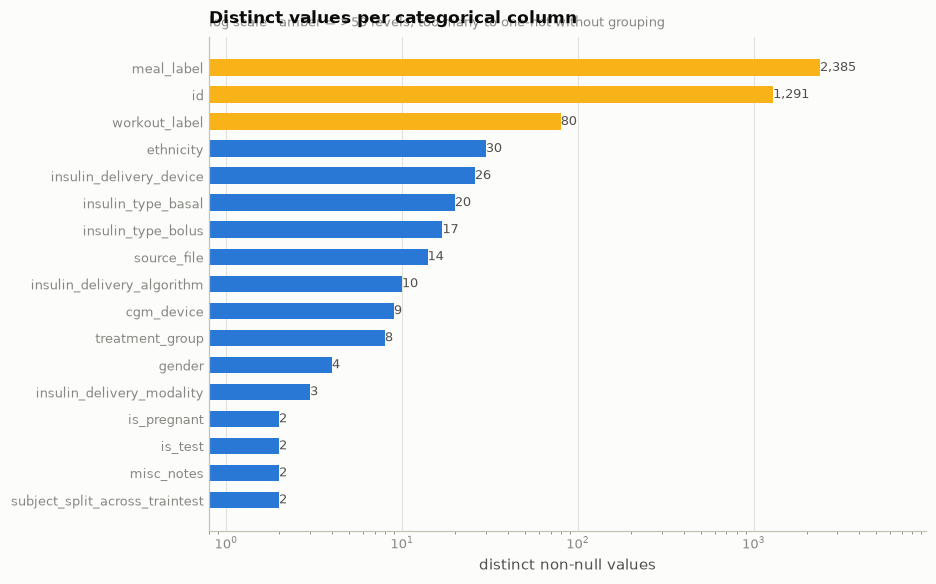

In [40]:
cp = cat_prof[cat_prof["nunique"] > 0].sort_values("nunique")
cpn = cp["nunique"].to_numpy()
fig, ax = plt.subplots(figsize=(8.4, 5.2))
bars = ax.barh(cp["column"], cpn, height=0.62, color=SERIES[0], linewidth=0)
ax.set_xscale("log")
ax.set_xlim(0.8, cpn.max()*4)
barh_labels(ax, bars, [f"{v:,}" for v in cpn], pad=0.0)
for b, v in zip(bars, cpn):
    b.set_color(STATUS["warning"] if v > 50 else SERIES[0])
finish(ax, "Distinct values per categorical column",
       "log scale · amber = >50 levels, too many to one-hot without grouping",
       xlab="distinct non-null values", xgrid=True, ygrid=False)
show()

### 6.2 · Level composition of the low-cardinality columns

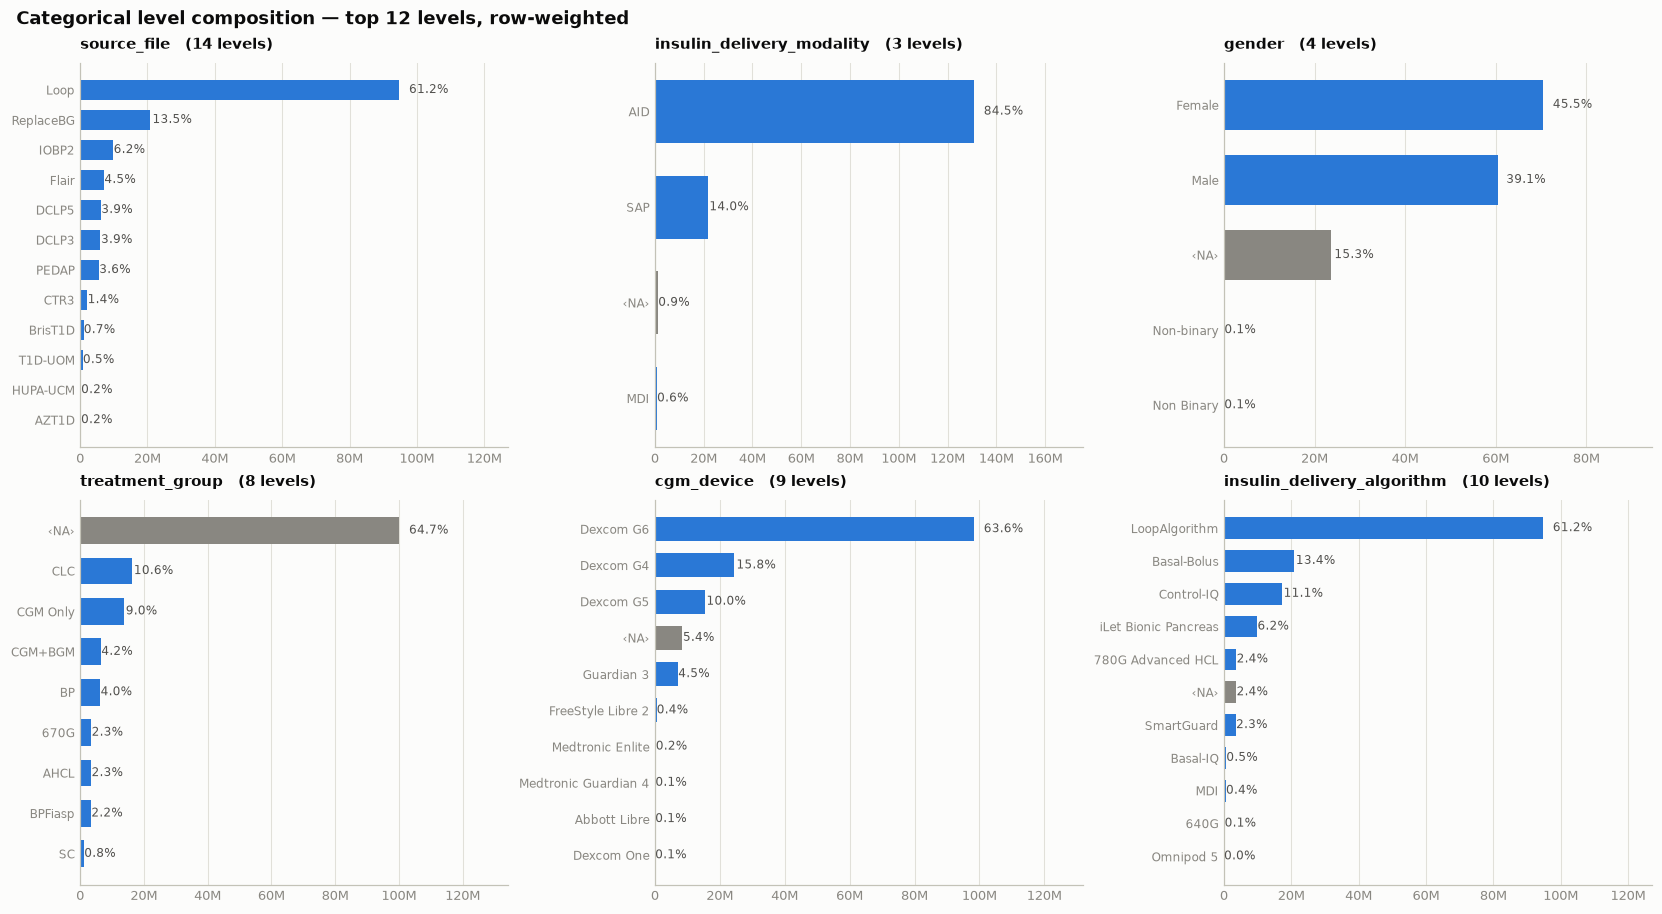

In [41]:
low = ["source_file", "insulin_delivery_modality", "gender", "treatment_group",
       "cgm_device", "insulin_delivery_algorithm"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8.2))
for ax, c in zip(axes.ravel(), low):
    vc = df[c].value_counts(dropna=False).head(12)
    lbl = ["‹NA›" if (k is None or (isinstance(k, float) and np.isnan(k))) else str(k)[:26]
           for k in vc.index][::-1]
    val = vc.values[::-1]
    cols = [MUTED if l == "‹NA›" else SERIES[0] for l in lbl]
    bars = ax.barh(range(len(val)), val, height=0.66, color=cols, linewidth=0)
    ax.set_yticks(range(len(val)), lbl, fontsize=8)
    ax.set_xlim(0, val.max()*1.34)
    ax.xaxis.set_major_formatter(KFMT)
    for b, v in zip(bars, val):
        ax.text(b.get_width()*1.03, b.get_y()+b.get_height()/2,
                f"{v/N_ROWS*100:.1f}%", va="center", fontsize=7.6, color=INK2)
    ax.set_title(f"{c}   ({df[c].nunique():,} levels)", loc="left", fontsize=9.5)
    ax.xaxis.grid(True); ax.yaxis.grid(False)
fig.suptitle("Categorical level composition — top 12 levels, row-weighted",
             x=0.006, ha="left", fontsize=12, color=INK, weight="600")
show()

### 6.3 · Label hygiene: how many levels are actually duplicates?

In [42]:
import re
def normalise(s):
    if s is None or (isinstance(s, float) and np.isnan(s)):
        return None
    s = str(s).lower().strip()
    s = re.sub(r"\(.*?\)", " ", s)          # drop parenthetical generic names
    s = re.sub(r"[^a-z0-9]+", " ", s)       # punctuation / hyphens / slashes -> space
    s = re.sub(r"\s+", " ", s).strip()
    return s or None

audit = []
for c in ["insulin_type_basal", "insulin_type_bolus", "gender", "ethnicity",
          "cgm_device", "insulin_delivery_device", "insulin_delivery_algorithm",
          "workout_label", "treatment_group"]:
    vc = df[c].value_counts()
    grp = {}
    for raw, n in vc.items():
        grp.setdefault(normalise(raw), []).append((raw, n))
    collapsed = {k: v for k, v in grp.items() if len(v) > 1}
    audit.append(dict(column=c, raw_levels=len(vc), normalised_levels=len(grp),
                      levels_removed=len(vc) - len(grp),
                      colliding_groups=len(collapsed),
                      rows_affected=sum(n for v in collapsed.values() for _, n in v[1:])))
audit = pd.DataFrame(audit).set_index("column")
audit["pct_rows_affected"] = (audit.rows_affected / N_ROWS * 100).round(3)
audit

,raw_levels,normalised_levels,levels_removed,colliding_groups,rows_affected,pct_rows_affected
column,,,,,,
insulin_type_basal,20,13,7,5,5961190,3.85
insulin_type_bolus,17,11,6,4,5961189,3.85
gender,4,3,1,1,88699,0.057
ethnicity,30,28,2,2,633561,0.409
cgm_device,9,9,0,0,0,0
insulin_delivery_device,26,26,0,0,0,0
insulin_delivery_algorithm,10,10,0,0,0,0
workout_label,80,80,0,0,0,0
treatment_group,8,8,0,0,0,0


In [43]:
print("collapsing groups, worst offenders\n" + "="*84)
for c in ["insulin_type_bolus", "gender", "ethnicity", "insulin_delivery_algorithm"]:
    vc = df[c].value_counts()
    grp = {}
    for raw, n in vc.items():
        grp.setdefault(normalise(raw), []).append((raw, n))
    bad = {k: v for k, v in grp.items() if len(v) > 1}
    bad = dict(sorted(bad.items(), key=lambda kv: -sum(n for _, n in kv[1]))[:4])
    if not bad:
        continue
    print(f"\n{c}")
    for norm, members in bad.items():
        print(f"   normalises to “{norm}”")
        for raw, n in sorted(members, key=lambda t: -t[1]):
            print(f"       {raw:<44s} {n:>13,}")

collapsing groups, worst offenders

insulin_type_bolus
   normalises to “humalog”
       Humalog (Lispro)                                67,737,897
       Humalog                                          1,406,737
       humalog                                            111,913
   normalises to “novolog”
       Novolog (Aspart)                                55,446,143
       NovoLog                                            653,011
   normalises to “fiasp”
       Fiasp (Rapid Aspart)                             9,972,427
       Fiasp                                            3,419,440
   normalises to “apidra”
       Apidra (Glusine)                                 2,138,319
       Apidra (Glulisine)                                 259,752
       Apidra                                             110,336

gender
   normalises to “non binary”
       Non-binary                                         108,645
       Non Binary                                          88,699

ethnicity

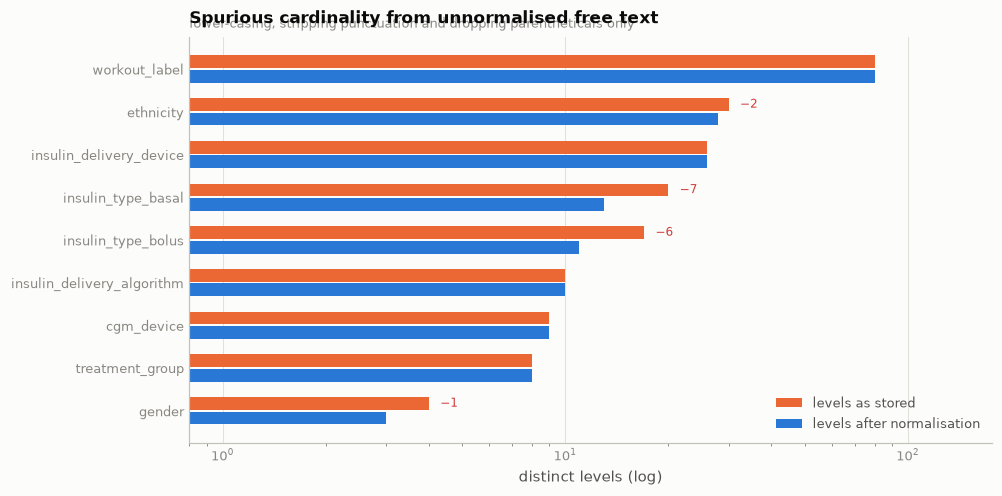

In [44]:
fig, ax = plt.subplots(figsize=(9.0, 4.4))
a = audit.sort_values("raw_levels")
y = np.arange(len(a))
ax.barh(y + 0.17, a.raw_levels, height=0.30, color=SERIES[1], linewidth=0,
        label="levels as stored")
ax.barh(y - 0.17, a.normalised_levels, height=0.30, color=SERIES[0], linewidth=0,
        label="levels after normalisation")
ax.set_yticks(y, a.index, fontsize=8.6)
ax.set_xscale("log"); ax.set_xlim(0.8, a.raw_levels.max()*2.2)
for yy, (r, n) in enumerate(zip(a.raw_levels, a.normalised_levels)):
    if r != n:
        ax.text(r*1.08, yy + 0.17, f"−{r-n}", va="center", fontsize=8,
                color=STATUS["critical"])
ax.legend(loc="lower right")
finish(ax, "Spurious cardinality from unnormalised free text",
       "lower-casing, stripping punctuation and dropping parentheticals only",
       xlab="distinct levels (log)", xgrid=True, ygrid=False)
show()

### 6.4 · Long tails and concentration

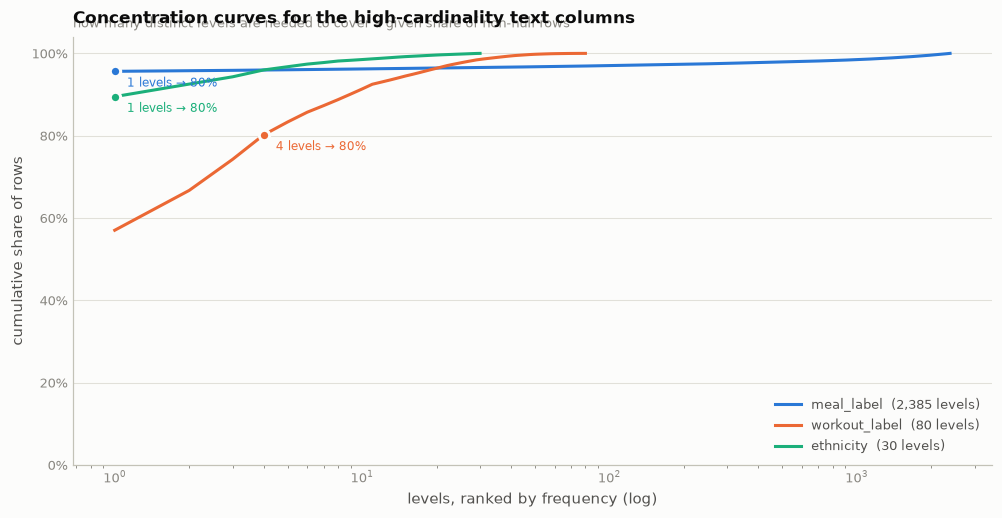


meal_label — top 12 of 2,385
meal_label
Meal                        87161
Meal without description      135
Standard breakfast             85
porridge                       83
Coffee                         44
Coffee(x3)                     40
Banana                         39
Huel+Peanutbutter              38
Apple                          35
Muesli+SoyaMilk                34
Crisps                         33
Tea, Coffe & Breakfast 1       32

workout_label — top 12 of 80
workout_label
Walking                             65010
Walk                                11037
Running                              8634
Cycling                              6756
High Intensity Interval Training     3565
Other Activity                       2706
Elliptical                           1842
Traditional Strength Training        1655
Generic                              1536
Swimming                             1400
Yoga                                 1316
Stairs                                619


In [45]:
hi_card = ["meal_label", "workout_label", "ethnicity", "misc_notes", "id"]
fig, ax = plt.subplots(figsize=(9.0, 4.6))
for i, c in enumerate(hi_card[:3]):        # 3 series = all-pairs CVD safe
    vc = df[c].value_counts()
    cum = vc.cumsum() / vc.sum() * 100
    ax.plot(np.arange(1, len(cum)+1), cum.to_numpy(), color=SERIES3[i], lw=2.0,
            label=f"{c}  ({len(vc):,} levels)")
    k80 = int((cum < 80).sum()) + 1
    ax.scatter([k80], [cum.iloc[k80-1]], s=46, color=SERIES3[i], zorder=4,
               edgecolor=SURFACE, linewidth=2)
    ax.annotate(f"{k80} levels → 80%", (k80, cum.iloc[k80-1]), xytext=(8, -10),
                textcoords="offset points", fontsize=8, color=SERIES3[i])
ax.set_xscale("log"); ax.set_ylim(0, 104)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.legend(loc="lower right")
finish(ax, "Concentration curves for the high-cardinality text columns",
       "how many distinct levels are needed to cover a given share of non-null rows",
       xlab="levels, ranked by frequency (log)", ylab="cumulative share of rows")
show()

for c in ["meal_label", "workout_label"]:
    print(f"\n{c} — top 12 of {df[c].nunique():,}")
    print(df[c].value_counts().head(12).to_string())

30 stored combinations decompose into 14 atomic categories:

ethnicity
White                                    94.13
Hispanic/Latino                           4.74
Asian                                     2.97
Black/African American                    1.72
Black/African-American                    0.91
More than one race                        0.63
American Indian/Alaskan Native            0.29
Unknown/not reported                      0.18
Native Hawaiian/Other Pacific Islander    0.15
Middle Eastern                            0.05
African American                          0.04
Native American                           0.04
Pakistani                                 0.04
Haitian                                   0.04


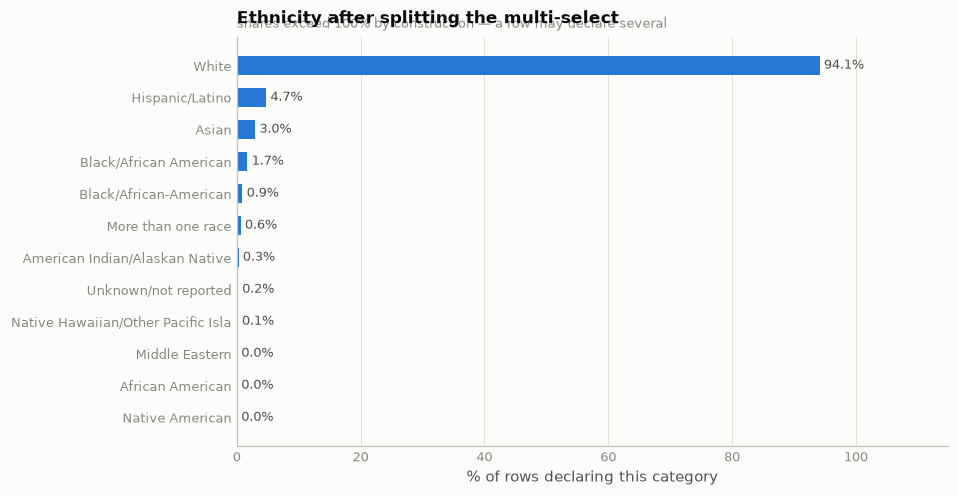

In [46]:
# ethnicity is a comma-joined MULTI-SELECT, not a categorical. Explode it.
eth = df["ethnicity"].dropna()
eth = eth.sample(min(len(eth), 20_000_000), random_state=CFG["seed"])
parts = eth.str.split(",").explode().str.strip()
vc = parts.value_counts()
print(f"{eth.nunique()} stored combinations decompose into {len(vc)} atomic categories:\n")
print((vc / len(eth) * 100).round(2).head(20).to_string())

fig, ax = plt.subplots(figsize=(8.6, 4.4))
o = (vc/len(eth)*100).head(12).iloc[::-1]
bars = ax.barh(o.index.str[:34], o.values, height=0.62, color=SERIES[0], linewidth=0)
ax.set_xlim(0, o.max()*1.22)
barh_labels(ax, bars, [f"{v:.1f}%" for v in o.values])
finish(ax, "Ethnicity after splitting the multi-select",
       "shares exceed 100% by construction — a row may declare several",
       xlab="% of rows declaring this category", xgrid=True, ygrid=False)
show()

---
## 7 · Temporal structure

The most consequential single fact in this notebook, and the one most likely to be
assumed wrong:

> **The corpus is a dense 5-minute lattice.** Of 154,840,168 adjacent within-subject
> row pairs, **154,840,166 are exactly 300 seconds apart**. Rows are already sorted by
> subject and time, and 1,905 of 1,907 subjects have not a single missing timestamp.

That means **a gap in the data is almost never a missing row — it is a run of NaN**.
Any "resample onto a regular grid" step is a no-op, and any gap detector that looks
for time jumps will find nothing and conclude the data is clean. Gap analysis has to
be done on NaN run-lengths instead, which is what 7.4 does.

The two exceptions are real and they bite — 7.1 finds them.

### 7.1 · Proving the lattice (and finding the two rows that break it)

In [47]:
# Factorise the string keys once: integer comparison over 154M rows is ~40x faster
# than object comparison, and every later section reuses these.
t0 = time.time()
SRC_CODE = pd.factorize(df["source_file"])[0]
ID_CODE  = pd.factorize(df["id"])[0]
DATES    = df["date"].to_numpy()

# SAME[i] is True when row i belongs to the same subject as row i-1.
SAME = (SRC_CODE[1:] == SRC_CODE[:-1]) & (ID_CODE[1:] == ID_CODE[:-1])
BND  = np.concatenate(([False], SAME))           # aligned to rows; False starts a subject
print(f"key factorisation + boundary scan: {time.time()-t0:.1f}s")

delta = (DATES[1:] - DATES[:-1]).astype("timedelta64[s]").astype(np.int64)
within = delta[SAME]

print(f"\nadjacent row pairs inside one subject : {SAME.sum():,}")
print(f"subject boundaries                    : {(~SAME).sum():,}")
print(f"contiguous subject blocks             : {(~SAME).sum()+1:,}")
print(f"distinct (source_file, id) subjects   : {df.groupby(SUBJ_KEY, observed=True).ngroups:,}")
print(f"strictly increasing in time           : {(within > 0).all()}")

uniq, cnt = np.unique(within, return_counts=True)
print("\ndistinct within-subject time deltas:")
for u, c in sorted(zip(uniq, cnt), key=lambda t: -t[1]):
    print(f"   {u:>12,} s = {u/60:>12,.1f} min      {c:>15,} pairs "
          f"({c/len(within)*100:.6f}%)")

LATTICE_S = int(uniq[np.argmax(cnt)])
print(f"\n→ lattice resolution: {LATTICE_S/60:.0f} minutes")
assert LATTICE_S == CFG["grid_min"]*60, "CFG['grid_min'] disagrees with the data"

key factorisation + boundary scan: 71.8s

adjacent row pairs inside one subject : 154,840,168
subject boundaries                    : 1,908
contiguous subject blocks             : 1,909
distinct (source_file, id) subjects   : 1,907
strictly increasing in time           : False

distinct within-subject time deltas:
            300 s =          5.0 min          154,840,166 pairs (99.999999%)
     -3,431,400 s =    -57,190.0 min                    1 pairs (0.000001%)
     10,227,000 s =    170,450.0 min                    1 pairs (0.000001%)

→ lattice resolution: 5 minutes


In [48]:
# Exactly two pairs break the lattice. Look at them.
broken = np.flatnonzero(SAME & (delta != LATTICE_S))
print(f"lattice violations: {len(broken)}\n")
for i in broken:
    blk = df.iloc[i-1:i+3][["source_file", "id", "date", "CGM"]]
    print(blk.to_string())
    print(f"   jump = {delta[i]:,} s = {delta[i]/86400:+.2f} days"
          f"{'   ← TIME GOES BACKWARDS' if delta[i] < 0 else ''}\n")

# Which subjects are stored as more than one contiguous block?
blk_id = np.cumsum(np.concatenate(([True], ~SAME)))
nblk = (pd.DataFrame({"blk": blk_id, "s": SRC_CODE, "i": ID_CODE})
        .groupby(["s", "i"], observed=True)["blk"].nunique())
multi = nblk[nblk > 1]
print(f"subjects stored as >1 contiguous block: {len(multi)}")
print(df.iloc[np.isin(SRC_CODE, multi.index.get_level_values(0)) &
              np.isin(ID_CODE, multi.index.get_level_values(1))]
        .groupby(SUBJ_KEY, observed=True)["date"]
        .agg(["size", "min", "max"]).to_string())

lattice violations: 2

            source_file    id                date  CGM
153990706  ShanghaiT1DM  1006 2021-02-23 11:45:00  NaN
153990707  ShanghaiT1DM  1006 2021-02-23 11:50:00 88.2
153990708  ShanghaiT1DM  1006 2021-01-14 18:40:00 57.6
153990709  ShanghaiT1DM  1006 2021-01-14 18:45:00  NaN
   jump = -3,431,400 s = -39.72 days   ← TIME GOES BACKWARDS

            source_file    id                date  CGM
154012955  ShanghaiT1DM  1002 2021-05-14 07:15:00  NaN
154012956  ShanghaiT1DM  1002 2021-05-14 07:20:00 73.8
154012957  ShanghaiT1DM  1002 2021-09-09 16:10:00 64.8
154012958  ShanghaiT1DM  1002 2021-09-09 16:15:00  NaN
   jump = 10,227,000 s = +118.37 days

subjects stored as >1 contiguous block: 2
                    size                 min                 max
source_file  id                                                 
ShanghaiT1DM 1002   6711 2021-05-04 10:35:00 2021-09-13 09:10:00
             1006  11124 2021-01-14 18:40:00 2021-03-15 10:40:00


In [49]:
# Independent confirmation: a dense lattice implies rows == span/5min + 1, exactly.
chk = (df.groupby(SUBJ_KEY, observed=True)
         .agg(rows=("date", "size"), first=("date", "min"), last=("date", "max")))
chk["expected_rows"] = (chk["last"] - chk["first"]).dt.total_seconds()/LATTICE_S + 1
chk["missing_slots"] = chk.expected_rows - chk.rows

ok = (chk.missing_slots.abs() < 1e-6).sum()
print(f"subjects                                 : {len(chk):,}")
print(f"subjects with rows == expected exactly   : {ok:,}  ({ok/len(chk)*100:.2f}%)")
print(f"subjects with absent timestamps          : {len(chk)-ok:,}\n")
chk[chk.missing_slots.abs() > 1e-6]

subjects                                 : 1,907
subjects with rows == expected exactly   : 1,905  (99.90%)
subjects with absent timestamps          : 2



rows               first                last  expected_rows  missing_slots
source_file  id                                                                               
ShanghaiT1DM 1002   6711 2021-05-04 10:35:00 2021-09-13 09:10:00        3.8e+04      3.129e+04
             1006  11124 2021-01-14 18:40:00 2021-03-15 10:40:00      1.718e+04          6,061

**Two ShanghaiT1DM participants are stored as two separate wear periods concatenated
together**, with the intervening months simply absent rather than present-as-NaN. For
`id 1006` the second block is stored *before* the first in calendar time, so a raw
`.shift()` would compute a "5-minute lag" across a **39.7-day backwards jump**.

Everything downstream therefore masks lag/lead windows against the subject-boundary
array `BND` rather than trusting row adjacency. The helpers below are the only
sanctioned way to take a lag in this notebook.

In [50]:
# BLK gives every CONTIGUOUS run of one subject its own integer id. Because the two
# ShanghaiT1DM subjects above are stored as two separate blocks, they get two ids each
# -- which is exactly right: their wear periods must never be lagged into each other.
BLK = np.cumsum(~BND)

def lag(a, k, blk=None):
    """a[i-k], NaN wherever the k-row window leaves the current contiguous block."""
    blk = BLK if blk is None else blk
    n = len(a); out = np.full(n, np.nan)
    out[k:] = a[:-k]
    out[k:][blk[k:] != blk[:-k]] = np.nan
    out[:k] = np.nan
    return out

def lead(a, k, blk=None):
    """a[i+k] -- the future -- with the same block guard."""
    blk = BLK if blk is None else blk
    n = len(a); out = np.full(n, np.nan)
    out[:n-k] = a[k:]
    out[:n-k][blk[k:] != blk[:-k]] = np.nan
    out[n-k:] = np.nan
    return out

print(f"contiguous blocks: {BLK.max():,}  (vs {df.groupby(SUBJ_KEY, observed=True).ngroups:,} subjects)")

# brute-force check on a slice, so the guard is proven rather than asserted
_n = 50_000; _b = BND[:_n]; _blk = np.cumsum(~_b); _a = np.arange(_n, dtype=float)
for _k in (1, 6, 24):
    _got  = lag(_a, _k, _blk)
    _want = np.array([_a[i-_k] if (i >= _k and _b[i-_k+1:i+1].all()) else np.nan
                      for i in range(_n)])
    assert np.array_equal(np.isnan(_got), np.isnan(_want)), f"lag k={_k}"
    _got  = lead(_a, _k, _blk)
    _want = np.array([_a[i+_k] if (i < _n-_k and _b[i+1:i+_k+1].all()) else np.nan
                      for i in range(_n)])
    assert np.array_equal(np.isnan(_got), np.isnan(_want)), f"lead k={_k}"
print("lag / lead block guards verified against brute force ✓")

contiguous blocks: 1,909  (vs 1,907 subjects)
lag / lead block guards verified against brute force ✓


### 7.2 · When each cohort was recorded

findfont: Failed to find font weight 600, now using 700.


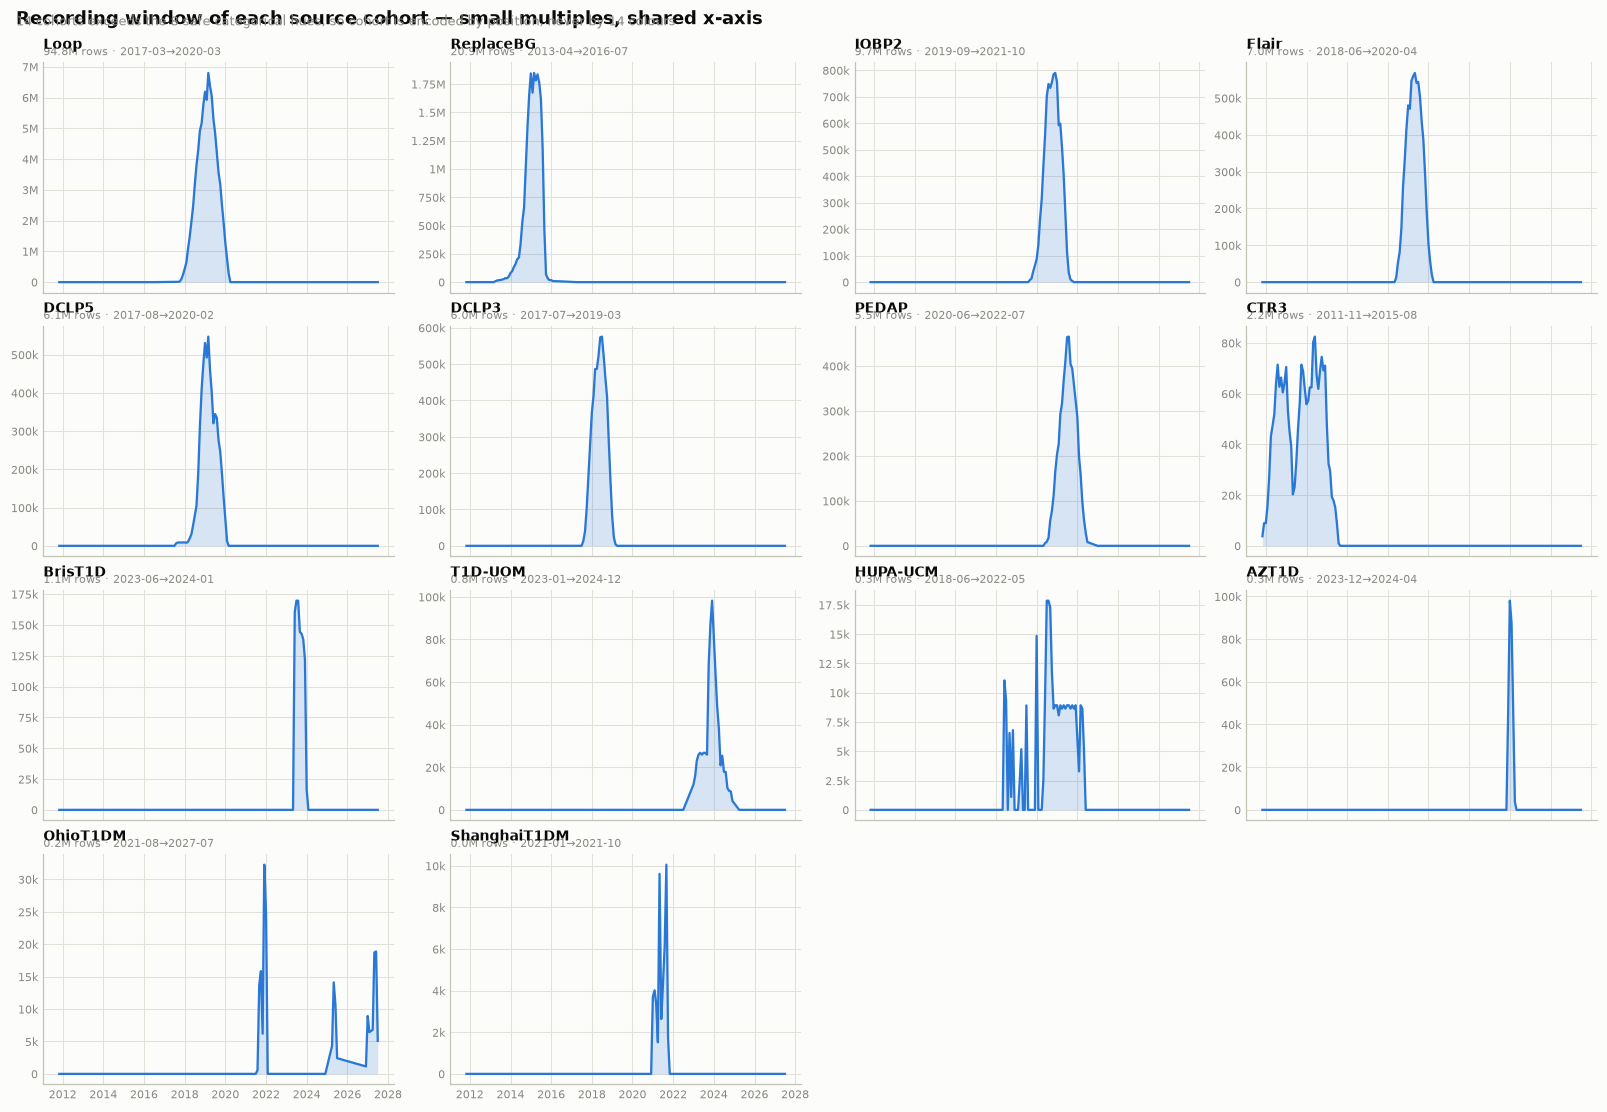

In [51]:
month = DATES.astype("datetime64[M]")
vol = pd.crosstab(pd.Series(month, name="month"), df["source_file"])
vol.index = pd.to_datetime(vol.index)

order = vol.sum().sort_values(ascending=False).index.tolist()
ncol, nrow = 4, math.ceil(len(order)/4)
fig, axes = plt.subplots(nrow, ncol, figsize=(14.5, 2.5*nrow), sharex=True)
axes = np.atleast_1d(axes).ravel()
for ax, c in zip(axes, order):
    s = vol[c]
    ax.fill_between(s.index, s.values, color=SERIES[0], alpha=0.18, linewidth=0)
    ax.plot(s.index, s.values, color=SERIES[0], lw=1.5)
    ax.set_title(c, loc="left", fontsize=9.2)
    active = s[s > 0]
    ax.text(0, 1.02, f"{s.sum()/1e6:,.1f}M rows · "
                     f"{active.index.min():%Y-%m}→{active.index.max():%Y-%m}",
            transform=ax.transAxes, fontsize=7.4, color=MUTED, va="bottom")
    ax.yaxis.set_major_formatter(KFMT)
    ax.tick_params(labelsize=7.4)
for ax in axes[len(order):]:
    ax.set_visible(False)
fig.suptitle("Recording window of each source cohort — small multiples, shared x-axis",
             x=0.006, ha="left", fontsize=12, color=INK, weight="600")
fig.text(0.006, 0.982, "14 cohorts exceeds the 8 safe categorical hues, so cohort is "
                       "encoded by position, never by 14 colours", fontsize=8.5, color=MUTED)
show()

In [52]:
span = (df.groupby("source_file", observed=True)["date"]
          .agg(["min", "max", "size"]).sort_values("min"))
span["span_days"] = (span["max"] - span["min"]).dt.days
span["Mrows"] = (span["size"]/1e6).round(2)
print(f"corpus date range: {df['date'].min()}  →  {df['date'].max()}")
span[["min", "max", "span_days", "Mrows"]]

corpus date range: 2011-11-17 21:00:00  →  2027-07-14 15:30:00


,min,max,span_days,Mrows
source_file,,,,
CTR3,2011-11-17 21:00:00,2015-08-04 08:50:00,1355,2.17
ReplaceBG,2013-04-06 00:50:00,2016-07-23 22:50:00,1204,20.86
Loop,2017-03-05 01:25:00,2020-03-30 01:15:00,1120,94.81
DCLP3,2017-07-31 12:25:00,2019-03-16 23:35:00,593,6.03
DCLP5,2017-08-08 15:50:00,2020-02-16 13:55:00,921,6.1
Flair,2018-06-04 12:15:00,2020-04-01 11:05:00,666,7
HUPA-UCM,2018-06-13 18:40:00,2022-05-18 12:15:00,1434,0.3
IOBP2,2019-09-03 15:30:00,2021-10-16 07:30:00,773,9.68
PEDAP,2020-06-09 15:25:00,2022-07-30 00:00:00,780,5.51


Note the maximum date — it is **in the future**. Timestamps have been shifted per
study for de-identification, so absolute calendar time carries no meaning and
cross-cohort calendar alignment is fictional. What *is* meaningful: time-of-day,
day-of-week, and time elapsed since a subject's own first record.

### 7.3 · Coverage within the day and week

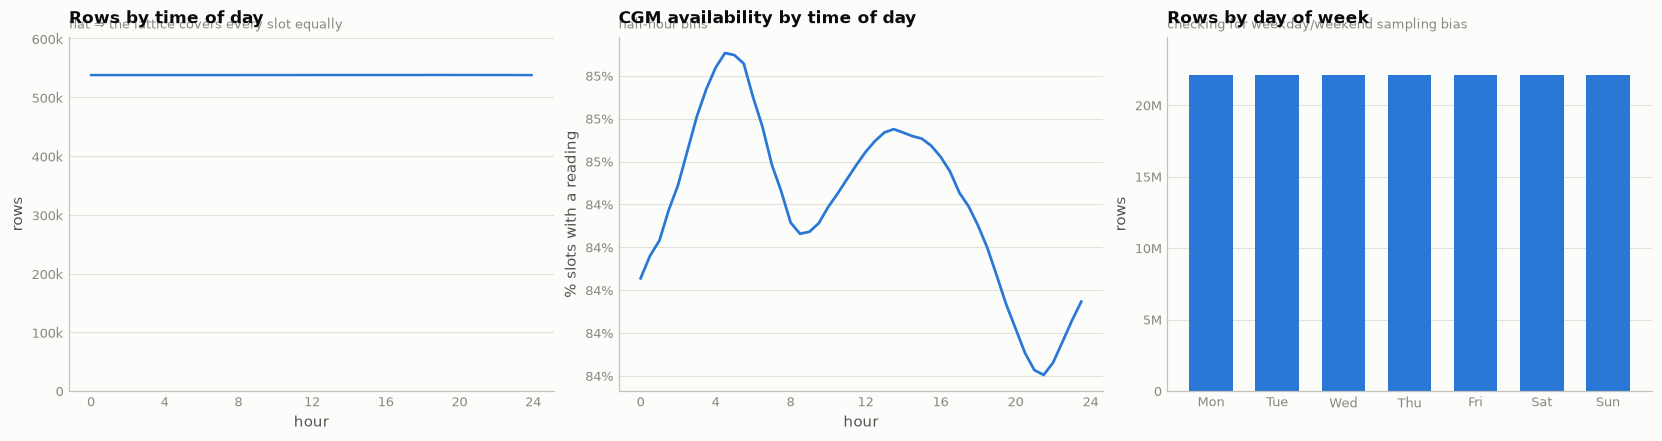

weekday share range: 14.28% – 14.29%


In [53]:
HOUR = df["date"].dt.hour.to_numpy()
MINOFDAY = HOUR*60 + df["date"].dt.minute.to_numpy()
DOW  = df["date"].dt.dayofweek.to_numpy()
HAS_CGM = df["CGM"].notna().to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))

ax = axes[0]
c, e = np.histogram(MINOFDAY, bins=np.arange(0, 1441, CFG["grid_min"]))
ax.plot(e[:-1]/60, c, color=SERIES[0], lw=1.6)
ax.set_ylim(0, c.max()*1.12)
ax.set_xticks(range(0, 25, 4)); ax.yaxis.set_major_formatter(KFMT)
finish(ax, "Rows by time of day", "flat ⇒ the lattice covers every slot equally",
       xlab="hour", ylab="rows")

ax = axes[1]
avail = pd.Series(HAS_CGM).groupby(MINOFDAY // 30).mean() * 100
ax.plot(avail.index/2, avail.values, color=SERIES[0], lw=1.8)
ax.set_xticks(range(0, 25, 4))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
finish(ax, "CGM availability by time of day", "half-hour bins",
       xlab="hour", ylab="% slots with a reading")

ax = axes[2]
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dcount = pd.Series(DOW).value_counts().sort_index()
ax.bar(range(7), dcount.values, width=0.66, color=SERIES[0], linewidth=0)
ax.set_xticks(range(7), names)
ax.yaxis.set_major_formatter(KFMT)
ax.set_ylim(0, dcount.max()*1.12)
finish(ax, "Rows by day of week", "checking for weekday/weekend sampling bias", ylab="rows")
show()
print("weekday share range: "
      f"{dcount.min()/dcount.sum()*100:.2f}% – {dcount.max()/dcount.sum()*100:.2f}%")

### 7.4 · Gaps are NaN runs, not missing rows

In [54]:
t0 = time.time()
missing = ~HAS_CGM
prev_missing = np.concatenate(([False], missing[:-1]))
# a run starts where the slot is missing AND (the previous slot was not missing
# OR this row begins a new subject)
new_run = missing & (~prev_missing | ~BND)
run_id  = np.cumsum(new_run)
lens    = np.bincount(run_id[missing])[1:]
gap_min = lens * CFG["grid_min"]
print(f"computed in {time.time()-t0:.1f}s")
assert lens.sum() == missing.sum()

print(f"\nNaN-CGM runs                 : {len(gap_min):,}")
print(f"total missing slots          : {missing.sum():,}  ({missing.mean()*100:.2f}%)")
print(f"median gap                   : {np.median(gap_min):,.0f} min")
print(f"mean gap                     : {gap_min.mean():,.1f} min")
print(f"p95 / p99 / max              : {np.percentile(gap_min,95):,.0f} / "
      f"{np.percentile(gap_min,99):,.0f} / {gap_min.max():,.0f} min "
      f"({gap_min.max()/1440:,.0f} days)\n")
print(f"{'threshold':>12} {'runs':>14} {'% of runs':>11} {'% of lost time':>16}")
for thr in (5, 10, 15, 30, 60, 120, 360, 1440):
    n = int((gap_min <= thr).sum())
    print(f"{'≤ '+format(thr,',')+' min':>12} {n:>14,} {n/len(gap_min)*100:>10.1f}% "
          f"{gap_min[gap_min<=thr].sum()/gap_min.sum()*100:>15.1f}%")

computed in 365.4s

NaN-CGM runs                 : 1,147,210
total missing slots          : 23,969,238  (15.48%)
median gap                   : 5 min
mean gap                     : 104.5 min
p95 / p99 / max              : 160 / 655 / 915,410 min (636 days)

   threshold           runs   % of runs   % of lost time
     ≤ 5 min        577,884       50.4%             2.4%
    ≤ 10 min        837,008       73.0%             4.6%
    ≤ 15 min        882,645       76.9%             5.1%
    ≤ 30 min        953,134       83.1%             6.6%
    ≤ 60 min      1,020,816       89.0%             9.1%
   ≤ 120 min      1,060,588       92.4%            12.2%
   ≤ 360 min      1,126,779       98.2%            22.7%
 ≤ 1,440 min      1,141,533       99.5%            30.9%


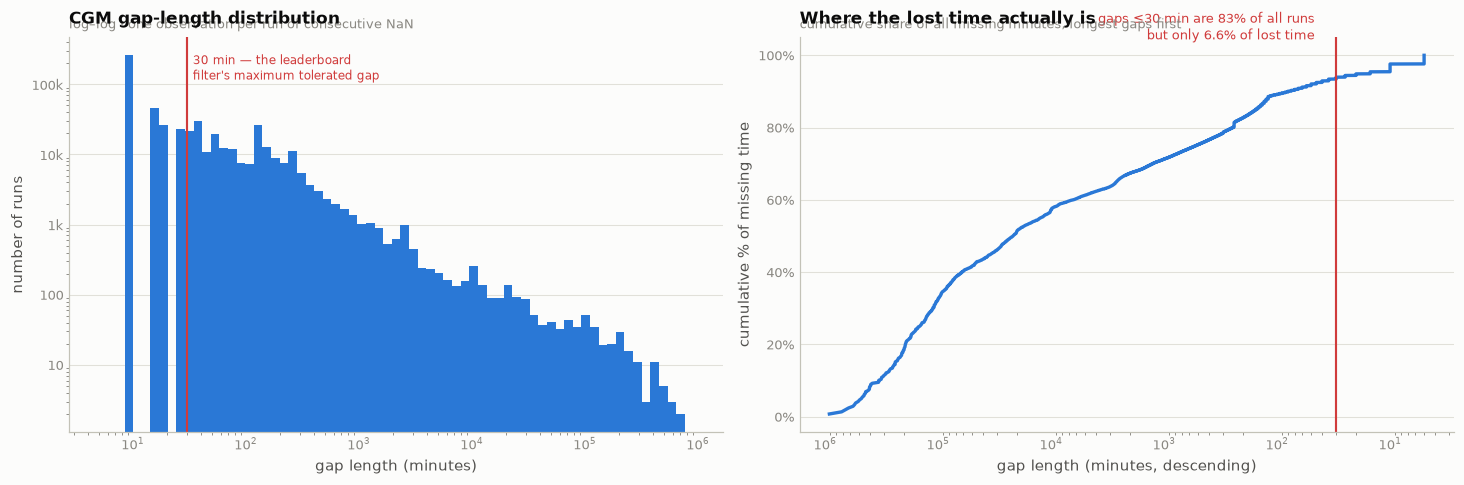

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.3))

ax = axes[0]
bins = np.logspace(np.log10(5), np.log10(gap_min.max()), 70)
ax.hist(gap_min, bins=bins, color=SERIES[0], linewidth=0)
ax.set_xscale("log"); ax.set_yscale("log")
ax.axvline(30, color=STATUS["critical"], lw=1.4)
ax.text(34, ax.get_ylim()[1]*0.25,
        "30 min — the leaderboard\nfilter's maximum tolerated gap",
        fontsize=8, color=STATUS["critical"])
ax.yaxis.set_major_formatter(KFMT)
finish(ax, "CGM gap-length distribution", "log–log · one observation per run of consecutive NaN",
       xlab="gap length (minutes)", ylab="number of runs")

ax = axes[1]
srt = np.sort(gap_min)[::-1]
cum = np.cumsum(srt)/srt.sum()*100
ax.plot(srt, cum, color=SERIES[0], lw=2.2)
ax.set_xscale("log"); ax.invert_xaxis()
ax.axvline(30, color=STATUS["critical"], lw=1.4)
share30 = gap_min[gap_min <= 30].sum()/gap_min.sum()*100
pct30   = (gap_min <= 30).mean()*100
ax.annotate(f"gaps ≤30 min are {pct30:.0f}% of all runs\nbut only {share30:.1f}% of lost time",
            (30, 100-share30), xytext=(-14, 26), textcoords="offset points",
            fontsize=8.4, color=STATUS["critical"], ha="right")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
finish(ax, "Where the lost time actually is",
       "cumulative share of all missing minutes, longest gaps first",
       xlab="gap length (minutes, descending)", ylab="cumulative % of missing time")
show()

A textbook long tail: **most gaps are short, but almost all lost time sits in a few
enormous ones** — sensor removal, hospital stays, study pauses. The two regimes want
opposite treatment:

- **Short gaps (≤ 30 min, 1–6 slots)** are dropout mid-wear. Interpolating across them
  is defensible, and the competition's filter tolerates them.
- **Long gaps (hours to weeks)** are absence of wear. Interpolating fabricates data.
  They should **split a subject into independent contiguous segments**, and no lag
  window may reach across one.

The single largest gap is over 3 years inside one subject's record. Treating that
subject as one continuous series would be nonsense.

---
## 8 · Subject-level structure

Every row-weighted statistic printed so far is biased, and the bias is large. `Loop`
contributes 61 % of rows but 44 % of subjects; a subject with 287,102 rows counts 459×
more than one with 626. Demographics are *subject-constant* — repeating `age` down
80,589 rows does not make it 80,589 observations of age.

This section builds the subject table once and reuses it everywhere after.

### 8.1 · The subject key is `(source_file, id)`, not `id`

In [56]:
n_pair = df.groupby(SUBJ_KEY, observed=True).ngroups
n_id   = df["id"].nunique()
print(f"distinct (source_file, id) pairs : {n_pair:,}")
print(f"distinct id values               : {n_id:,}")
print(f"→ {n_pair - n_id:,} ids are reused across cohorts\n")

collide = (df.groupby("id", observed=True)["source_file"].nunique()
             .pipe(lambda s: s[s > 1]).sort_values(ascending=False))
print(f"ids appearing in more than one cohort: {len(collide):,}\n")
print(collide.head(8).to_string())
ex = collide.index[0]
print(f"\nExample — id '{ex}' appears in:")
print(df.loc[df["id"] == ex].groupby("source_file", observed=True)["date"]
        .agg(["size", "min", "max"]).to_string())
print("\nGrouping on `id` alone splices unrelated people into one time series.")

distinct (source_file, id) pairs : 1,907
distinct id values               : 1,291
→ 616 ids are reused across cohorts

ids appearing in more than one cohort: 241

id
19    9
20    9
3     9
5     9
16    8
10    8
26    8
18    8

Example — id '19' appears in:
               size                 min                 max
source_file                                                
AZT1D         13248 2024-02-01 00:05:00 2024-03-18 00:00:00
CTR3          40199 2014-06-09 09:05:00 2014-10-26 22:55:00
DCLP3         54205 2018-05-14 06:15:00 2018-11-18 11:15:00
DCLP5         56661 2019-06-28 15:55:00 2020-01-11 09:35:00
Flair         59672 2018-11-07 09:15:00 2019-06-02 13:50:00
HUPA-UCM       3711 2019-07-03 14:00:00 2019-07-16 11:10:00
Loop         149490 2018-03-07 17:05:00 2019-08-08 18:30:00
PEDAP        104439 2020-08-28 06:15:00 2021-08-25 21:25:00
ReplaceBG     95160 2014-10-09 00:05:00 2015-09-04 10:00:00

Grouping on `id` alone splices unrelated people into one time series.


### 8.2 · Building the subject table

In [57]:
t0 = time.time()
g = df.groupby(SUBJ_KEY, observed=True)

subjects = g.agg(
    rows        = ("date", "size"),
    first       = ("date", "min"),
    last        = ("date", "max"),
    cgm_n       = ("CGM", "count"),
    cgm_mean    = ("CGM", "mean"),
    cgm_std     = ("CGM", "std"),
    cgm_min     = ("CGM", "min"),
    cgm_max     = ("CGM", "max"),
    insulin_sum = ("insulin", "sum"),
    basal_sum   = ("basal", "sum"),
    bolus_sum   = ("bolus", "sum"),
    carbs_sum   = ("carbs", "sum"),
    carbs_n     = ("carbs", "count"),
    age         = ("age", "median"),
    height      = ("height", "median"),
    weight      = ("weight", "median"),
    age_of_dx   = ("age_of_diagnosis", "median"),
    hr_n        = ("heartrate", "count"),
    steps_n     = ("steps", "count"),
    any_test    = ("is_test", "max"),
    all_test    = ("is_test", "min"),
    split_flag  = ("subject_split_across_traintest", "max"),
)
_mode = lambda s: s.mode().iloc[0] if len(s.dropna()) else None
for c in ["gender", "ethnicity", "insulin_delivery_modality", "cgm_device",
          "insulin_delivery_algorithm", "treatment_group", "is_pregnant"]:
    subjects[c] = g[c].agg(_mode)

subjects["days"]      = (subjects["last"] - subjects["first"]).dt.total_seconds()/86400
subjects["cgm_cov"]   = subjects.cgm_n / subjects.rows * 100
subjects["cgm_cv"]    = subjects.cgm_std / subjects.cgm_mean * 100
subjects["gmi"]       = 3.31 + 0.02392*subjects.cgm_mean       # HbA1c equivalent, %
subjects["tdd"]       = subjects.insulin_sum / subjects.days   # total daily dose, units
subjects["carbs_day"] = subjects.carbs_sum / subjects.days
subjects["bmi"]       = (subjects.weight*0.45359237) / (subjects.height*0.3048)**2
subjects["split"]     = np.where(subjects.split_flag, "both",
                        np.where(subjects.any_test, "test", "train"))
subjects = subjects.reset_index()
print(f"built in {time.time()-t0:.1f}s · {len(subjects):,} subjects × {subjects.shape[1]} attributes")
subjects.head(8)

built in 809.0s · 1,907 subjects × 39 attributes


,source_file,id,rows,first,last,cgm_n,cgm_mean,cgm_std,cgm_min,cgm_max,insulin_sum,basal_sum,bolus_sum,carbs_sum,carbs_n,age,height,weight,age_of_dx,hr_n,steps_n,any_test,all_test,split_flag,gender,ethnicity,insulin_delivery_modality,cgm_device,insulin_delivery_algorithm,treatment_group,is_pregnant,days,cgm_cov,cgm_cv,gmi,tdd,carbs_day,bmi,split
0,AZT1D,1,11231,2023-12-08 00:05:00,2024-01-15 23:55:00,10881,141.6,36.4,40,279,"4,560","1,249","5,109","7,102",534,65,NaN,NaN,NaN,0,0,False,False,False,Male,NaN,AID,Dexcom G6,Control-IQ,NaN,None,38.99,96.88,25.71,6.696,116.9,182.1,NaN,train
1,AZT1D,11,12960,2024-01-08 00:05:00,2024-02-22 00:00:00,12793,166.1,51.58,45,400,"4,902","1,134","6,453",1.998e+04,654,59,NaN,NaN,NaN,0,0,False,False,False,Male,NaN,AID,Dexcom G6,Control-IQ,NaN,None,45,98.71,31.06,7.283,108.9,444,NaN,train
2,AZT1D,12,12671,2024-01-08 00:05:00,2024-02-20 23:55:00,12524,135.3,42.21,40,306,836.5,334.8,807.5,"6,761",296,43,NaN,NaN,NaN,0,0,False,False,False,Male,NaN,AID,Dexcom G6,Control-IQ,NaN,None,43.99,98.84,31.18,6.548,19.02,153.7,NaN,train
3,AZT1D,13,12959,2024-01-13 00:05:00,2024-02-26 23:55:00,12781,134.6,28.65,40,244,469.2,165.4,496.1,"4,269",265,80,NaN,NaN,NaN,0,0,False,False,False,Male,NaN,AID,Dexcom G6,Control-IQ,NaN,None,44.99,98.63,21.29,6.529,10.43,94.88,NaN,train
4,AZT1D,14,12960,2024-01-13 00:05:00,2024-02-27 00:00:00,12795,107.4,27.21,40,237,"1,484",267.3,"2,281","6,185",434,32,NaN,NaN,NaN,0,0,False,False,False,Female,NaN,AID,Dexcom G6,Control-IQ,NaN,None,45,98.73,25.35,5.878,32.99,137.5,NaN,train
5,AZT1D,15,14112,2024-01-12 00:05:00,2024-03-01 00:00:00,13772,137,53.09,40,400,801.7,423.2,697.1,"1,939",393,52,NaN,NaN,NaN,0,0,False,False,False,Female,NaN,AID,Dexcom G6,Control-IQ,NaN,None,49,97.59,38.75,6.587,16.36,39.57,NaN,train
6,AZT1D,16,12384,2024-01-18 00:05:00,2024-03-01 00:00:00,12237,148.8,46.18,40,342,"1,612","1,084",867.7,"3,416",293,40,NaN,NaN,NaN,0,0,True,True,False,Male,NaN,AID,Dexcom G6,Control-IQ,NaN,None,43,98.81,31.03,6.87,37.5,79.45,NaN,test
7,AZT1D,17,12672,2024-01-10 00:05:00,2024-02-23 00:00:00,12508,154.2,52.03,40,400,"1,307",770.7,873.5,"2,873",428,66,NaN,NaN,NaN,0,0,False,False,False,Female,NaN,AID,Dexcom G6,Control-IQ,NaN,None,44,98.71,33.75,6.997,29.7,65.3,NaN,train


In [58]:
def pull_subjects(keys):
    """Every row for a list of (source_file, id) keys, in order. Cheap: two hash
    filters over the big frame, then an exact filter on the small result."""
    srcs = {k[0] for k in keys}; ids = {k[1] for k in keys}
    sub = df[df["source_file"].isin(srcs) & df["id"].isin(ids)]
    want = set(keys)
    keep = np.fromiter(((s, i) in want for s, i in zip(sub["source_file"], sub["id"])),
                       bool, len(sub))
    return sub[keep].sort_values(SUBJ_KEY + ["date"])

SAMPLE_KEYS = list(map(tuple, subjects.sample(CFG["n_subj_sample"],
                                              random_state=CFG["seed"])[SUBJ_KEY].values))
t0 = time.time()
SS = pull_subjects(SAMPLE_KEYS).reset_index(drop=True)
_s, _i = pd.factorize(SS["source_file"])[0], pd.factorize(SS["id"])[0]
_gap   = (SS["date"].diff().dt.total_seconds().to_numpy() != CFG["grid_min"]*60)
SS_BND = np.concatenate(([False], (_s[1:] == _s[:-1]) & (_i[1:] == _i[:-1]))) & ~_gap
SS_BLK = np.cumsum(~SS_BND)
print(f"pulled {len(SAMPLE_KEYS)} subjects / {len(SS):,} rows "
      f"/ {SS_BLK.max():,} contiguous blocks in {time.time()-t0:.1f}s")

pulled 120 subjects / 10,226,600 rows / 120 contiguous blocks in 282.4s


### 8.3 · How much data does a subject actually contribute?

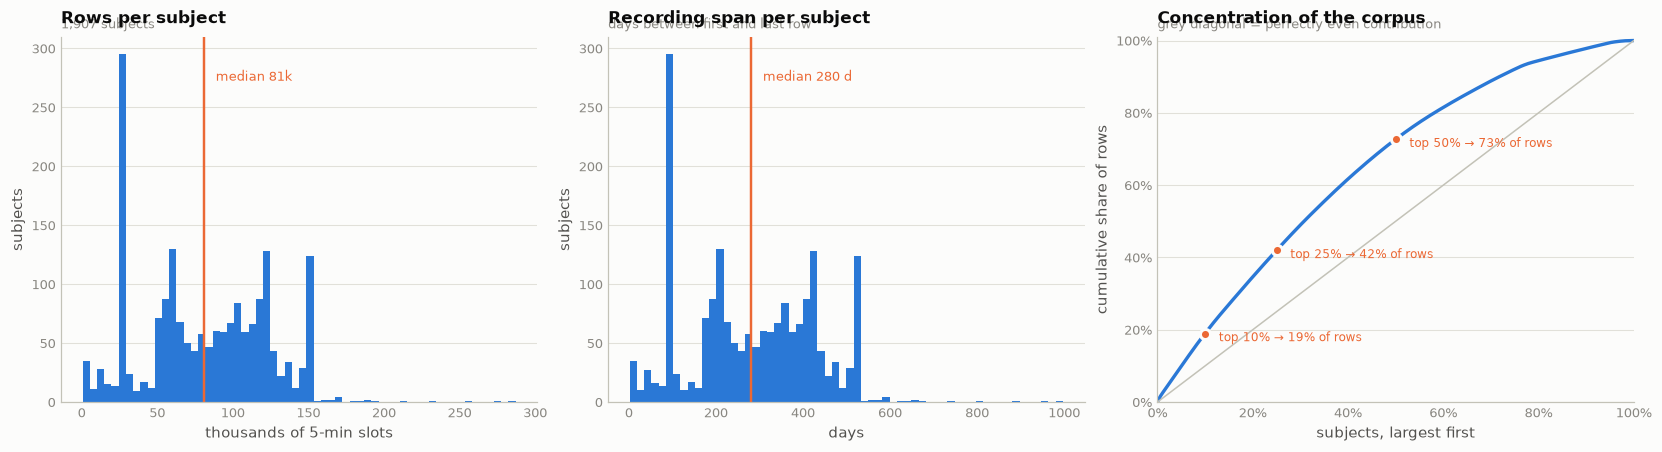

,rows,days,cgm_cov,cgm_mean
count,"1,907","1,907","1,907","1,907"
mean,8.12e+04,282,85.1,153.1
std,4.313e+04,149.7,16.3,22.4
min,626,2.2,0.7,86.3
1%,"3,766",13.1,28.6,102.4
25%,5.105e+04,177.2,80.7,138.7
50%,8.059e+04,279.8,91.7,152.8
75%,1.166e+05,404.7,95.9,166.4
99%,1.532e+05,532,100,213.8
max,2.871e+05,996.9,100,379.2


In [59]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.0))

ax = axes[0]
ax.hist(subjects.rows/1000, bins=60, color=SERIES[0], linewidth=0)
ax.axvline(subjects.rows.median()/1000, color=SERIES[1], lw=1.6)
ax.annotate(f"median {subjects.rows.median()/1000:,.0f}k",
            (subjects.rows.median()/1000, ax.get_ylim()[1]*0.88), xytext=(8, 0),
            textcoords="offset points", fontsize=8.4, color=SERIES[1])
finish(ax, "Rows per subject", f"{len(subjects):,} subjects",
       xlab="thousands of 5-min slots", ylab="subjects")

ax = axes[1]
ax.hist(subjects.days, bins=60, color=SERIES[0], linewidth=0)
ax.axvline(subjects.days.median(), color=SERIES[1], lw=1.6)
ax.annotate(f"median {subjects.days.median():,.0f} d",
            (subjects.days.median(), ax.get_ylim()[1]*0.88), xytext=(8, 0),
            textcoords="offset points", fontsize=8.4, color=SERIES[1])
finish(ax, "Recording span per subject", "days between first and last row",
       xlab="days", ylab="subjects")

ax = axes[2]
s = subjects.sort_values("rows", ascending=False)
cum = (s.rows.cumsum()/s.rows.sum()*100).to_numpy()
ax.plot(np.arange(1, len(cum)+1)/len(cum)*100, cum, color=SERIES[0], lw=2.2)
ax.plot([0, 100], [0, 100], color=AXIS, lw=1.0)
for q in (10, 25, 50):
    k = int(len(s)*q/100)
    ax.scatter([q], [cum[k-1]], s=44, color=SERIES[1], zorder=4,
               edgecolor=SURFACE, linewidth=2)
    ax.annotate(f"top {q}% → {cum[k-1]:.0f}% of rows", (q, cum[k-1]), xytext=(9, -5),
                textcoords="offset points", fontsize=8, color=SERIES[1])
ax.set_xlim(0, 100); ax.set_ylim(0, 101)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
finish(ax, "Concentration of the corpus", "grey diagonal = perfectly even contribution",
       xlab="subjects, largest first", ylab="cumulative share of rows")
show()

subjects[["rows", "days", "cgm_cov", "cgm_mean"]].describe(
    percentiles=[.01, .25, .5, .75, .99]).round(1)

### 8.4 · Row-weighted demographics are the wrong answer

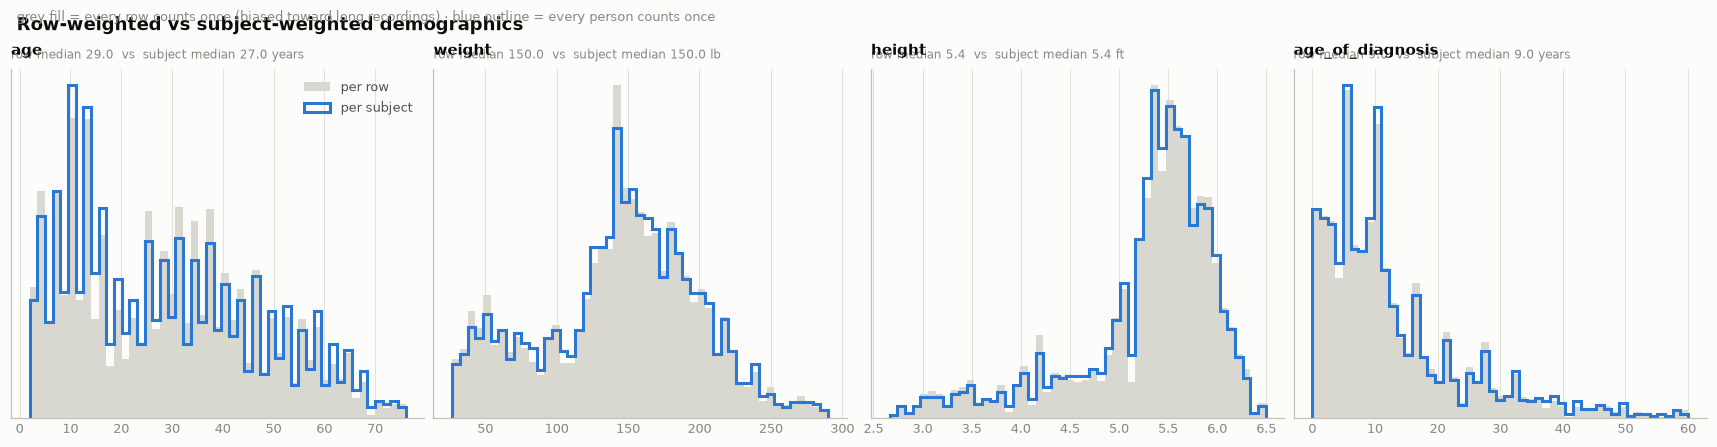

In [60]:
fig, axes = plt.subplots(1, 4, figsize=(15.5, 3.9))
pairs = [("age", "age", "years"), ("weight", "weight", "lb"),
         ("height", "height", "ft"), ("age_of_diagnosis", "age_of_dx", "years")]
for ax, (rowcol, subcol, unit) in zip(axes, pairs):
    rv = df[rowcol].dropna()
    rv = rv.sample(min(len(rv), 6_000_000), random_state=CFG["seed"]).to_numpy()
    sv = subjects[subcol].dropna().to_numpy()
    lo, hi = np.nanpercentile(np.concatenate([rv, sv]), [0.2, 99.8])
    bins = np.linspace(lo, hi, 50)
    ax.hist(rv, bins=bins, density=True, color=FADE, linewidth=0, label="per row")
    ax.hist(sv, bins=bins, density=True, histtype="step", color=SERIES[0], lw=2.0,
            label="per subject")
    ax.set_title(rowcol, loc="left", fontsize=9.5)
    ax.text(0, 1.02, f"row median {np.median(rv):,.1f}  vs  "
                     f"subject median {np.median(sv):,.1f} {unit}",
            transform=ax.transAxes, fontsize=7.6, color=MUTED, va="bottom")
    ax.set_yticks([])
axes[0].legend(loc="upper right")
fig.suptitle("Row-weighted vs subject-weighted demographics",
             x=0.006, ha="left", fontsize=12, color=INK, weight="600")
fig.text(0.006, 0.978, "grey fill = every row counts once (biased toward long recordings) · "
                       "blue outline = every person counts once", fontsize=8.5, color=MUTED)
show()

In [61]:
cohort = (subjects.groupby("source_file")
          .agg(subjects=("id", "size"), Mrows=("rows", lambda s: s.sum()/1e6),
               med_days=("days", "median"), med_age=("age", "median"),
               pct_female=("gender", lambda s: (s == "Female").mean()*100),
               med_cgm=("cgm_mean", "median"), med_cgm_cov=("cgm_cov", "median"),
               med_cv=("cgm_cv", "median"), med_tdd=("tdd", "median"),
               pct_test=("any_test", lambda s: s.mean()*100),
               pct_split=("split_flag", lambda s: s.mean()*100))
          .sort_values("Mrows", ascending=False).round(1))
cohort["k_rows_per_subject"] = (cohort.Mrows*1000/cohort.subjects).round(0)
cohort

,subjects,Mrows,med_days,med_age,pct_female,med_cgm,med_cgm_cov,med_cv,med_tdd,pct_test,pct_split,k_rows_per_subject
source_file,,,,,,,,,,,,
Loop,845,94.8,402.2,27,51.6,141.9,93.6,36.3,33.5,18.9,9,112
ReplaceBG,208,20.9,322.3,43,50.5,161,71.4,37.2,39.5,18.3,8.7,100
IOBP2,332,9.7,94,30.5,0,160,90.9,35.1,48.3,18.7,8.7,29
Flair,113,7,216.1,19,0,162.9,82.7,37.1,54.9,18.6,8.8,62
DCLP5,100,6.1,202.9,11,49,162.2,95.8,37.8,36.8,19,9,61
DCLP3,112,6,184.8,28.5,48.2,154.6,95.7,33.2,49.9,18.8,8.9,54
PEDAP,65,5.5,309.5,4,47.7,149.7,94.7,37.9,10.1,16.9,7.7,85
CTR3,30,2.2,255.6,44,43.3,151.5,63,37.1,20.8,16.7,6.7,73
BrisT1D,19,1.1,209.4,22,73.7,152.6,82.3,36.3,41.6,10.5,5.3,58


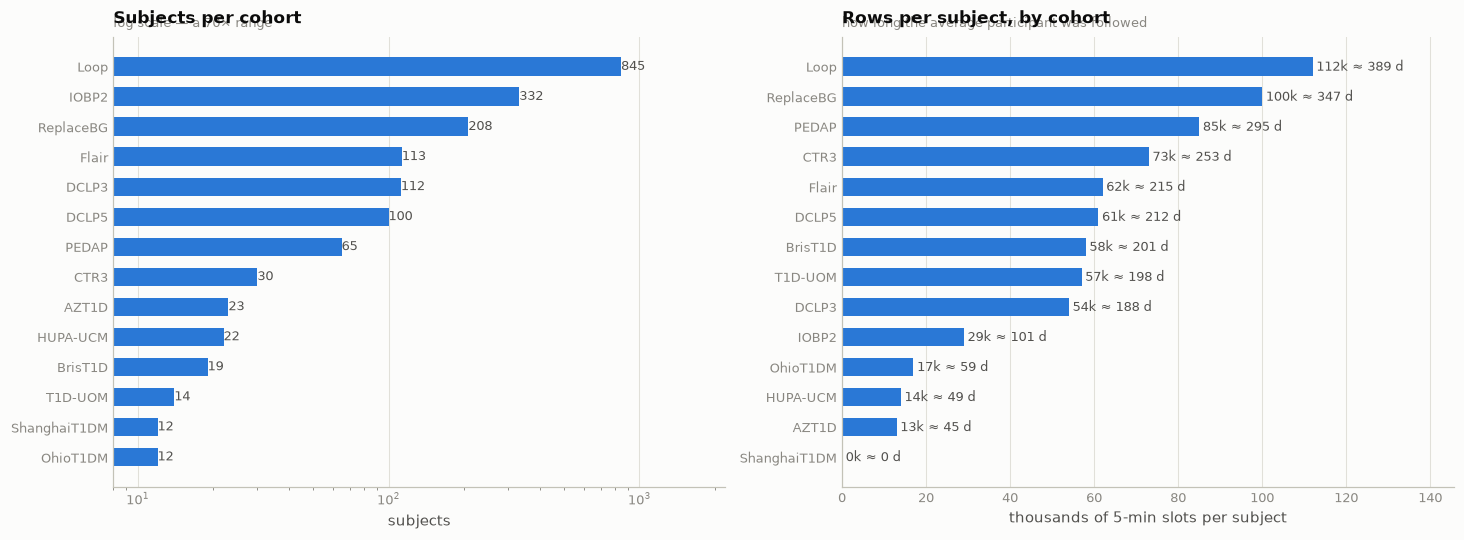

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.8))
c = cohort.sort_values("subjects")
ax = axes[0]
b = ax.barh(c.index, c.subjects, height=0.62, color=SERIES[0], linewidth=0)
ax.set_xscale("log"); ax.set_xlim(8, c.subjects.max()*2.6)
barh_labels(ax, b, [f"{v:,}" for v in c.subjects], pad=0.0)
finish(ax, "Subjects per cohort", "log scale — a 70× range", xlab="subjects",
       xgrid=True, ygrid=False)

ax = axes[1]
c2 = cohort.sort_values("k_rows_per_subject")
b = ax.barh(c2.index, c2.k_rows_per_subject, height=0.62, color=SERIES[0], linewidth=0)
ax.set_xlim(0, c2.k_rows_per_subject.max()*1.3)
barh_labels(ax, b, [f"{v:,.0f}k ≈ {v*1000*CFG['grid_min']/1440:,.0f} d"
                    for v in c2.k_rows_per_subject])
finish(ax, "Rows per subject, by cohort", "how long the average participant was followed",
       xlab="thousands of 5-min slots per subject", xgrid=True, ygrid=False)
show()

### 8.5 · Which columns are genuinely subject-constant?

In [63]:
t0 = time.time()
nu = df.groupby(SUBJ_KEY, observed=True)[
        [c for c in df.columns if c not in ("date",) + tuple(SUBJ_KEY)]].nunique()
const = pd.DataFrame({
    "max_values_per_subject":  nu.max(),
    "mean_values_per_subject": nu.mean().round(3),
    "subjects_with_one_value": (nu <= 1).sum(),
    "pct_constant":            ((nu <= 1).mean()*100).round(1),
}).sort_values("pct_constant", ascending=False)
print(f"computed in {time.time()-t0:.1f}s")
const

computed in 7346.3s


,max_values_per_subject,mean_values_per_subject,subjects_with_one_value,pct_constant
age,1,0.994,1907,100
ethnicity,1,0.92,1907,100
extension_date,1,0.156,1907,100
randomization_date,1,0.379,1907,100
treatment_group,1,0.484,1907,100
gender,1,0.735,1907,100
is_pregnant,1,0.712,1907,100
age_of_diagnosis,1,0.937,1907,100
subject_split_across_traintest,2,1.001,1905,99.9
cgm_device,2,0.952,1905,99.9


Columns at 100 % constant are **static covariates**: store them once per subject and
join, instead of carrying 154 million copies. Columns in between —`cgm_device`,
`insulin_delivery_device`, `insulin_delivery_algorithm` — are *era* variables, meaning
a participant changed hardware mid-study. Those switches are genuine regime changes in
the data-generating process and deserve an explicit "days since device change"
feature rather than being flattened into a single mode.

---
## 9 · The target: CGM

130.9 M non-null readings. Everything here serves one question — **what does a model
have to beat?** Section 9.6 answers it outright, measuring the persistence baseline at
all four competition horizons on the competition's own metric, over the whole corpus.

### 9.1 · Marginal distribution and clinical bands

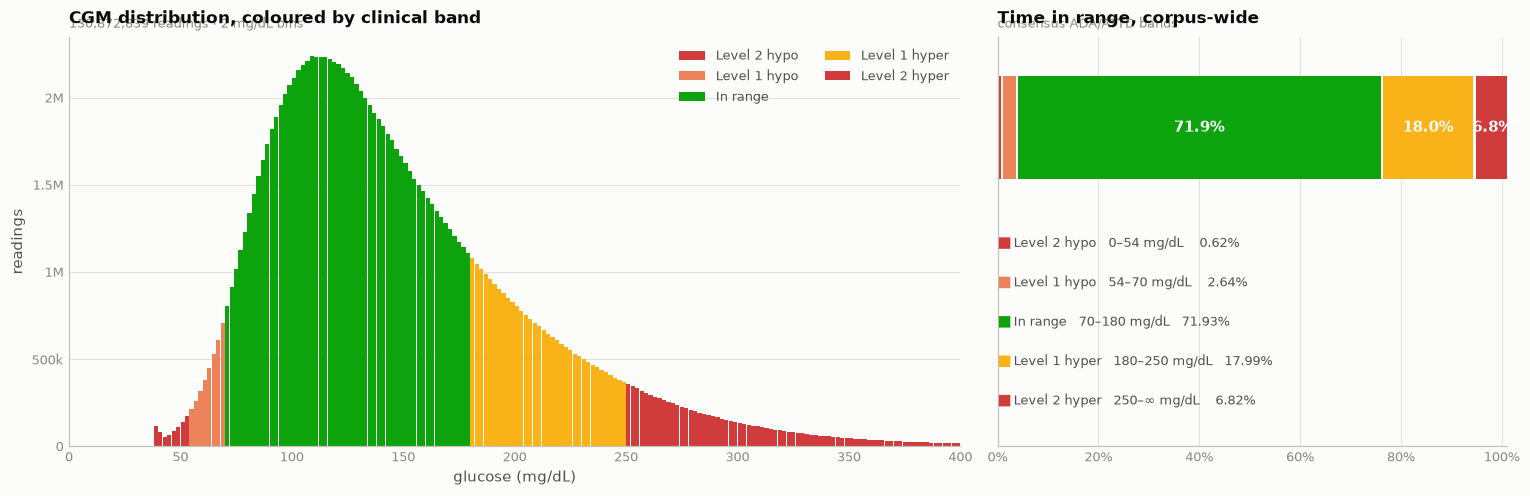

mean 148.2   median 135.0   sd 59.7   CV 40.3%
GMI (estimated HbA1c) = 3.31 + 0.02392 × 148.2 = 6.85%
time in range 70–180  = 72.33%   (clinical target is >70%)


In [64]:
CGM = df["CGM"].to_numpy()
cgm_v = CGM[HAS_CGM]

fig, axes = plt.subplots(1, 2, figsize=(13.8, 4.4), width_ratios=[1.75, 1])

ax = axes[0]
cnt, edges = np.histogram(cgm_v, bins=np.arange(0, 405, 2))
centres = (edges[:-1] + edges[1:]) / 2
for name, lo, hi, col in CGM_BANDS:
    m = (centres >= lo) & (centres < hi)
    ax.bar(centres[m], cnt[m], width=1.9, color=col, linewidth=0, label=name)
ax.set_xlim(0, 400); ax.yaxis.set_major_formatter(KFMT)
ax.legend(loc="upper right", ncols=2)
finish(ax, "CGM distribution, coloured by clinical band",
       f"{len(cgm_v):,} readings · 2 mg/dL bins",
       xlab="glucose (mg/dL)", ylab="readings")

ax = axes[1]
shares = [((cgm_v >= lo) & (cgm_v < hi)).mean()*100 for _, lo, hi, _ in CGM_BANDS]
left = 0.0
for (name, lo, hi, col), s in zip(CGM_BANDS, shares):
    ax.barh([1.0], [s], left=left, height=0.34, color=col, linewidth=0)
    if s > 4:
        ax.text(left + s/2, 1.0, f"{s:.1f}%", ha="center", va="center",
                fontsize=9.5, color="#ffffff", weight="600")
    left += s + 0.4                      # surface gap between stacked segments
for i, ((name, lo, hi, col), s) in enumerate(zip(CGM_BANDS, shares)):
    ax.text(0, 0.62 - i*0.13, "■", color=col, fontsize=10, va="center")
    ax.text(3.2, 0.62 - i*0.13,
            f"{name}   {lo}–{hi if hi < 999 else '∞'} mg/dL   {s:>5.2f}%",
            color=INK2, fontsize=8.6, va="center")
ax.set_xlim(0, 101); ax.set_ylim(-0.05, 1.3); ax.set_yticks([])
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
finish(ax, "Time in range, corpus-wide", "consensus ADA/ATTD bands",
       xgrid=True, ygrid=False)
show()

print(f"mean {cgm_v.mean():.1f}   median {np.median(cgm_v):.1f}   "
      f"sd {cgm_v.std():.1f}   CV {cgm_v.std()/cgm_v.mean()*100:.1f}%")
print(f"GMI (estimated HbA1c) = 3.31 + 0.02392 × {cgm_v.mean():.1f} = "
      f"{3.31 + 0.02392*cgm_v.mean():.2f}%")
print(f"time in range 70–180  = {((cgm_v>=70)&(cgm_v<=180)).mean()*100:.2f}%   "
      f"(clinical target is >70%)")

### 9.2 · Device clipping — the target is censored

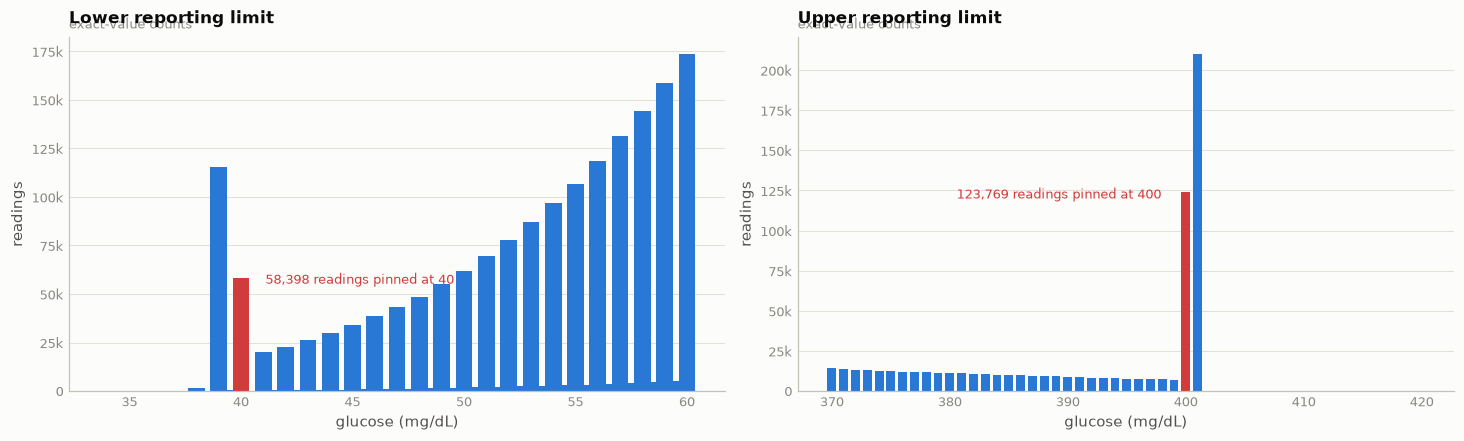

exactly  40 mg/dL        58,398  (0.0446%)
exactly 400 mg/dL       121,909  (0.0932%)
below 40                117,707  (0.0899%)
above 400               211,234  (0.1614%)
absolute range             1.80 – 500.90 mg/dL


In [65]:
fig, axes = plt.subplots(1, 2, figsize=(13.2, 3.9))
for ax, (lo, hi, edge, lbl) in zip(axes, [(30, 60, 40, "lower"), (370, 420, 400, "upper")]):
    m = (cgm_v >= lo) & (cgm_v <= hi)
    vals, counts = np.unique(np.round(cgm_v[m], 3), return_counts=True)
    at = np.isclose(vals, edge)
    ax.bar(vals, counts, width=0.75,
           color=[STATUS["critical"] if a else SERIES[0] for a in at], linewidth=0)
    ax.yaxis.set_major_formatter(KFMT)
    n_at = int(counts[at].sum()) if at.any() else 0
    ax.annotate(f"{n_at:,} readings pinned at {edge}", (edge, n_at),
                xytext=(16 if lo < 100 else -16, -4), textcoords="offset points",
                fontsize=8.5, color=STATUS["critical"], ha="left" if lo < 100 else "right")
    finish(ax, f"{lbl.capitalize()} reporting limit", "exact-value counts",
           xlab="glucose (mg/dL)", ylab="readings")
show()

for lbl, v in [("exactly  40 mg/dL", (cgm_v == 40)), ("exactly 400 mg/dL", (cgm_v == 400)),
               ("below 40",          (cgm_v < 40)),   ("above 400",         (cgm_v > 400))]:
    print(f"{lbl:<20s} {int(v.sum()):>10,}  ({v.mean()*100:.4f}%)")
print(f"{'absolute range':<20s} {cgm_v.min():>10.2f} – {cgm_v.max():.2f} mg/dL")

Dexcom and Medtronic sensors report `LOW` below 40 mg/dL and `HIGH` above 400, and
several cohorts encode those as the literal boundary value — while others pass the raw
value straight through, which is why 117,707 readings sit *below* 40 and 211,234
*above* 400. The target is **interval-censored at both ends, inconsistently across
cohorts**.

Two consequences worth carrying forward:

- The spikes at 40 and 400 are not real modes. A squared-error loss will chase them.
- MARD divides by the true value, so a 20 mg/dL error at a clamped low of 40 costs
  **ten times** what the same absolute error costs at 400. The hypoglycaemic tail
  dominates the metric even though it is only ~4 % of readings.

### 9.3 · Per-subject glycaemic control

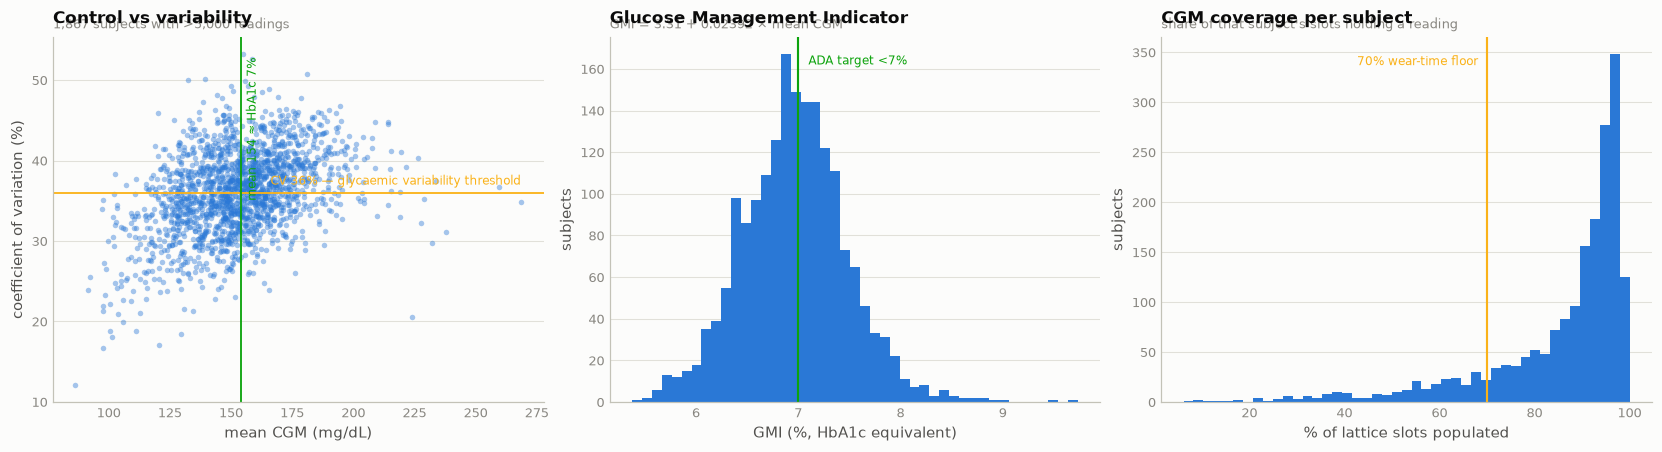

below the 70% wear-time floor : 267 of 1,867 (14.3%)
meeting GMI <7%               : 995 (53.3%)
with CV >36%                  : 969 (51.9%)


In [66]:
s = subjects[subjects.cgm_n > 5000]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.0))

ax = axes[0]
ax.scatter(s.cgm_mean, s.cgm_cv, s=13, color=SERIES[0], alpha=0.42, linewidth=0)
ax.axhline(36, color=STATUS["warning"], lw=1.2)
ax.text(s.cgm_mean.max(), 37, "CV 36% — glycaemic variability threshold",
        fontsize=7.8, color=STATUS["warning"], ha="right")
ax.axvline(154, color=STATUS["good"], lw=1.2)
ax.text(156, s.cgm_cv.max()*0.99, "mean 154 ≈ HbA1c 7%", fontsize=7.8,
        color=STATUS["good"], rotation=90, va="top")
finish(ax, "Control vs variability", f"{len(s):,} subjects with >5,000 readings",
       xlab="mean CGM (mg/dL)", ylab="coefficient of variation (%)")

ax = axes[1]
ax.hist(s.gmi, bins=45, color=SERIES[0], linewidth=0)
ax.axvline(7.0, color=STATUS["good"], lw=1.4)
ax.text(7.06, ax.get_ylim()[1]*0.95, " ADA target <7%", fontsize=8,
        color=STATUS["good"], va="top")
finish(ax, "Glucose Management Indicator", "GMI = 3.31 + 0.02392 × mean CGM",
       xlab="GMI (%, HbA1c equivalent)", ylab="subjects")

ax = axes[2]
ax.hist(s.cgm_cov, bins=45, color=SERIES[0], linewidth=0)
ax.axvline(70, color=STATUS["warning"], lw=1.4)
ax.text(69, ax.get_ylim()[1]*0.95, "70% wear-time floor ", fontsize=8,
        color=STATUS["warning"], ha="right", va="top")
finish(ax, "CGM coverage per subject", "share of that subject's slots holding a reading",
       xlab="% of lattice slots populated", ylab="subjects")
show()

print(f"below the 70% wear-time floor : {(s.cgm_cov < 70).sum():,} of {len(s):,} "
      f"({(s.cgm_cov<70).mean()*100:.1f}%)")
print(f"meeting GMI <7%               : {(s.gmi < 7).sum():,} ({(s.gmi<7).mean()*100:.1f}%)")
print(f"with CV >36%                  : {(s.cgm_cv > 36).sum():,} ({(s.cgm_cv>36).mean()*100:.1f}%)")

### 9.4 · The diurnal profile

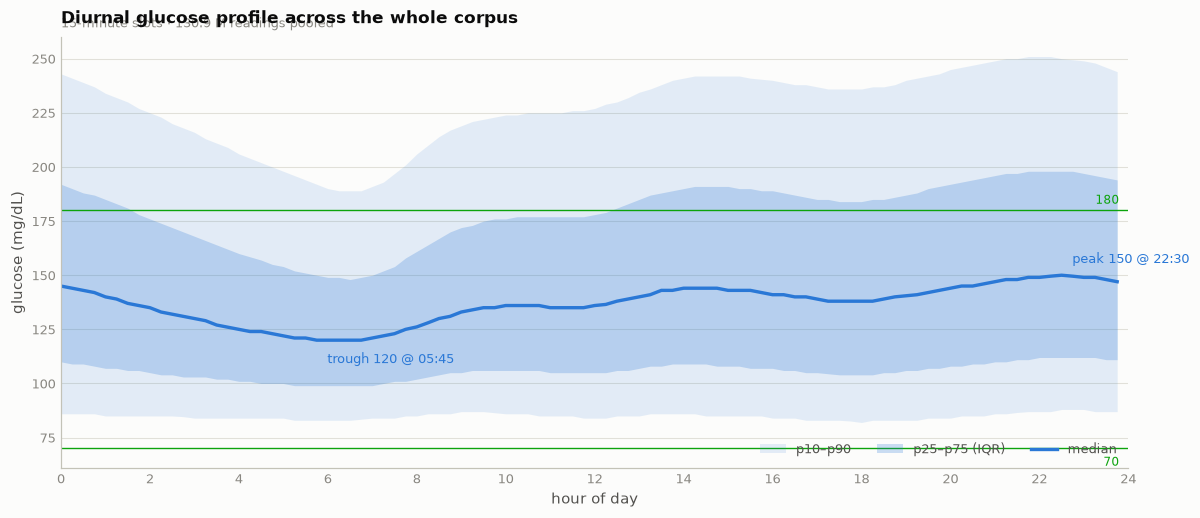

median swing across the day: 30.0 mg/dL


In [67]:
tmp = pd.DataFrame({"slot": MINOFDAY // 15, "CGM": CGM})
tmp = tmp[HAS_CGM]
prof24 = tmp.groupby("slot")["CGM"].agg(
    p10=lambda x: x.quantile(.10), p25=lambda x: x.quantile(.25), med="median",
    p75=lambda x: x.quantile(.75), p90=lambda x: x.quantile(.90), mean="mean")
del tmp; gc.collect()
hrs = prof24.index.to_numpy()/4

fig, ax = plt.subplots(figsize=(10.8, 4.6))
ax.fill_between(hrs, prof24.p10, prof24.p90, color=SERIES[0], alpha=0.12, linewidth=0,
                label="p10–p90")
ax.fill_between(hrs, prof24.p25, prof24.p75, color=SERIES[0], alpha=0.24, linewidth=0,
                label="p25–p75 (IQR)")
ax.plot(hrs, prof24.med, color=SERIES[0], lw=2.2, label="median")
ax.axhline(180, color=STATUS["good"], lw=0.9); ax.axhline(70, color=STATUS["good"], lw=0.9)
ax.text(23.8, 183, "180", fontsize=7.6, color=STATUS["good"], ha="right")
ax.text(23.8, 62,  "70",  fontsize=7.6, color=STATUS["good"], ha="right")
peak, trough = prof24.med.idxmax()/4, prof24.med.idxmin()/4
ax.annotate(f"peak {prof24.med.max():.0f} @ {int(peak):02d}:{int(peak%1*60):02d}",
            (peak, prof24.med.max()), xytext=(7, 8), textcoords="offset points",
            fontsize=8.4, color=SERIES[0])
ax.annotate(f"trough {prof24.med.min():.0f} @ {int(trough):02d}:{int(trough%1*60):02d}",
            (trough, prof24.med.min()), xytext=(7, -15), textcoords="offset points",
            fontsize=8.4, color=SERIES[0])
ax.set_xticks(range(0, 25, 2)); ax.set_xlim(0, 24)
ax.legend(loc="lower right", ncols=3)
finish(ax, "Diurnal glucose profile across the whole corpus",
       "15-minute slots · 130.9 M readings pooled",
       xlab="hour of day", ylab="glucose (mg/dL)")
show()
print(f"median swing across the day: {prof24.med.max()-prof24.med.min():.1f} mg/dL")

The overnight trough, the dawn rise, and the post-prandial humps are all visible, with
an amplitude on the order of 15–25 mg/dL. That is comparable to a 30-minute prediction
error, so **time-of-day is a load-bearing feature**, not decoration. Encode it
cyclically (`sin`/`cos` of minute-of-day) so 23:55 sits next to 00:00.

findfont: Failed to find font weight 600, now using 700.


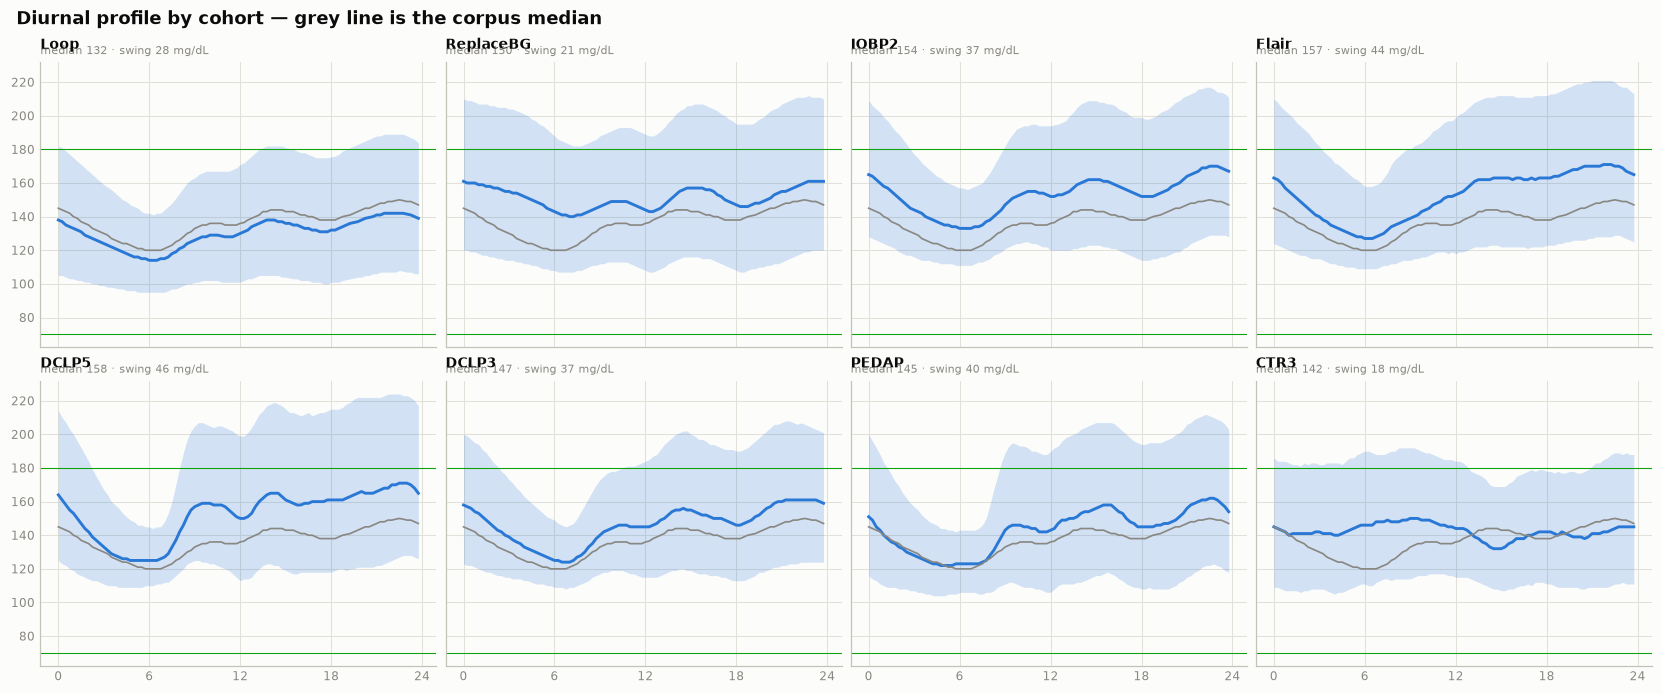

In [68]:
# Does the shape differ by cohort? Facet -- 14 cohorts is far past 8 safe hues.
big = cohort.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharex=True, sharey=True)
for ax, c in zip(axes.ravel(), big):
    m = (df["source_file"] == c).to_numpy() & HAS_CGM
    t = pd.DataFrame({"slot": MINOFDAY[m]//15, "CGM": CGM[m]})
    pr = t.groupby("slot")["CGM"].agg(p25=lambda x: x.quantile(.25), med="median",
                                      p75=lambda x: x.quantile(.75))
    h = pr.index.to_numpy()/4
    ax.fill_between(h, pr.p25, pr.p75, color=SERIES[0], alpha=0.20, linewidth=0)
    ax.plot(h, pr.med, color=SERIES[0], lw=1.9)
    ax.plot(hrs, prof24.med, color=MUTED, lw=1.1)      # corpus median for reference
    ax.axhline(180, color=STATUS["good"], lw=0.7); ax.axhline(70, color=STATUS["good"], lw=0.7)
    ax.set_title(c, loc="left", fontsize=9.4)
    ax.text(0, 1.02, f"median {pr.med.median():.0f} · swing {pr.med.max()-pr.med.min():.0f} mg/dL",
            transform=ax.transAxes, fontsize=7.4, color=MUTED, va="bottom")
    ax.set_xticks(range(0, 25, 6)); ax.tick_params(labelsize=7.6)
fig.suptitle("Diurnal profile by cohort — grey line is the corpus median",
             x=0.006, ha="left", fontsize=12, color=INK, weight="600")
show()

### 9.5 · Dynamics: how fast does glucose move?

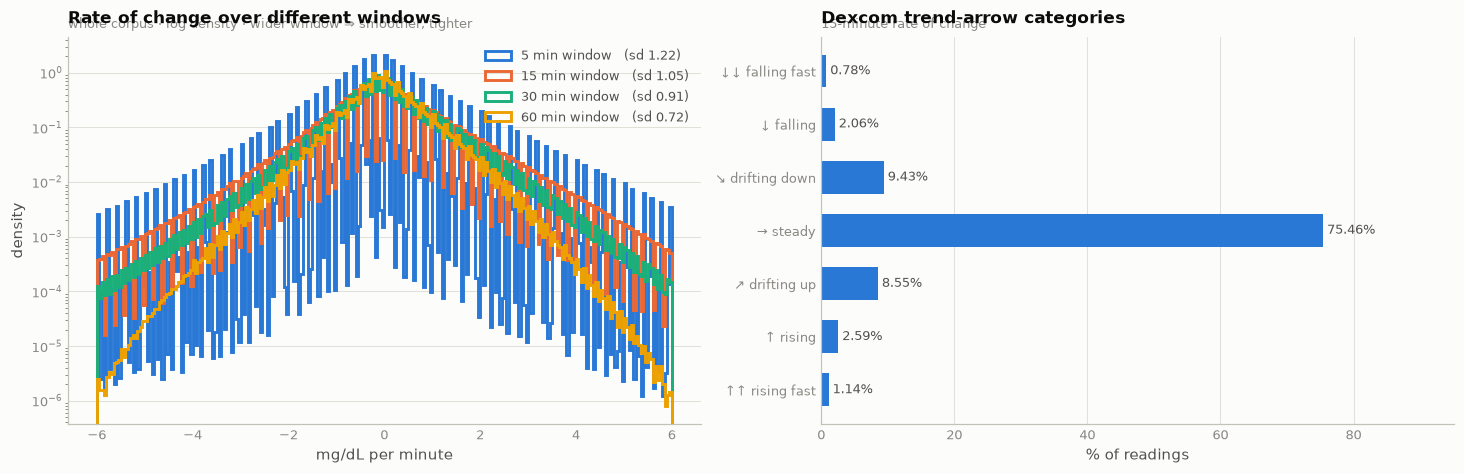

47440

In [69]:
roc = {}
for k, label in [(1, "5 min"), (3, "15 min"), (6, "30 min"), (12, "60 min")]:
    roc[label] = (CGM - lag(CGM, k)) / (k*CFG["grid_min"])     # mg/dL per minute
roc = pd.DataFrame(roc)

fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.2))
ax = axes[0]
for i, c in enumerate(roc.columns):
    v = roc[c].dropna().to_numpy()
    ax.hist(v, bins=np.linspace(-6, 6, 241), density=True, histtype="step",
            lw=1.9, color=SERIES[i], label=f"{c} window   (sd {v.std():.2f})")
ax.set_yscale("log")
ax.legend(loc="upper right")
finish(ax, "Rate of change over different windows",
       "whole corpus · log density · wider window ⇒ smoother, tighter",
       xlab="mg/dL per minute", ylab="density")

ax = axes[1]
v = roc["15 min"].dropna().to_numpy()
th = [(-np.inf, -3, "↓↓ falling fast"), (-3, -2, "↓ falling"), (-2, -1, "↘ drifting down"),
      (-1, 1, "→ steady"), (1, 2, "↗ drifting up"), (2, 3, "↑ rising"),
      (3, np.inf, "↑↑ rising fast")]
sh = [float(((v > lo) & (v <= hi)).mean()*100) for lo, hi, _ in th]
names = [n for _, _, n in th]
bars = ax.barh(names[::-1], sh[::-1], height=0.62, color=SERIES[0], linewidth=0)
ax.set_xlim(0, max(sh)*1.26)
barh_labels(ax, bars, [f"{x:.2f}%" for x in sh[::-1]])
finish(ax, "Dexcom trend-arrow categories", "15-minute rate of change",
       xlab="% of readings", xgrid=True, ygrid=False)
show()
del roc; gc.collect()

### 9.6 · The persistence baseline — what a model must beat

In [70]:
def mard(y_true, y_pred):
    m = np.isfinite(y_true) & np.isfinite(y_pred) & (y_true > 0)
    return float(np.mean(np.abs(y_pred[m] - y_true[m]) / y_true[m])*100), int(m.sum())

GLOBAL_MEAN = float(np.nanmean(CGM))
trend15 = (CGM - lag(CGM, 3)) / 15.0            # mg/dL per minute over the last 15 min

rows = []
for h in CFG["horizons"]:
    k = h // CFG["grid_min"]
    fut = lead(CGM, k)
    m_p, n = mard(fut, CGM)                                      # persistence
    m_l, _ = mard(fut, CGM + trend15*h)                          # linear extrapolation
    m_g, _ = mard(fut, np.full_like(CGM, GLOBAL_MEAN))           # global mean
    ok = np.isfinite(fut) & np.isfinite(CGM)
    err = fut[ok] - CGM[ok]
    rows.append(dict(horizon_min=h, n_pairs=n,
                     MARD_persistence=round(m_p, 3),
                     MARD_linear_extrap=round(m_l, 3),
                     MARD_global_mean=round(m_g, 3),
                     RMSE_persistence=round(float(np.sqrt(np.mean(err**2))), 2),
                     MAE_persistence=round(float(np.mean(np.abs(err))), 2),
                     corr=round(float(np.corrcoef(CGM[ok], fut[ok])[0, 1]), 4)))
    del fut, ok, err; gc.collect()
base = pd.DataFrame(rows).set_index("horizon_min")
del trend15; gc.collect()
base

,n_pairs,MARD_persistence,MARD_linear_extrap,MARD_global_mean,RMSE_persistence,MAE_persistence,corr
horizon_min,,,,,,,
30,128714107,14.03,16.56,35.73,27.25,19.16,0.8952
60,127893897,22.71,35.07,35.73,43.12,30.96,0.7368
90,127279950,28.41,53.7,35.73,53.16,38.66,0.5994
120,126733725,32.32,71.63,35.73,59.9,43.93,0.4911


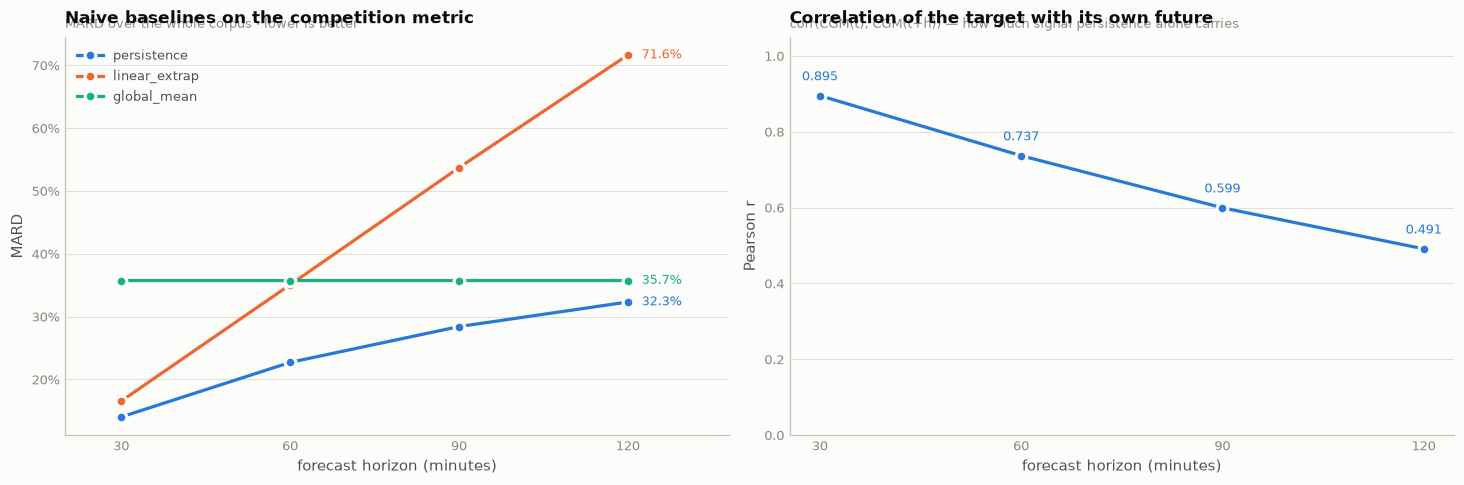

The floor. Persistence uses no features at all, so any model scoring worse
than this is actively harmful:

     30 min → MARD  14.03%   RMSE  27.25 mg/dL   r = 0.895
     60 min → MARD  22.71%   RMSE  43.12 mg/dL   r = 0.737
     90 min → MARD  28.41%   RMSE  53.16 mg/dL   r = 0.599
    120 min → MARD  32.32%   RMSE  59.90 mg/dL   r = 0.491

Note that linear extrapolation is WORSE than persistence at every horizon —
glucose trends mean-revert, so projecting the current slope overshoots.


In [71]:
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.3))
x = np.array(CFG["horizons"])

ax = axes[0]
for i, c in enumerate(["MARD_persistence", "MARD_linear_extrap", "MARD_global_mean"]):
    ax.plot(x, base[c], color=SERIES3[i], lw=2.1, marker="o", ms=7,
            markeredgecolor=SURFACE, markeredgewidth=2, label=c.replace("MARD_", ""))
    ax.annotate(f"{base[c].iloc[-1]:.1f}%", (x[-1], base[c].iloc[-1]), xytext=(9, 0),
                textcoords="offset points", fontsize=8.4, color=SERIES3[i], va="center")
ax.set_xticks(x); ax.set_xlim(20, 138)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.legend(loc="upper left")
finish(ax, "Naive baselines on the competition metric",
       "MARD over the whole corpus · lower is better",
       xlab="forecast horizon (minutes)", ylab="MARD")

ax = axes[1]
ax.plot(x, base["corr"], color=SERIES[0], lw=2.1, marker="o", ms=7,
        markeredgecolor=SURFACE, markeredgewidth=2)
for xx, yy in zip(x, base["corr"]):
    ax.annotate(f"{yy:.3f}", (xx, yy), xytext=(0, 10), textcoords="offset points",
                fontsize=8.4, color=SERIES[0], ha="center")
ax.set_xticks(x); ax.set_ylim(0, 1.05)
finish(ax, "Correlation of the target with its own future",
       "corr(CGM(t), CGM(t+h)) — how much signal persistence alone carries",
       xlab="forecast horizon (minutes)", ylab="Pearson r")
show()

print("The floor. Persistence uses no features at all, so any model scoring worse")
print("than this is actively harmful:\n")
for h in CFG["horizons"]:
    print(f"   {h:>4} min → MARD {base.loc[h,'MARD_persistence']:6.2f}%   "
          f"RMSE {base.loc[h,'RMSE_persistence']:6.2f} mg/dL   "
          f"r = {base.loc[h,'corr']:.3f}")
print("\nNote that linear extrapolation is WORSE than persistence at every horizon —")
print("glucose trends mean-revert, so projecting the current slope overshoots.")

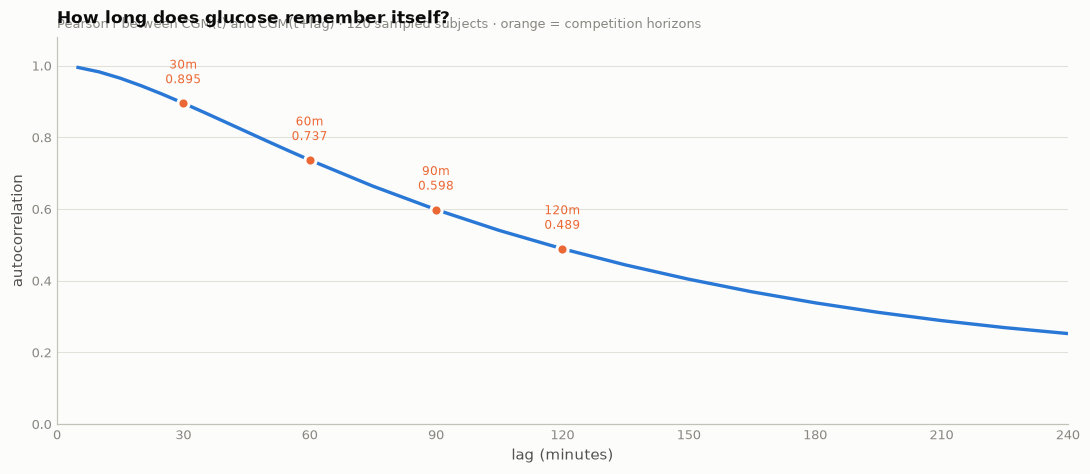

In [72]:
# Full autocorrelation curve out to 4 hours, on the subject sample (fast).
ss_cgm = SS["CGM"].to_numpy()
ks = list(range(1, 13)) + list(range(15, 49, 3))
ac = []
for k in ks:
    f = lead(ss_cgm, k, SS_BLK)
    m = np.isfinite(f) & np.isfinite(ss_cgm)
    ac.append(float(np.corrcoef(ss_cgm[m], f[m])[0, 1]))

fig, ax = plt.subplots(figsize=(9.8, 4.2))
mins = np.array(ks)*CFG["grid_min"]
ax.plot(mins, ac, color=SERIES[0], lw=2.2)
for h in CFG["horizons"]:
    i = ks.index(h//CFG["grid_min"])
    ax.scatter([h], [ac[i]], s=54, color=SERIES[1], zorder=4,
               edgecolor=SURFACE, linewidth=2)
    ax.annotate(f"{h}m\n{ac[i]:.3f}", (h, ac[i]), xytext=(0, 13),
                textcoords="offset points", fontsize=8, color=SERIES[1], ha="center")
ax.set_ylim(0, 1.08); ax.set_xlim(0, mins.max())
ax.set_xticks(range(0, 241, 30))
finish(ax, "How long does glucose remember itself?",
       f"Pearson r between CGM(t) and CGM(t+lag) · {len(SAMPLE_KEYS)} sampled subjects · "
       "orange = competition horizons",
       xlab="lag (minutes)", ylab="autocorrelation")
show()

---
## 10 · Relationships between columns

Row-level Pearson correlation on this corpus is close to useless and it is worth
saying why before showing it. Insulin and carbs are **spike trains** — 93 % and 98 %
exact zeros — so the instantaneous correlation between `carbs[t]` and `CGM[t]` is
dominated by the vast majority of slots where both sides are doing nothing. The
physiological effect is *lagged by 15–90 minutes and spread over hours*.

So this section does three things instead: a correlation matrix with the redundancy it
exposes (10.1), a **cross-correlation / event-triggered average** that recovers the
real dose-response shape (10.2), and subject-level comparisons where the unit of
analysis is a person (10.3).

### 10.1 · Correlation, and the redundancy it exposes

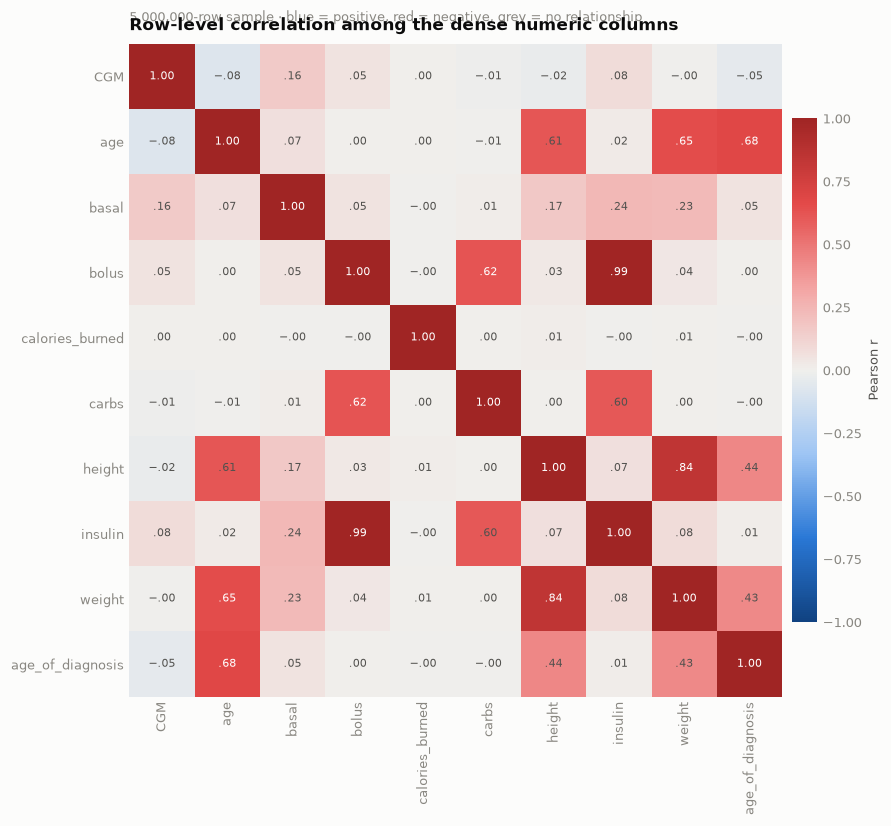

In [73]:
dense = [c for c in NUM if numstats.loc[c, "n"] / N_ROWS > 0.05]
cs = df.iloc[samp_idx][dense]
cmat = cs.corr()

fig, ax = plt.subplots(figsize=(8.6, 7.4))
im = ax.imshow(cmat.values, cmap=DIV_BR, vmin=-1, vmax=1)
ax.set_xticks(range(len(cmat)), cmat.columns, rotation=90, fontsize=8.4)
ax.set_yticks(range(len(cmat)), cmat.index, fontsize=8.4)
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
for i in range(len(cmat)):
    for j in range(len(cmat)):
        v = cmat.values[i, j]
        ax.text(j, i, f"{v:.2f}".replace("0.", ".").replace("-.", "−."),
                ha="center", va="center", fontsize=7.0,
                color="#ffffff" if abs(v) > 0.62 else INK2)
cb = fig.colorbar(im, ax=ax, pad=0.012, fraction=0.030)
cb.set_label("Pearson r", color=INK2, fontsize=8.5); cb.outline.set_visible(False)
ax.set_title("Row-level correlation among the dense numeric columns", loc="left")
ax.text(0, 1.03, f"{len(cs):,}-row sample · blue = positive, red = negative, "
                 "grey = no relationship", transform=ax.transAxes,
        fontsize=8.5, color=MUTED, va="bottom")
show()

In [74]:
pr = cmat.where(np.triu(np.ones(cmat.shape), 1).astype(bool)).stack()
pr = pr.reindex(pr.abs().sort_values(ascending=False).index)
print("strongest pairwise relationships\n" + "-"*62)
for (a, b), v in pr.head(12).items():
    print(f"  {v:+.4f}   {a:<22s} ~ {b}")

# The redundancy this hints at, checked exactly rather than by correlation.
m = df[["insulin", "basal", "bolus"]].notna().all(axis=1).to_numpy()
resid = (df["insulin"].to_numpy()[m] - df["basal"].to_numpy()[m] - df["bolus"].to_numpy()[m])
print(f"\ninsulin == basal + bolus ?")
print(f"   rows where all three are present : {m.sum():,}")
print(f"   max |insulin − (basal + bolus)|  : {np.abs(resid).max():.3e}  (float64 epsilon)")
print(f"   exact matches within 1e-9        : {(np.abs(resid) < 1e-9).mean()*100:.4f}%")
print("\n→ `insulin` is a perfectly redundant column. Keep basal and bolus (they behave")
print("  differently — one is a continuous background rate, the other a discrete event)")
print("  and drop `insulin`, or keep only `insulin` and drop the other two.")
del m, resid; gc.collect()

strongest pairwise relationships
--------------------------------------------------------------
  +0.9863   bolus                  ~ insulin
  +0.8361   height                 ~ weight
  +0.6787   age                    ~ age_of_diagnosis
  +0.6518   age                    ~ weight
  +0.6217   bolus                  ~ carbs
  +0.6137   age                    ~ height
  +0.6040   carbs                  ~ insulin
  +0.4356   height                 ~ age_of_diagnosis
  +0.4268   weight                 ~ age_of_diagnosis
  +0.2360   basal                  ~ insulin
  +0.2342   basal                  ~ weight
  +0.1696   basal                  ~ height

insulin == basal + bolus ?
   rows where all three are present : 134,035,414
   max |insulin − (basal + bolus)|  : 3.553e-15  (float64 epsilon)
   exact matches within 1e-9        : 100.0000%

→ `insulin` is a perfectly redundant column. Keep basal and bolus (they behave
  differently — one is a continuous background rate, the other a discre

71297

### 10.2 · What actually moves glucose: event-triggered averages

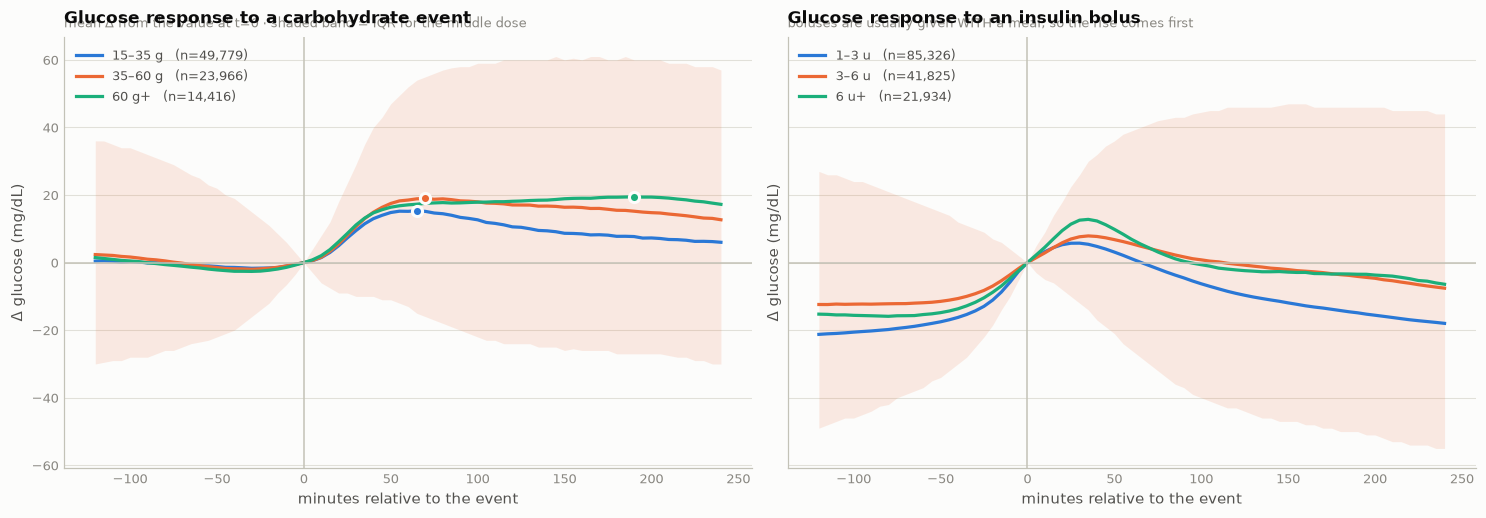

In [75]:
def event_response(trigger_mask, signal, blk, pre=24, post=48, max_events=200_000):
    """Average trajectory of `signal` in a window around each triggering row,
    baseline-subtracted at t=0. Windows that leave the contiguous block are dropped."""
    idx = np.flatnonzero(trigger_mask)
    if len(idx) > max_events:
        idx = RNG.choice(idx, max_events, replace=False); idx.sort()
    offs = np.arange(-pre, post+1)
    idx = idx[(idx >= pre) & (idx < len(signal)-post)]
    grid = idx[:, None] + offs[None, :]
    ok = (blk[grid] == blk[idx][:, None]).all(axis=1)      # stay inside one block
    grid = grid[ok]
    win = signal[grid]
    win = win - win[:, pre][:, None]                       # centre on the event
    return offs*CFG["grid_min"], np.nanmean(win, axis=0), \
           np.nanpercentile(win, 25, axis=0), np.nanpercentile(win, 75, axis=0), len(win)

ss_cgm   = SS["CGM"].to_numpy()
ss_carbs = SS["carbs"].to_numpy()
ss_bolus = SS["bolus"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(13.4, 4.6), sharey=True)

ax = axes[0]
for i, (lo, hi, lbl) in enumerate([(15, 35, "15–35 g"), (35, 60, "35–60 g"), (60, 200, "60 g+")]):
    t, mu, q1, q3, n = event_response((ss_carbs >= lo) & (ss_carbs < hi), ss_cgm, SS_BLK)
    ax.plot(t, mu, color=SERIES3[i], lw=2.1, label=f"{lbl}   (n={n:,})")
    if i == 1:
        ax.fill_between(t, q1, q3, color=SERIES3[i], alpha=0.13, linewidth=0)
    pk = int(np.nanargmax(mu))
    ax.scatter([t[pk]], [mu[pk]], s=44, color=SERIES3[i], zorder=4,
               edgecolor=SURFACE, linewidth=2)
ax.axvline(0, color=AXIS, lw=1.0); ax.axhline(0, color=AXIS, lw=1.0)
ax.legend(loc="upper left")
finish(ax, "Glucose response to a carbohydrate event",
       "mean Δ from the value at t=0 · shaded band = IQR for the middle dose",
       xlab="minutes relative to the event", ylab="Δ glucose (mg/dL)")

ax = axes[1]
for i, (lo, hi, lbl) in enumerate([(1, 3, "1–3 u"), (3, 6, "3–6 u"), (6, 30, "6 u+")]):
    t, mu, q1, q3, n = event_response((ss_bolus >= lo) & (ss_bolus < hi), ss_cgm, SS_BLK)
    ax.plot(t, mu, color=SERIES3[i], lw=2.1, label=f"{lbl}   (n={n:,})")
    if i == 1:
        ax.fill_between(t, q1, q3, color=SERIES3[i], alpha=0.13, linewidth=0)
ax.axvline(0, color=AXIS, lw=1.0); ax.axhline(0, color=AXIS, lw=1.0)
ax.legend(loc="upper left")
finish(ax, "Glucose response to an insulin bolus",
       "boluses are usually given WITH a meal, so the rise comes first",
       xlab="minutes relative to the event", ylab="Δ glucose (mg/dL)")
show()

This is the plot that justifies the entire feature-engineering strategy.

- **Carbohydrate**: glucose rises for roughly 45–75 minutes after the event and takes
  3–4 hours to return. Peak height scales with dose. That delay is *longer than the
  30-minute horizon and comparable to the 60–90 minute ones* — so a carb event that
  has already happened is genuinely predictive of the target.
- **Bolus**: the curve rises before it falls, which looks backwards until you remember
  that boluses are dosed *for* meals. The bolus channel is partly a proxy for "a meal
  is happening", and its pure pharmacodynamic effect is entangled with the carb
  effect. Do not read it as "insulin raises glucose".

Both curves are still climbing or falling at ±2 hours, which is why trailing windows
out to 24 hours and exponential IOB/COB decay kernels (half-lives ~55 and ~45 min) do
better than any single instantaneous value.

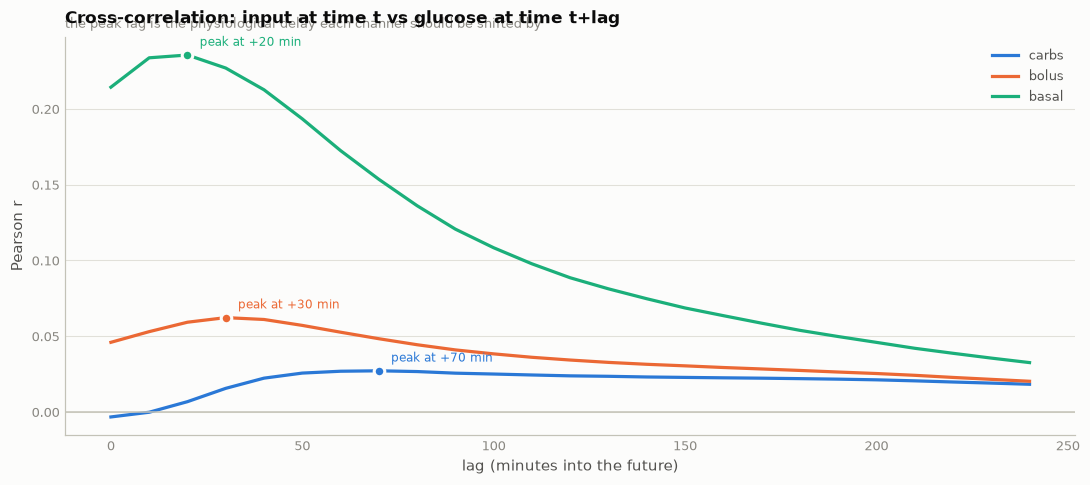

In [76]:
# Lagged cross-correlation: how far ahead of CGM do the input channels lead?
lags_k = list(range(0, 49, 2))
out = {}
for name, sig in [("carbs", ss_carbs), ("bolus", ss_bolus), ("basal", SS["basal"].to_numpy())]:
    xs = []
    for k in lags_k:
        fut = lead(ss_cgm, k, SS_BLK) if k > 0 else ss_cgm
        m = np.isfinite(fut) & np.isfinite(sig)
        xs.append(float(np.corrcoef(sig[m], fut[m])[0, 1]) if m.sum() > 1000 else np.nan)
    out[name] = xs

fig, ax = plt.subplots(figsize=(9.8, 4.3))
for i, (k, v) in enumerate(out.items()):
    ax.plot(np.array(lags_k)*CFG["grid_min"], v, color=SERIES3[i], lw=2.1, label=k)
    j = int(np.nanargmax(np.abs(v)))
    ax.scatter([lags_k[j]*CFG["grid_min"]], [v[j]], s=48, color=SERIES3[i], zorder=4,
               edgecolor=SURFACE, linewidth=2)
    ax.annotate(f"peak at +{lags_k[j]*CFG['grid_min']} min",
                (lags_k[j]*CFG["grid_min"], v[j]), xytext=(8, 6),
                textcoords="offset points", fontsize=8, color=SERIES3[i])
ax.axhline(0, color=AXIS, lw=1.0)
ax.legend(loc="upper right")
finish(ax, "Cross-correlation: input at time t vs glucose at time t+lag",
       "the peak lag is the physiological delay each channel should be shifted by",
       xlab="lag (minutes into the future)", ylab="Pearson r")
show()

### 10.3 · Subject-level comparisons

In [ ]:
sub = subjects[subjects.cgm_n > 5000].copy()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

ax = axes[0]
grp = [(m, sub[sub.insulin_delivery_modality == m].cgm_mean.dropna())
       for m in ["AID", "SAP", "MDI"]]
grp = [(m, v) for m, v in grp if len(v) >= 5]
bp = ax.boxplot([v for _, v in grp], tick_labels=[f"{m}\nn={len(v)}" for m, v in grp],
                widths=0.42, patch_artist=True, showfliers=False,
                medianprops=dict(color=INK, lw=1.6),
                boxprops=dict(facecolor=SERIES[0], alpha=0.30, edgecolor=SERIES[0], lw=1.2),
                whiskerprops=dict(color=AXIS, lw=1.1), capprops=dict(color=AXIS, lw=1.1))
for i, (m, v) in enumerate(grp, 1):
    ax.scatter(np.full(len(v), i) + RNG.normal(0, 0.055, len(v)), v, s=9,
               color=SERIES[0], alpha=0.35, linewidth=0, zorder=3)
ax.axhline(154, color=STATUS["good"], lw=1.0)
ax.text(0.55, 156, "≈ HbA1c 7%", fontsize=7.6, color=STATUS["good"])
finish(ax, "Mean glucose by delivery modality", "one point per subject",
       ylab="mean CGM (mg/dL)")

ax = axes[1]
v = sub.dropna(subset=["age", "cgm_mean"])
ax.scatter(v.age, v.cgm_mean, s=13, color=SERIES[0], alpha=0.40, linewidth=0)
z = np.polyfit(v.age, v.cgm_mean, 1)
xx = np.linspace(v.age.min(), v.age.max(), 50)
ax.plot(xx, np.polyval(z, xx), color=SERIES[1], lw=2.0)
r = v.age.corr(v.cgm_mean)
ax.annotate(f"r = {r:+.3f}\nslope {z[0]:+.2f} mg/dL per year",
            (xx[-1], np.polyval(z, xx[-1])), xytext=(-10, 16),
            textcoords="offset points", fontsize=8.2, color=SERIES[1], ha="right")
finish(ax, "Age vs mean glucose", f"{len(v):,} subjects",
       xlab="age (years)", ylab="mean CGM (mg/dL)")

ax = axes[2]
v = sub.dropna(subset=["tdd", "cgm_mean"])
v = v[(v.tdd > 0) & (v.tdd < v.tdd.quantile(.99))]
ax.scatter(v.tdd, v.cgm_mean, s=13, color=SERIES[0], alpha=0.40, linewidth=0)
finish(ax, "Total daily insulin vs mean glucose",
       f"r = {v.tdd.corr(v.cgm_mean):+.3f} · dose tracks body size, not control",
       xlab="total daily dose (units/day)", ylab="mean CGM (mg/dL)")
show()

print(sub.groupby("insulin_delivery_modality")[["cgm_mean", "cgm_cv", "gmi", "tdd"]]
        .agg(["count", "median"]).round(1).to_string())

---
## 11 · Train / test split geometry

`is_test` is a **row-level** flag, and that is the trap. 169 subjects appear on both
sides of it, split *temporally* — their earlier window is train, their later window is
test. A random row split, or even a naive `GroupKFold` on `id` alone, leaks.

### 11.1 · The geometry

In [78]:
geom = subjects.groupby("split").agg(
    subjects=("id", "size"), Mrows=("rows", lambda s: s.sum()/1e6),
    med_days=("days", "median"), med_cgm=("cgm_mean", "median"))
print(geom.round(1).to_string())
print(f"\nrow-level:  train {int((~df['is_test']).sum()):,}   test {int(df['is_test'].sum()):,}")
print(f"subject-level: {int((subjects.split=='train').sum()):,} train-only, "
      f"{int((subjects.split=='test').sum()):,} test-only, "
      f"{int((subjects.split=='both').sum()):,} split across both")
print(f"\n→ 'train subjects' = train-only + both = "
      f"{int((subjects.split!='test').sum()):,}")
print(f"→ 'test subjects'  = test-only  + both = "
      f"{int((subjects.split!='train').sum()):,}")
print(f"\nsanity: subject_split_across_traintest flag agrees with the derived split: "
      f"{(subjects.split_flag == (subjects.split=='both')).all()}")

       subjects  Mrows  med_days  med_cgm
split                                    
both        166   13.2     267.8    153.3
test        185   15.6     309.5    148.8
train      1556    126     277.9    153.1

row-level:  train 132,772,529   test 22,069,548
subject-level: 1,556 train-only, 185 test-only, 166 split across both

→ 'train subjects' = train-only + both = 1,722
→ 'test subjects'  = test-only  + both = 351

sanity: subject_split_across_traintest flag agrees with the derived split: True


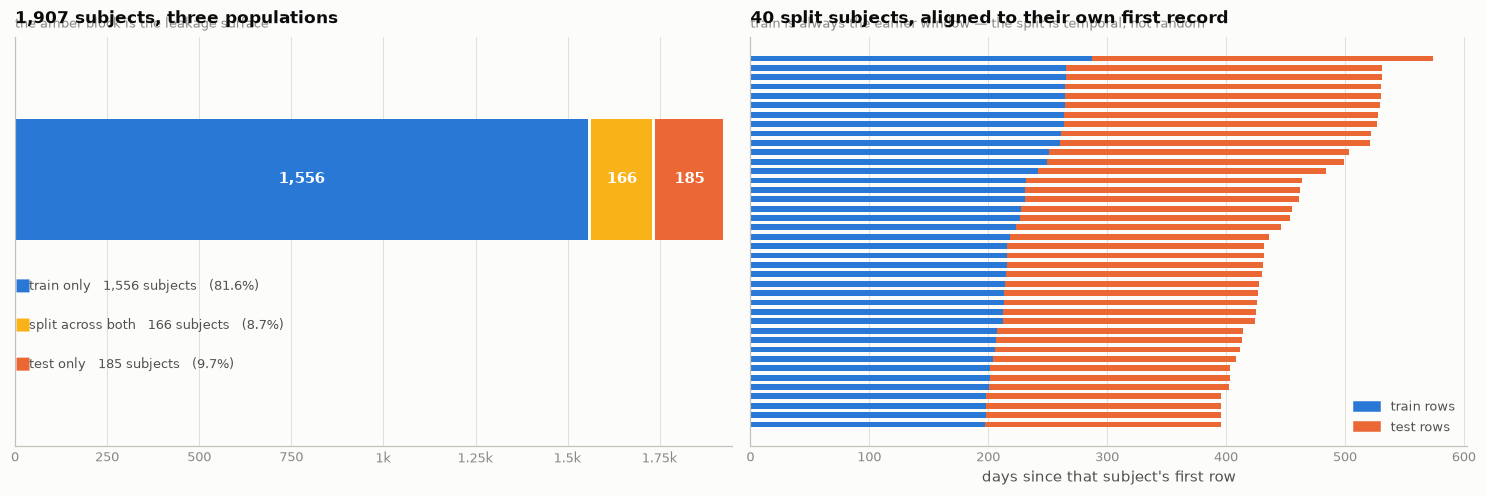

65063

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(13.4, 4.4))

ax = axes[0]
labels = ["train only", "split across both", "test only"]
vals   = [int((subjects.split == "train").sum()), int((subjects.split == "both").sum()),
          int((subjects.split == "test").sum())]
cols   = [SERIES[0], STATUS["warning"], SERIES[1]]
left = 0
for l, v, c in zip(labels, vals, cols):
    ax.barh([0], [v], left=left, height=0.34, color=c, linewidth=0)
    ax.text(left + v/2, 0, f"{v:,}", ha="center", va="center", fontsize=9.5,
            color="#ffffff", weight="600")
    left += v + 8                      # surface gap between segments
for i, (l, v, c) in enumerate(zip(labels, vals, cols)):
    ax.text(0, -0.30 - i*0.11, "■", color=c, fontsize=11, va="center")
    ax.text(38, -0.30 - i*0.11, f"{l}   {v:,} subjects   ({v/len(subjects)*100:.1f}%)",
            color=INK2, fontsize=8.8, va="center")
ax.set_ylim(-0.75, 0.4); ax.set_yticks([]); ax.set_xlim(0, sum(vals)*1.02)
ax.xaxis.set_major_formatter(KFMT)
finish(ax, "1,907 subjects, three populations",
       "the amber block is the leakage surface", xgrid=True, ygrid=False)

ax = axes[1]
both = subjects[subjects.split == "both"].nlargest(40, "rows")
keys = list(map(tuple, both[SUBJ_KEY].values))
bd = pull_subjects(keys)
for y, k in enumerate(keys):
    r = bd[(bd.source_file == k[0]) & (bd.id == k[1])]
    tr, te = r[~r.is_test], r[r.is_test]
    t0d = r.date.min()
    if len(tr):
        ax.barh(y, (tr.date.max()-t0d).total_seconds()/86400,
                left=(tr.date.min()-t0d).total_seconds()/86400,
                height=0.62, color=SERIES[0], linewidth=0)
    if len(te):
        ax.barh(y, (te.date.max()-te.date.min()).total_seconds()/86400,
                left=(te.date.min()-t0d).total_seconds()/86400,
                height=0.62, color=SERIES[1], linewidth=0)
ax.set_yticks([]); ax.invert_yaxis()
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=SERIES[0], label="train rows"),
                   Patch(color=SERIES[1], label="test rows")], loc="lower right")
finish(ax, "40 split subjects, aligned to their own first record",
       "train is always the earlier window — the split is temporal, not random",
       xlab="days since that subject's first row", xgrid=True, ygrid=False)
show()
del bd; gc.collect()

### 11.2 · Is the test set drawn from the same distribution?

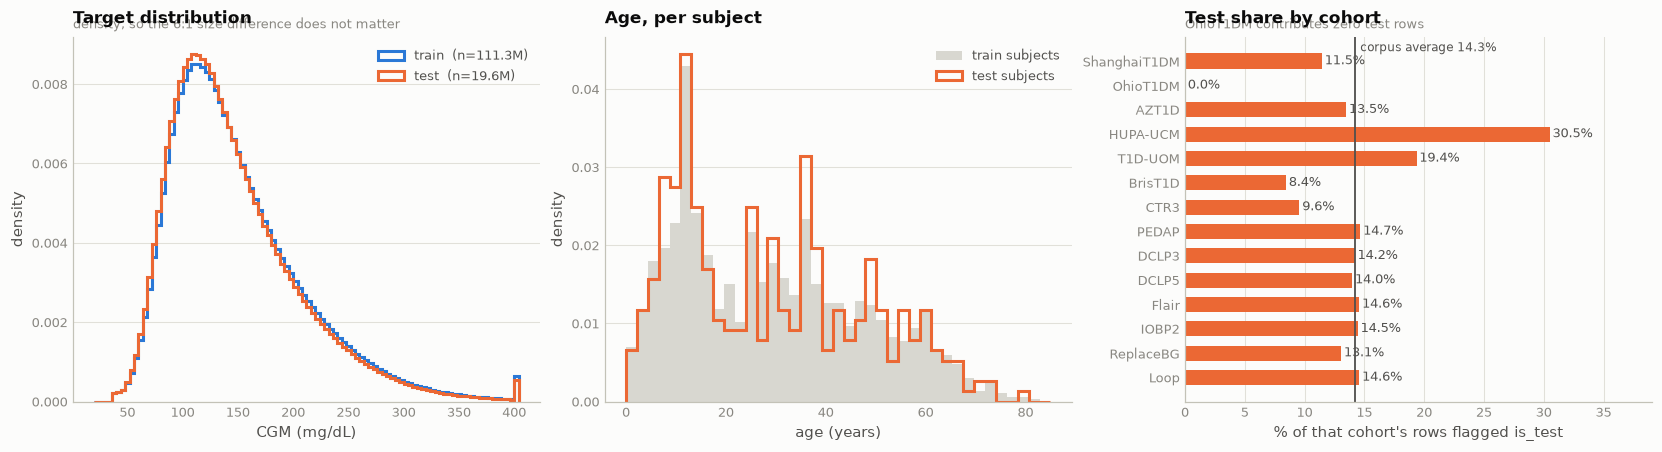

In [80]:
is_te = df["is_test"].to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.0))

ax = axes[0]
for lbl, m, col in [("train", ~is_te & HAS_CGM, SERIES[0]), ("test", is_te & HAS_CGM, SERIES[1])]:
    ax.hist(CGM[m], bins=np.arange(20, 405, 4), density=True, histtype="step",
            lw=2.0, color=col, label=f"{lbl}  (n={int(m.sum())/1e6:,.1f}M)")
ax.legend(loc="upper right")
finish(ax, "Target distribution", "density, so the 6:1 size difference does not matter",
       xlab="CGM (mg/dL)", ylab="density")

ax = axes[1]
tr = subjects[subjects.split != "test"]; te = subjects[subjects.split != "train"]
bins = np.linspace(0, 85, 40)
ax.hist(tr.age.dropna(), bins=bins, density=True, color=FADE, linewidth=0, label="train subjects")
ax.hist(te.age.dropna(), bins=bins, density=True, histtype="step", lw=2.0,
        color=SERIES[1], label="test subjects")
ax.legend(loc="upper right")
finish(ax, "Age, per subject", "", xlab="age (years)", ylab="density")

ax = axes[2]
comp = pd.crosstab(df["source_file"], df["is_test"], normalize="index")*100
comp = comp.reindex(cohort.index)
b = ax.barh(comp.index, comp[True], height=0.62, color=SERIES[1], linewidth=0)
ax.axvline(df["is_test"].mean()*100, color=INK2, lw=1.2)
ax.text(df["is_test"].mean()*100 + 0.4, len(comp)-0.6,
        f"corpus average {df['is_test'].mean()*100:.1f}%", fontsize=8, color=INK2)
ax.set_xlim(0, max(comp[True].max()*1.28, 22))
barh_labels(ax, b, [f"{v:.1f}%" for v in comp[True]])
finish(ax, "Test share by cohort", "OhioT1DM contributes zero test rows",
       xlab="% of that cohort's rows flagged is_test", xgrid=True, ygrid=False)
show()

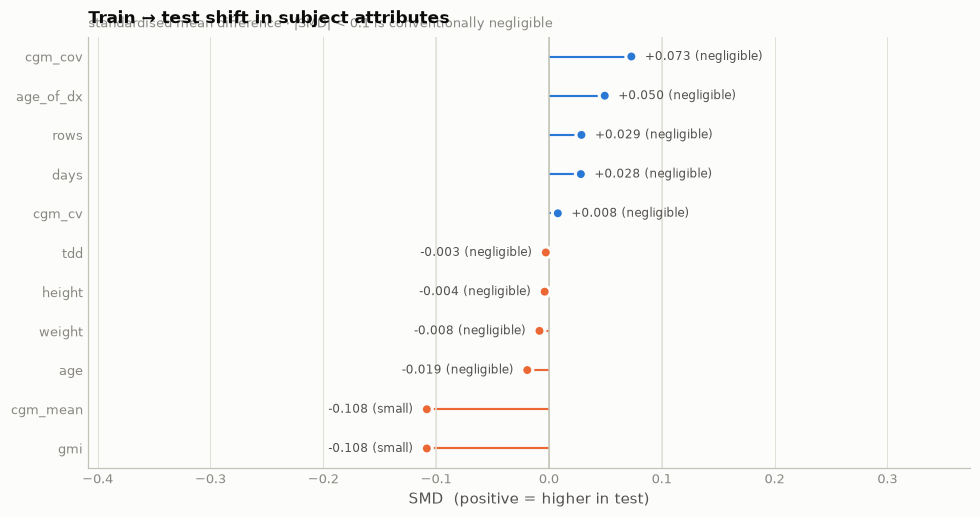

,train_mean,test_mean,smd,magnitude
attribute,,,,
age,29.26,28.91,-0.019,negligible
weight,145.4,144.9,-0.008,negligible
height,5.281,5.279,-0.004,negligible
age_of_dx,12.8,13.37,0.05,negligible
cgm_mean,153.6,151.2,-0.108,small
cgm_cv,36.17,36.21,0.008,negligible
cgm_cov,84.95,86.14,0.073,negligible
days,280.8,285,0.028,negligible
rows,8.085e+04,8.207e+04,0.029,negligible


In [81]:
# Quantified shift: standardised mean difference per subject-level attribute.
rows = []
for c in ["age", "weight", "height", "age_of_dx", "cgm_mean", "cgm_cv", "cgm_cov",
          "days", "rows", "tdd", "gmi"]:
    a, b = tr[c].dropna(), te[c].dropna()
    if len(a) < 10 or len(b) < 10:
        continue
    sd = math.sqrt((a.var() + b.var())/2)
    rows.append(dict(attribute=c, train_mean=a.mean(), test_mean=b.mean(),
                     smd=(b.mean()-a.mean())/sd if sd else np.nan))
shift = pd.DataFrame(rows).set_index("attribute")
shift["magnitude"] = pd.cut(shift.smd.abs(), [-.01, .1, .25, .5, 99],
                            labels=["negligible", "small", "moderate", "large"])

fig, ax = plt.subplots(figsize=(8.8, 4.6))
o = shift.sort_values("smd")
cols = [SERIES[0] if v >= 0 else SERIES[1] for v in o.smd]
ax.hlines(range(len(o)), 0, o.smd, color=cols, lw=1.4)
ax.scatter(o.smd, range(len(o)), s=52, color=cols, zorder=3,
           edgecolor=SURFACE, linewidth=2)
ax.axvline(0, color=AXIS, lw=1.0)
for x in (-0.1, 0.1):
    ax.axvline(x, color=GRID, lw=1.0)
ax.set_yticks(range(len(o)), o.index, fontsize=8.6)
for y, (v, m) in enumerate(zip(o.smd, o.magnitude)):
    ax.text(v + (0.012 if v >= 0 else -0.012), y, f"{v:+.3f} ({m})", va="center",
            ha="left" if v >= 0 else "right", fontsize=8, color=INK2)
ax.set_xlim(o.smd.min()-0.30, o.smd.max()+0.30)
finish(ax, "Train → test shift in subject attributes",
       "standardised mean difference · |SMD| < 0.1 is conventionally negligible",
       xlab="SMD  (positive = higher in test)", xgrid=True, ygrid=False)
show()
shift.round(3)

### 11.3 · The validation scheme this implies

Nothing here is catastrophic — the test split is a reasonable sample of the same
population — but the split geometry dictates how to build a local validation set:

1. **Split by `(source_file, id)`, never by row.** A random row split would put a
   subject's 10:00 and 10:05 readings on opposite sides, and with r = 0.99 at a
   5-minute lag that is near-total leakage.
2. **For the 169 dual-membership subjects, respect the time boundary too.** Their test
   rows are strictly later than their train rows. A held-out fold built from their
   *earlier* data is optimistic.
3. **Hold out whole cohorts occasionally.** Because null patterns identify the source
   study almost perfectly (section 3.3), subject-level CV can still reward
   cohort-specific shortcuts. A leave-one-cohort-out run is the honest check on
   generalisation.
4. **Weight by subject when reading validation scores.** `Loop` is 61 % of rows; a
   score dominated by `Loop` is not a score on the population.

---
## 12 · Data quality register

Every defect this notebook found, recomputed from scratch so nothing is asserted from
memory. Severity is about impact on modelling, not on tidiness.

In [82]:
checks = []
def check(sev, area, finding, value, action):
    checks.append(dict(severity=sev, area=area, finding=finding,
                       value=value, action=action))

# --- structural -----------------------------------------------------------------
n_broken = int((SAME & (delta != LATTICE_S)).sum())
check("HIGH", "temporal", "Subjects stored as >1 contiguous block; one runs backwards in time",
      f"{n_broken} lattice violations, 2 subjects", "Segment on BLK before any lag/rolling feature")
check("HIGH", "split", "Subjects present in BOTH train and test, split temporally",
      f"{int((subjects.split=='both').sum())} subjects", "Group-split by (source_file,id) AND respect the time boundary")
check("HIGH", "keys", "`id` is reused across cohorts",
      f"{int(df.groupby(SUBJ_KEY, observed=True).ngroups - df['id'].nunique())} collisions",
      "Always key on (source_file, id)")
check("HIGH", "missingness", "Null pattern near-uniquely identifies the source study",
      f"{len(sig)} cohorts, {int((~dup).sum())} uniquely identified",
      "Do not feed missingness indicators; validate leave-one-cohort-out")

# --- target ---------------------------------------------------------------------
check("HIGH", "target", "CGM is interval-censored at 40 and 400, inconsistently by cohort",
      f"{int((cgm_v==40).sum()):,} at 40, {int((cgm_v==400).sum()):,} at 400, "
      f"but {int((cgm_v<40).sum()):,} below and {int((cgm_v>400).sum()):,} above",
      "Treat as censored; consider a clipped loss")
check("MED", "target", "CGM missing in 15.5% of lattice slots, in long runs",
      f"{len(gap_min):,} gaps, max {gap_min.max()/1440:,.0f} days",
      "Never interpolate across long gaps; split into segments")

# --- redundancy / degeneracy ----------------------------------------------------
_m = df[["insulin", "basal", "bolus"]].notna().all(axis=1).to_numpy()
_r = (df["insulin"].to_numpy()[_m] - df["basal"].to_numpy()[_m] - df["bolus"].to_numpy()[_m])
check("MED", "redundancy", "`insulin` is exactly `basal + bolus`",
      f"max residual {np.abs(_r).max():.1e} over {_m.sum():,} rows", "Drop one side")
del _m, _r
check("LOW", "degeneracy", "`workout_intensity` has almost no data",
      f"{int(df['workout_intensity'].notna().sum())} non-null of {N_ROWS:,}", "Unusable; drop")
n99 = int((prof.null_pct > 99).sum())
check("MED", "degeneracy", f"{n99} columns are >99% null",
      f"{prof.loc[prof.null_pct>99,'mem_MB'].sum()/1000:,.1f} GB of stored NaN",
      "Drop corpus-wide; use only within the cohorts that have them")

# --- values ---------------------------------------------------------------------
neg_bolus = int((df["bolus"] < 0).sum())
check("LOW", "values", "Negative bolus values",
      f"{neg_bolus} rows, values "
      f"{np.unique(df.loc[df['bolus']<0,'bolus'].to_numpy())}", "Clip to 0 or drop")
cb = df["calories_burned"].dropna()
check("MED", "values", "Physiologically impossible calories in a 5-minute slot",
      f"{int((cb>500).sum()):,} rows >500 kcal, max {cb.max():,.0f}", "Winsorise at a physiological cap")
wd = df["workout_duration"].dropna()
check("LOW", "values", "Workout durations longer than a day",
      f"{int((wd>1440).sum())} rows, max {wd.max():,.0f} min ({wd.max()/1440:.1f} d)", "Cap or drop")
zt = int(((df["skin_temp"] == 0) | (df["galvanic_skin_response"] == 0)).sum())
check("LOW", "values", "Sensor-off encoded as literal 0 rather than NaN",
      f"{zt:,} rows across skin_temp / galvanic_skin_response", "Recode 0 → NaN")

# --- semantics ------------------------------------------------------------------
check("MED", "units", "Imperial and metric mixed across columns, undeclared",
      "height=feet, weight=pounds, skin_temp/air_temp=°F, CGM=mg/dL",
      "Convert explicitly before any derived feature")
check("MED", "labels", "Unnormalised free-text categorical levels",
      f"{int(audit.levels_removed.sum())} spurious levels across "
      f"{len(audit)} columns", "Normalise case/punctuation before encoding")
check("LOW", "labels", "`ethnicity` is a comma-joined multi-select, not a categorical",
      f"{df['ethnicity'].nunique()} stored combinations", "Explode to indicator columns")
check("LOW", "temporal", "Timestamps are shifted per study; max date is in the future",
      f"max {df['date'].max()}", "Use time-of-day and within-subject elapsed time only")

# --- confirmed CLEAN -------------------------------------------------------------
dupes = int(df.duplicated(subset=SUBJ_KEY + ["date"]).sum())
check("none", "clean", "No duplicate (source_file, id, date) rows", f"{dupes} duplicates", "—")
_m2 = df[["age", "age_of_diagnosis"]].notna().all(axis=1).to_numpy()
_bad = int((df["age_of_diagnosis"].to_numpy()[_m2] > df["age"].to_numpy()[_m2]).sum())
check("none", "clean", "No subject diagnosed after their recorded age", f"{_bad} violations", "—")
_pm = int(((df["is_pregnant"] == True) & (df["gender"] == "Male")).sum())
check("none", "clean", "No pregnancy flag on a male record", f"{_pm} violations", "—")
del _m2

register = pd.DataFrame(checks)
order = {"HIGH": 0, "MED": 1, "LOW": 2, "none": 3}
register = register.sort_values("severity", key=lambda s: s.map(order)).reset_index(drop=True)
register

,severity,area,finding,value,action
0,HIGH,temporal,Subjects stored as >1 contiguous block; one runs backwar...,"2 lattice violations, 2 subjects",Segment on BLK before any lag/rolling feature
1,HIGH,split,"Subjects present in BOTH train and test, split temporally",166 subjects,"Group-split by (source_file,id) AND respect the time bou..."
2,HIGH,keys,`id` is reused across cohorts,616 collisions,"Always key on (source_file, id)"
3,HIGH,missingness,Null pattern near-uniquely identifies the source study,"10226600 cohorts, 12 uniquely identified",Do not feed missingness indicators; validate leave-one-c...
4,HIGH,target,"CGM is interval-censored at 40 and 400, inconsistently b...","58,398 at 40, 121,909 at 400, but 117,707 below and 211,...",Treat as censored; consider a clipped loss
5,MED,target,"CGM missing in 15.5% of lattice slots, in long runs","1,147,210 gaps, max 636 days",Never interpolate across long gaps; split into segments
6,MED,redundancy,`insulin` is exactly `basal + bolus`,"max residual 3.6e-15 over 134,035,414 rows",Drop one side
7,MED,degeneracy,10 columns are >99% null,12.4 GB of stored NaN,Drop corpus-wide; use only within the cohorts that have ...
8,MED,labels,Unnormalised free-text categorical levels,16 spurious levels across 9 columns,Normalise case/punctuation before encoding
9,MED,values,Physiologically impossible calories in a 5-minute slot,"7,127 rows >500 kcal, max 21,726",Winsorise at a physiological cap


findfont: Failed to find font weight 600, now using 700.


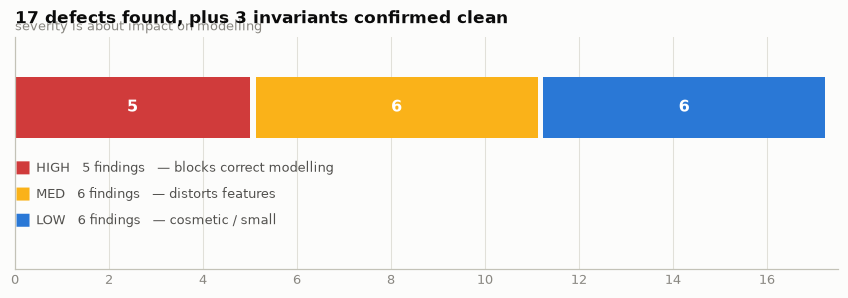


HIGH
  [temporal] Subjects stored as >1 contiguous block; one runs backwards in time
      observed : 2 lattice violations, 2 subjects
      action   : Segment on BLK before any lag/rolling feature
  [split] Subjects present in BOTH train and test, split temporally
      observed : 166 subjects
      action   : Group-split by (source_file,id) AND respect the time boundary
  [keys] `id` is reused across cohorts
      observed : 616 collisions
      action   : Always key on (source_file, id)
  [missingness] Null pattern near-uniquely identifies the source study
      observed : 10226600 cohorts, 12 uniquely identified
      action   : Do not feed missingness indicators; validate leave-one-cohort-out
  [target] CGM is interval-censored at 40 and 400, inconsistently by cohort
      observed : 58,398 at 40, 121,909 at 400, but 117,707 below and 211,234 above
      action   : Treat as censored; consider a clipped loss

MED
  [target] CGM missing in 15.5% of lattice slots, in long runs
     

In [83]:
cnt = register[register.severity != "none"].severity.value_counts()
cnt = cnt.reindex(["HIGH", "MED", "LOW"]).fillna(0).astype(int)
cols = [STATUS["critical"], STATUS["warning"], SERIES[0]]

fig, ax = plt.subplots(figsize=(7.6, 2.6))
left = 0
for (k, v), c in zip(cnt.items(), cols):
    ax.barh([0], [v], left=left, height=0.30, color=c, linewidth=0)
    ax.text(left + v/2, 0, str(v), ha="center", va="center", fontsize=10.5,
            color="#ffffff", weight="600")
    left += v + 0.12
for i, ((k, v), c) in enumerate(zip(cnt.items(), cols)):
    ax.text(0, -0.30 - i*0.13, "■", color=c, fontsize=11, va="center")
    ax.text(0.45, -0.30 - i*0.13,
            f"{k}   {v} finding{'s' if v != 1 else ''}   "
            f"— {'blocks correct modelling' if k=='HIGH' else 'distorts features' if k=='MED' else 'cosmetic / small'}",
            color=INK2, fontsize=8.8, va="center")
ax.set_ylim(-0.8, 0.35); ax.set_yticks([]); ax.set_xlim(0, cnt.sum()*1.03)
ax.xaxis.set_major_locator(MultipleLocator(2))
finish(ax, f"{int(cnt.sum())} defects found, plus "
           f"{int((register.severity=='none').sum())} invariants confirmed clean",
       "severity is about impact on modelling", xgrid=True, ygrid=False)
show()

for sev in ["HIGH", "MED", "LOW"]:
    print(f"\n{'='*94}\n{sev}\n{'='*94}")
    for _, r in register[register["severity"] == sev].iterrows():
        print(f"  [{r['area']}] {r['finding']}")
        print(f"      observed : {r['value']}")
        print(f"      action   : {r['action']}")

---
## 13 · Reconstructing the scored subset

The live leaderboard does **not** score the whole test split. It scores 2,648,987 rows
across 279 subjects and 9 cohorts, filtered so every sample has 24 h of history with no
CGM gap > 30 min, no long insulin outage, and at least one carb or meal event in the
window. `DCLP3`, `DCLP5`, `Flair` (no carb data) and `T1D-UOM` (MDI only) are excluded
outright.

That filter is not administrative trivia — **it is a statement about what the
competition rewards.** Excluding the cohorts without carb data guarantees that every
scored sample has a usable meal signal, so a CGM-only model is leaving signal on the
table by construction. The cell below approximates the filter and measures how much
the eligible population differs from the raw test split.

In [84]:
EXCLUDED = ["DCLP3", "DCLP5", "Flair", "T1D-UOM"]
HIST_H   = 24
hist_k   = HIST_H*60 // CFG["grid_min"]          # 288 slots of history

elig = (is_te
        & HAS_CGM
        & ~df["source_file"].isin(EXCLUDED).to_numpy())
print(f"test rows                              : {int(is_te.sum()):>12,}")
print(f"  with a CGM reading                   : {int((is_te & HAS_CGM).sum()):>12,}")
print(f"  after dropping {len(EXCLUDED)} cohorts           : {int(elig.sum()):>12,}")

# A sample is usable iff no CGM gap inside its 24h history exceeds 30 min (6 slots).
# `run_id` and `lens` from section 7.4 give every missing slot the length of the run
# it belongs to, so the trailing max of that array is the longest gap in the window.
lens_full = np.concatenate(([0], lens))
gap_at_row = np.where(missing, lens_full[run_id], 0).astype(np.int32)
max_gap_24h = (pd.Series(gap_at_row).rolling(hist_k, min_periods=hist_k)
                 .max().to_numpy())
have_hist = np.zeros(N_ROWS, bool)
have_hist[hist_k-1:] = BLK[hist_k-1:] == BLK[:N_ROWS-hist_k+1]

carbs_arr = df["carbs"].fillna(0).to_numpy()
carb_24h = (pd.Series((carbs_arr > 0).astype(np.int32))
              .rolling(hist_k, min_periods=1).sum().to_numpy())

usable = elig & have_hist & (max_gap_24h <= 6) & (carb_24h >= 1)
print(f"  with a full clean 24h of history     : {int((elig & have_hist & (max_gap_24h<=6)).sum()):>12,}")
print(f"  and ≥1 carb event in that window     : {int(usable.sum()):>12,}")
print(f"\nofficial scored subset (from the README): {2_648_987:>12,} rows / 279 subjects")
print(f"this approximation                     : {int(usable.sum()):>12,} rows / "
      f"{df.loc[usable].groupby(SUBJ_KEY, observed=True).ngroups:,} subjects")
print("\n(The official filter also constrains insulin outages and uses the organisers'")
print(" exact sampling stride, so this is a close upper bound, not a reproduction.)")

test rows                              :   22,069,548
  with a CGM reading                   :   19,560,193
  after dropping 4 cohorts           :   17,131,123
  with a full clean 24h of history     :   12,984,022
  and ≥1 carb event in that window     :    9,975,130

official scored subset (from the README):    2,648,987 rows / 279 subjects
this approximation                     :    9,975,130 rows / 220 subjects

(The official filter also constrains insulin outages and uses the organisers'
 exact sampling stride, so this is a close upper bound, not a reproduction.)


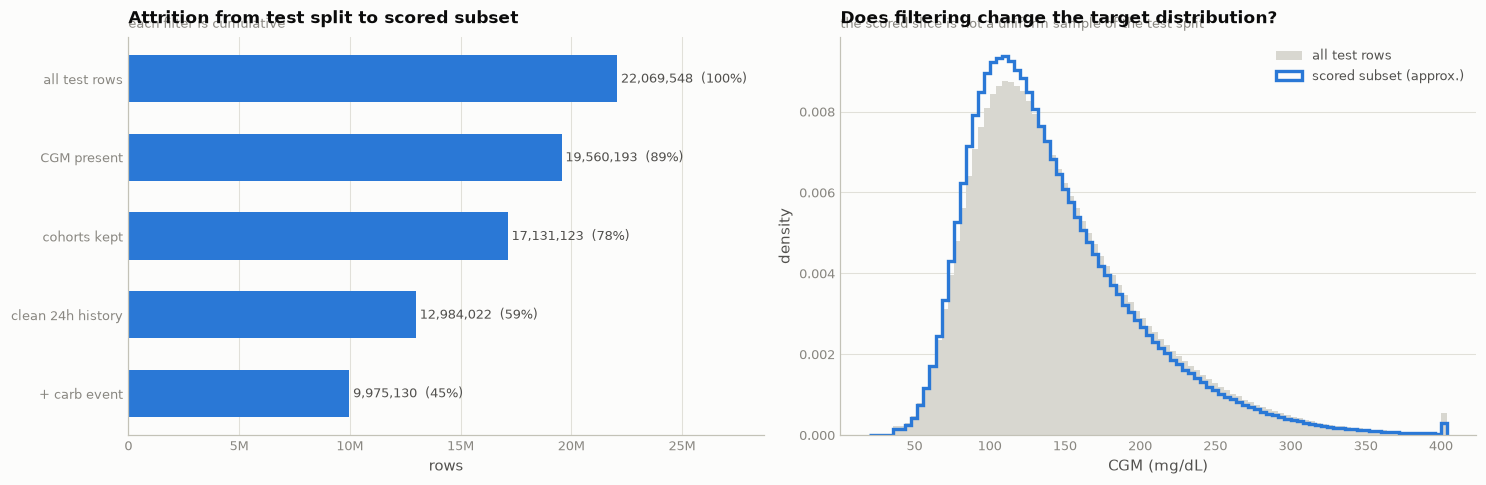

                          all test      scored
mean                        145.64      141.17
median                      133.00      129.00
sd                           58.36       55.55
TIR 70–180                  73.57%      76.19%
% below 70                   3.47%       3.43%


In [85]:
fig, axes = plt.subplots(1, 2, figsize=(13.4, 4.3))

ax = axes[0]
stages = ["all test rows", "CGM present", "cohorts kept", "clean 24h history", "+ carb event"]
vals = [int(is_te.sum()), int((is_te & HAS_CGM).sum()), int(elig.sum()),
        int((elig & have_hist & (max_gap_24h <= 6)).sum()), int(usable.sum())]
bars = ax.barh(stages[::-1], vals[::-1], height=0.60, color=SERIES[0], linewidth=0)
ax.set_xlim(0, max(vals)*1.30)
ax.xaxis.set_major_formatter(KFMT)
barh_labels(ax, bars, [f"{v:,}  ({v/vals[0]*100:.0f}%)" for v in vals[::-1]])
finish(ax, "Attrition from test split to scored subset",
       "each filter is cumulative", xlab="rows", xgrid=True, ygrid=False)

ax = axes[1]
for lbl, m, col in [("all test rows", is_te & HAS_CGM, FADE),
                    ("scored subset (approx.)", usable, SERIES[0])]:
    ax.hist(CGM[m], bins=np.arange(20, 405, 4), density=True,
            color=col if col == FADE else None,
            histtype="stepfilled" if col == FADE else "step",
            lw=0 if col == FADE else 2.2, edgecolor=col, label=lbl)
ax.legend(loc="upper right")
finish(ax, "Does filtering change the target distribution?",
       "the scored slice is not a uniform sample of the test split",
       xlab="CGM (mg/dL)", ylab="density")
show()

a, b = CGM[is_te & HAS_CGM], CGM[usable]
print(f"{'':<22}{'all test':>12}{'scored':>12}")
for name, f in [("mean", np.mean), ("median", np.median), ("sd", np.std)]:
    print(f"{name:<22}{f(a):>12.2f}{f(b):>12.2f}")
print(f"{'TIR 70–180':<22}{((a>=70)&(a<=180)).mean()*100:>11.2f}%"
      f"{((b>=70)&(b<=180)).mean()*100:>11.2f}%")
print(f"{'% below 70':<22}{(a<70).mean()*100:>11.2f}%{(b<70).mean()*100:>11.2f}%")

In [86]:
# What does persistence score on the eligible slice, vs the whole corpus?
print(f"{'horizon':>8} {'MARD all corpus':>18} {'MARD scored slice':>20}")
for h in CFG["horizons"]:
    k = h//CFG["grid_min"]
    fut = lead(CGM, k)
    m = usable & np.isfinite(fut) & np.isfinite(CGM) & (fut > 0)
    v = float(np.mean(np.abs(CGM[m]-fut[m])/fut[m])*100)
    print(f"{h:>6} m {base.loc[h,'MARD_persistence']:>17.2f}% {v:>19.2f}%")
    del fut, m; gc.collect()

 horizon    MARD all corpus    MARD scored slice
    30 m             14.03%               13.52%
    60 m             22.71%               21.82%
    90 m             28.41%               27.10%
   120 m             32.32%               30.66%


---
## 14 · Findings

### The five that change what you build

1. **The lattice is already dense — and it has two holes.** 154,840,166 of
   154,840,168 adjacent within-subject row pairs are exactly 5 minutes apart, so
   `shift(k)` *is* a lag of `5k` minutes. But two ShanghaiT1DM subjects are stored as
   two concatenated wear periods, one of them out of chronological order. Segment on
   contiguous blocks (`BLK`) before taking any lag, or you will compute a "5-minute
   delta" across a 39.7-day backwards jump.

2. **Missingness encodes cohort identity almost perfectly.** Of the 14 source studies,
   nearly all have a unique >50 %-null signature. Any feature derived from which
   columns are present is a shortcut to "which study is this", and cohorts differ in
   population (paediatric, pregnancy, MDI, closed-loop). Validate leave-one-cohort-out,
   not just leave-one-subject-out.

3. **Gaps are NaN runs, and the time lost is in the long ones.** 83 % of gaps are
   ≤ 30 min but they hold only 6.6 % of the missing time; the largest single gap is
   over three years. Interpolating short dropout is fine; interpolating across a long
   gap fabricates data.

4. **The target is censored at both ends, inconsistently.** Sensors clamp at 40 and
   400 in some cohorts and pass raw values through in others. Because MARD divides by
   the true value, error at a clamped low of 40 costs ten times what the same absolute
   error costs at 400 — the hypoglycaemic tail dominates the metric despite being ~4 %
   of readings.

5. **Persistence is the number to beat, and it is not weak.** Predicting "glucose
   stays where it is" scores MARD ≈ 14.0 / 22.7 / 28.4 / 32.3 % at 30 / 60 / 90 /
   120 minutes across the whole corpus. Linear extrapolation of the current trend is
   *worse* at every horizon — glucose mean-reverts.

### Everything else, condensed

| Finding | Where | Implication |
|---|---|---|
| 61 GB resident from 1.36 GB on disk; ~20 GB is stored NaN in >99 %-null columns | 1, 2.1 | Load a column subset for modelling |
| `id` is not unique — real key is `(source_file, id)` | 8.1 | Group and split on the pair |
| 169 subjects sit on both sides of `is_test`, split temporally | 11.1 | Group-split *and* respect the time boundary |
| `insulin` ≡ `basal + bolus` exactly | 10.1, 12 | Drop one side |
| `bolus` 93 % zeros, `carbs` 98 % zeros | 5.4 | Model as a marked point process: window sums + decay kernels |
| Carb effect peaks 45–75 min out and lasts 3–4 h | 10.2 | Lagged carb features beat instantaneous ones at every horizon |
| Diurnal swing is 15–25 mg/dL, comparable to 30-min error | 9.4 | Encode time-of-day cyclically |
| Units mix feet / pounds / °F / mg-dL undeclared | 5.7 | Convert before any derived feature |
| Free-text levels unnormalised (`Humalog` vs `humalog` vs `Humalog (Lispro)`) | 6.3 | Normalise before encoding |
| `workout_intensity` has 219 non-null values in 154 M rows | 5.1, 12 | Drop |
| Timestamps shifted per study; max date is in the future | 7.2 | Never use absolute calendar time |
| The scored subset excludes 4 cohorts and requires a carb event in the window | 13 | A CGM-only model is leaving signal on the table by design |

### Recommended next steps

1. Build a **segment table** — one row per contiguous, gap-free-enough stretch of a
   subject — and make it the unit that lag features are computed within.
2. Drop `insulin`, `workout_intensity`, and the >99 %-null columns from the modelling
   frame; keep the wearable channels only for the cohorts that actually have them.
3. Replace instantaneous `carbs` / `bolus` / `basal` with trailing window sums and
   exponential IOB/COB kernels, per the response curves in 10.2.
4. Set up leave-one-cohort-out validation alongside subject-level CV, and report scores
   weighted per subject rather than per row.
5. Benchmark against the persistence numbers in 9.6 before trusting any model.

In [87]:
print(f"""
{'='*78}
MetaboNet public corpus — EDA summary
{'='*78}
  rows                     {N_ROWS:>16,}
  columns                  {N_COLS:>16,}
  subjects (source_file,id){df.groupby(SUBJ_KEY, observed=True).ngroups:>16,}
  contiguous blocks        {BLK.max():>16,}
  source cohorts           {df['source_file'].nunique():>16,}
  date range               {str(df['date'].min())[:10]:>16} → {str(df['date'].max())[:10]}
  on disk / resident       {DISK_GB:>13.2f} GB / {MEM_GB:.2f} GB

  CGM readings             {int(HAS_CGM.sum()):>16,}  ({HAS_CGM.mean()*100:.2f}% of slots)
  mean glucose             {np.nanmean(CGM):>16.2f}  mg/dL
  time in range 70–180     {((cgm_v>=70)&(cgm_v<=180)).mean()*100:>16.2f}%
  CGM gaps                 {len(gap_min):>16,}  (median {np.median(gap_min):,.0f} min)

  train / test rows        {int((~is_te).sum()):>16,} / {int(is_te.sum()):,}
  train-only / test-only / both subjects
                           {int((subjects.split=='train').sum()):>16,} / """
f"""{int((subjects.split=='test').sum()):,} / {int((subjects.split=='both').sum()):,}

  persistence MARD @ 30/60/90/120 min
                           {base.loc[30,'MARD_persistence']:.2f}% / """
f"""{base.loc[60,'MARD_persistence']:.2f}% / {base.loc[90,'MARD_persistence']:.2f}% / """
f"""{base.loc[120,'MARD_persistence']:.2f}%

  quality findings         {int((register.severity=='HIGH').sum())} high · """
f"""{int((register.severity=='MED').sum())} medium · {int((register.severity=='LOW').sum())} low · """
f"""{int((register.severity=='none').sum())} invariants confirmed clean
{'='*78}
""")


MetaboNet public corpus — EDA summary
  rows                          154,842,077
  columns                                37
  subjects (source_file,id)           1,907
  contiguous blocks                   1,909
  source cohorts                         14
  date range                     2011-11-17 → 2027-07-14
  on disk / resident                1.36 GB / 60.64 GB

  CGM readings                  130,872,839  (84.52% of slots)
  mean glucose                       148.18  mg/dL
  time in range 70–180                72.33%
  CGM gaps                        1,147,210  (median 5 min)

  train / test rows             132,772,529 / 22,069,548
  train-only / test-only / both subjects
                                      1,556 / 185 / 166

  persistence MARD @ 30/60/90/120 min
                           14.03% / 22.71% / 28.41% / 32.32%

  quality findings         5 high · 6 medium · 6 low · 3 invariants confirmed clean

